# Tabroll para cualquier cancion de Angine de Poitrine

Extensiones de audio permitidas: `.mp3`, `.wav`, `.flac`, `.ogg`, `.m4a`.

Este análisis incluye:

- Seguimiento del **pulso real** de la grabación
- Extrae la línea melódica dominante y el bajo (con rejilla de cuartos de tono para no perder la microtonalidad)
- Detecta la tonalidad y el modo, estima cuántos pulsos dura **cada compás** (2, 3, 4, 7...) y propone un acorde por pulso.
- el renderizador incluido en este cuaderno lo dibuja como TheoryTab: una fila por grado de la escala, notas microtonales rayadas, tira de acordes con numerales romanos y, arriba de cada compás, su número de pulsos.

- El gráfico cubre **toda la canción**, repartida en páginas (una imagen cada ~21 pulsos). Cambiar `BEATS_PER_PAGE` o `VIEW_SECONDS` en la última celda, o usar `render_song_graphic(start_s=..., duration_s=...)` para ver solo una sección.


In [91]:
!pip -q install librosa matplotlib

In [92]:
# @title 0) Librerias
from __future__ import annotations

from pathlib import Path
import zipfile

import math
import re
from bisect import bisect_left, bisect_right
from dataclasses import dataclass, field, replace
from typing import Optional, Sequence

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import to_hex, to_rgb
from matplotlib.patches import FancyBboxPatch, Polygon, Rectangle

import numpy as np
from numpy.lib.stride_tricks import sliding_window_view
from scipy.signal import find_peaks
from scipy.ndimage import uniform_filter1d, median_filter, maximum_filter1d

import librosa
from collections import Counter
from IPython.display import display

from PIL import Image
from IPython.display import Image as IPyImage, display

**`name_key`**: Normaliza nombres quitando mayúsculas y tildes. **`find_song`**: Busca y selecciona un audio en la carpeta del proyecto, ignorando stems y archivos ocultos; con `SONG` elige la coincidencia, y con `None` el audio más reciente.


In [93]:
# @title 1) Elegir el audio

SONG = None                                   # parte del nombre de la canción, sin importar mayúsculas ni tildes (por ejemplo 'Fabienk'); None = el audio más reciente
AUDIO_FOLDER = 'Angine de Poitrine Audios'    # carpeta de los audios, en la raíz del proyecto

import unicodedata

try:
    from google.colab import files
    IN_COLAB_HARMONY = True

except ImportError:
    IN_COLAB_HARMONY = False

BASE_DIR = Path('/content') if IN_COLAB_HARMONY else next((d for d in (Path.cwd(), *Path.cwd().parents) if (d / 'pyproject.toml').is_file()), Path.cwd())   # raíz del proyecto
AUDIO_DIR = BASE_DIR / AUDIO_FOLDER if (BASE_DIR / AUDIO_FOLDER).is_dir() else (BASE_DIR if IN_COLAB_HARMONY else Path.cwd())

if IN_COLAB_HARMONY:
    print('Sube la canción y, si las tienes, sus pistas _guitar y _bass de Demucs.')

    for filename, data in files.upload().items():
        (AUDIO_DIR / filename).write_bytes(data)

audio_ext = {'.mp3','.wav','.flac','.ogg','.m4a','.aiff','.aif'}
is_stem = lambda p: re.search(r'(^|_)(guitar|bass|other|drums|vocals|piano)( \(\d+\))?$', p.stem.lower())


def name_key(text):
    return ''.join(ch for ch in unicodedata.normalize('NFKD', str(text).casefold()) if not unicodedata.combining(ch))


def find_song(folder, song=None):
    found = sorted((p for p in folder.rglob('*') if p.is_file() and not p.name.startswith('.') and p.suffix.lower() in audio_ext and not is_stem(p)),
                   key=lambda p: name_key(p.relative_to(folder)))

    if not found:
        raise FileNotFoundError(f'No hay audios MP3, WAV, FLAC, OGG, M4A o AIFF en {folder}.')

    if song is None:
        return max(found, key=lambda p: p.stat().st_mtime), found

    key = name_key(song)
    hits = [p for p in found if key in name_key(p.relative_to(folder))]
    hits = [p for p in hits if key in (name_key(p.name), name_key(p.stem))] or hits                       # el nombre exacto gana

    if len(hits) > 1:
        hits = [p for p in hits if re.search(r'off?ici(al|el)', name_key(p.stem))] or hits                  # entre las versiones de una canción, el audio oficial

    if len(hits) > 1:
        preferred = [p for p in hits if name_key(p.stem).startswith(key) and 'official audio' in name_key(p.stem)]
        hits = preferred if len(preferred) == 1 else hits

    if len(hits) != 1:
        listed = '\n  '.join(str(p.relative_to(folder)) for p in (hits or found))
        raise FileNotFoundError(f"'{song}' " + ('coincide con varios audios; escribe más del nombre:' if hits else f'no coincide con ningún audio de {folder.name}. Hay:') + f'\n  {listed}')

    return hits[0], found


audio_path, audio_candidates = find_song(AUDIO_DIR, SONG)

print(f'Audios en {AUDIO_DIR}:')
for p in audio_candidates[:40]:
    print(('  → ' if p == audio_path else '    ') + str(p.relative_to(AUDIO_DIR)))

if len(audio_candidates) > 40:
    print(f'    ... y {len(audio_candidates) - 40} más')

if SONG is None and len(audio_candidates) > 1:
    print("Es el más reciente. Para elegir otro, escribe parte de su nombre en SONG, por ejemplo SONG = 'Fabienk'.")

print(f'Audio seleccionado: {audio_path.name}')


Sube la canción y, si la tienes, su pista guitar de Demucs.


Saving Angine de Poitrine - Sarniezz (audio officiel).mp3 to Angine de Poitrine - Sarniezz (audio officiel) (1).mp3
Audio seleccionado: Angine de Poitrine - Sarniezz (audio officiel) (1).mp3


In [ ]:
# @title 1b) Separar guitarra y bajo con Demucs


**`find_stem`**: Busca en la carpeta de audios, y en sus subcarpetas, la pista de un instrumento de la canción elegida. Para `Canción.mp3` busca un archivo que empiece por `Canción_guitar` o `Canción_bass`, sin importar mayúsculas ni tildes. Si hay varias, prefiere la que está en la misma carpeta que la canción y, entre esas, la más reciente. Si no encuentra ninguna, devuelve `None`.


In [ ]:
def find_stem(audio, kind):
    key = name_key(f'{audio.stem}_{kind}')
    hits = [p for p in AUDIO_DIR.rglob('*') if p.is_file() and not p.name.startswith('.') and p.suffix.lower() in audio_ext and name_key(p.stem).startswith(key)]

    return max(hits, key=lambda p: (p.parent == audio.parent, p.stat().st_mtime)) if hits else None


separate_stems: separa la canción con la red neuronal Demucs (modelo htdemucs_6s, el que tiene pista de guitarra) y guarda la guitarra y el bajo como Canción_guitar.mp3 y Canción_bass.mp3 junto a la canción. La primera vez instala demucs-infer y descarga el modelo.

In [ ]:
def separate_stems(audio, kinds=('guitar', 'bass'), model_name='htdemucs_6s'):
    if importlib.util.find_spec('demucs_infer') is None:
        subprocess.run([sys.executable, '-m', 'pip', '-q', 'install', 'demucs-infer'], check=True)

    import torch
    from demucs_infer.pretrained import get_model
    from demucs_infer.apply import apply_model
    from demucs_infer.audio import AudioFile

    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    print(f'Separando {audio.name} con {model_name} ({device})' + ('' if device == 'cuda' else '; sin GPU tarda varios minutos'))

    model = get_model(model_name); model.eval()
    wav = AudioFile(str(audio)).read(streams=0, samplerate=model.samplerate, channels=model.audio_channels)
    ref = wav.mean(0)
    wav = (wav - ref.mean()) / ref.std()                                                   # la misma normalización que usa Demucs

    with torch.no_grad():
        out = apply_model(model, wav[None], device=device)[0].cpu()
    out = out * ref.std() + ref.mean()

    paths = {}
    for kind in kinds:
        x = np.ascontiguousarray(out[model.sources.index(kind)].numpy().T, dtype=np.float32)       # (muestras, canales)
        paths[kind] = audio.with_name(f'{audio.stem}_{kind}.mp3')
        subprocess.run(['ffmpeg', '-v', 'error', '-y', '-f', 'f32le', '-ar', str(model.samplerate), '-ac', str(x.shape[1]),
                        '-i', '-', '-b:a', '192k', str(paths[kind])], input=x.tobytes(), check=True)

    return paths

Separar guitarra y bajo: si junto con la canción no subiste sus pistas _guitar y _bass, Demucs las saca del mismo audio y las descarga para que la próxima vez las subas con la canción y no haya que separar de nuevo. Con SEPARATE = False el análisis usa solo la mezcla.

In [ ]:
SEPARATE = True          # False = no separar; usa solo las pistas _guitar y _bass que hayas subido con la canción
DOWNLOAD_STEMS = True    # descarga las pistas para subirlas la próxima vez y no tener que separar de nuevo

import importlib.util, subprocess, sys

GUITAR_STEM, BASS_STEM = find_stem(audio_path, 'guitar'), find_stem(audio_path, 'bass')

if SEPARATE and not (GUITAR_STEM and BASS_STEM):
    stems = separate_stems(audio_path)
    GUITAR_STEM, BASS_STEM = stems['guitar'], stems['bass']

    if DOWNLOAD_STEMS and IN_COLAB_HARMONY:
        for p in stems.values():
            files.download(str(p))

print(f'Pista de guitarra: {GUITAR_STEM.name if GUITAR_STEM else "ninguna"}')
print(f'Pista de bajo: {BASS_STEM.name if BASS_STEM else "ninguna"}')

## Objetivo

Construimos un "piano roll" heurístico de grados de escala al estilo "TheoryTab" compatible con cualquier afinación.

### Idea:

- Los tonos se guardan en cents sobre la tónica (float): Esto permite usar cualquier sistema (12-TET, 31-EDO, entonación justa, maqam, Bohlen-Pierce) usando diferentes valores decimales.

- Una Scale define los cents de cada grado en un periodo. La función Scale.row(cents) asigna los cents a filas; los valores enteros son los grados de la escala. Las notas fuera de la escala quedan en filas fraccionarias intermedias y se dibujan con líneas de los colores de ambos grados vecinos.

- El tiempo se mide en pulsos. Los compases pueden tener cualquier duración (ej. 4 pulsos, luego 2 y asi).

### Capas de renderizado:

paneles de compás

-> bandas de fila por color de grado

-> cuadrícula de pulsos y líneas de acento

-> notas

-> barra de acordes (barras de color + números romanos)

-> nombres de acordes

-> pestañas de encabezado ("4 pulsos")

-> etiquetas de ejes

-> línea de reproducción (en construccion).


**`mix`**, **`lighten`** y **`palette`**: Mezclan dos colores, aclaran un color y generan una paleta de `n` colores a partir de la de Hooktheory.

In [94]:
plt.rcParams["mathtext.fontset"] = "dejavuserif"

BG = "#131215"
GOLD = "#e0a03a"

# Usamos la paleta de color de Hooktheory.com: grados 1, ..., 7
HT_COLORS = ["#9d6229", "#a69837", "#68ac38", "#468fb4", "#832fb6", "#992597", "#992e1f"]
ROMAN = ["I", "II", "III", "IV", "V", "VI", "VII", "VIII", "IX", "X", "XI", "XII"]


# colores
def mix(c1: str, c2: str, t: float) -> str:
    a, b = to_rgb(c1), to_rgb(c2)
    return to_hex(tuple(x + (y - x) * t for x, y in zip(a, b)))


def lighten(c: str, t: float = 0.3) -> str:
    return mix(c, "#ffffff", t)


def palette(n: int) -> list[str]:
    out = []
    for i in range(n):
        p = i * 7 / n
        k = int(p)
        out.append(mix(HT_COLORS[k % 7], HT_COLORS[(k + 1) % 7], p - k))
    return out


**`accidental`**: Alteración de `k` pasos. Usa ♯ y ♭ cuando un paso equivale a un semitono (12-TET); en otra afinación usa flechas ↑ y ↓, y cada flecha equivale a un paso.

In [95]:
# afinacion
def accidental(k: int, unit: float) -> str:

    if k == 0:
        return ""
    sharp, flat = ("♯", "♭") if abs(unit - 100) < 1e-6 else ("↑", "↓")
    if abs(k) > 3:
        return f"{sharp if k > 0 else flat}{abs(k)}"
    return (sharp if k > 0 else flat) * abs(k)

**`Scale`**: Escala musical en cents.

Campos:

- `steps`: cents de cada grado sobre la tónica (`steps[0] == 0`).
- `period`: periodo de la escala; `1200` = octava, `1901.955` = tritava (Bohlen-Pierce).
- `names`: nombres de las notas para el eje izquierdo.
- `tonic_octave`: etiqueta de la octava a la que corresponde la "octava 0".
- `accidental_unit`: cents por cada paso de alteración (`1200/edo` en un EDO).
- `tol`: distancia máxima en cents para considerar que una altura está sobre un grado.
- `tuning`: todas las alturas de la afinación en un periodo (líneas fantasma).

Métodos:

- `from_tuning`: elige una escala dentro de una afinación completa (por ejemplo, un archivo Scala); los grados son índices de esa afinación.
- `pitch`: cents de un grado (desde 1) en una octava dada, con desplazamiento opcional de `shift` cents.
- `deg_cents`: cents del índice de grado absoluto `k` (coordenada de fila; puede ser negativo).
- `row`: coordenada continua de fila; los enteros son grados de la escala (fila 0 = tónica, octava 0).
- `locate`: devuelve `(fila, sobre_un_grado)`; ajusta a la fila entera si está a `tol` cents o menos.
- `colors_for`: devuelve `(color_inferior, color_superior, fracción)`; con fracción 0 se usa el color del grado.
- `spell`: devuelve `(índice de grado absoluto más cercano, alteración)`; en un empate se elige el sostenido del grado inferior.

In [96]:
from dataclasses import dataclass
from typing import Optional
import numpy as np

@dataclass
class Scale:
    steps: list[float]
    period: float = 1200.0
    names: Optional[list[str]] = None
    tonic_name: str = "C"
    tonic_octave: int = 4
    accidental_unit: float = 100.0
    colors: Optional[list[str]] = None
    tol: float = 12.0
    tuning: Optional[list[float]] = None
    degrees: Optional[list[str]] = None

    def __post_init__(self):
        assert abs(self.steps[0]) < 1e-9 and sorted(self.steps) == list(self.steps)
        assert self.steps[-1] < self.period
        if self.colors is None:
            self.colors = palette(self.n)

    @property
    def n(self) -> int:
        return len(self.steps)

    # helpers para constructor
    @classmethod
    def from_tuning(cls, tuning: Sequence[float], period: float, degrees: Sequence[int], **kw) -> "Scale":
        kw.setdefault("accidental_unit", period / len(tuning))
        return cls([tuning[i] for i in degrees], period=period, tuning=list(tuning), **kw)

    def pitch(self, degree: int, octave: int = 0, shift: float = 0.0) -> float:
        return self.steps[degree - 1] + octave * self.period + shift

    # mapa central
    def deg_cents(self, k: int) -> float:
        return (k // self.n) * self.period + self.steps[k % self.n]

    def row(self, cents: float) -> float:
        p, r = divmod(cents, self.period)
        i = bisect_right(self.steps, r + 1e-9) - 1
        lo = self.steps[i]
        hi = self.steps[i + 1] if i + 1 < self.n else self.period
        return p * self.n + i + (r - lo) / (hi - lo)

    def locate(self, cents: float) -> tuple[float, bool]:
        r = self.row(cents)
        k = round(r)
        if abs(cents - self.deg_cents(k)) <= self.tol:
            return float(k), True
        return r, False

    def colors_for(self, cents: float) -> tuple[str, str, float]:
        r, diat = self.locate(cents)
        if diat:
            c = self.colors[int(r) % self.n]
            return c, c, 0.0
        lo = math.floor(r)
        return self.colors[lo % self.n], self.colors[(lo + 1) % self.n], r - lo

    # naming
    def spell(self, cents: float) -> tuple[int, str]:
        r, diat = self.locate(cents)
        if diat:
            return int(r), ""
        lo = math.floor(r)
        d_lo, d_hi = cents - self.deg_cents(lo), cents - self.deg_cents(lo + 1)
        base, d = (lo, d_lo) if abs(d_lo) <= abs(d_hi) + 1e-6 else (lo + 1, d_hi)
        return base, accidental(int(round(d / self.accidental_unit)), self.accidental_unit)

    def degree_name(self, idx: int) -> str:
        return self.names[idx % self.n] if self.names else str(idx % self.n + 1)

    def note_name(self, cents: float) -> str:
        base, acc = self.spell(cents)
        return self.degree_name(base) + acc

**`parse_scl`**: Lee un archivo Scala `.scl` y devuelve `(alturas en cents desde 0.0, periodo en cents)`.

In [97]:
def parse_scl(text: str) -> tuple[list[float], float]:
    lines = [l.strip() for l in text.splitlines() if not l.lstrip().startswith("!")]
    count = int(lines[1].split()[0])
    cents = [0.0]

    for item in lines[2:2 + count]:
        tok = item.split()[0]

        if "." in tok:
            cents.append(float(tok))

        elif "/" in tok:
            a, b = tok.split("/")
            cents.append(1200 * math.log2(int(a) / int(b)))

        else:
            cents.append(1200 * math.log2(int(tok)))

    period = cents.pop()

    return cents, period

### Modelo de la canción

**`Note`**

- `onset`, `dur`: inicio y duración en pulsos.
- `cents`: altura sobre la tónica.

**`Chord`**

- `tones`: alturas en cents sobre la tónica; `tones[0]` es la raíz.
- `numeral`: reemplaza el numeral automático; por ejemplo, `"iii"` o `"III_{sus2}"` (subíndices y superíndices de mathtext).
- `name`: reemplaza el símbolo del acorde que va debajo del panel.
- `annot`: texto pequeño debajo del numeral; por ejemplo, `"(loc)"`.

**`Measure`**

- `grid`: línea fina cada `grid` pulsos.
- `accent`: línea más gruesa cada `accent` pulsos.

In [98]:
@dataclass
class Note:
    onset: float
    dur: float
    cents: float


@dataclass
class Chord:
    onset: float
    dur: float
    tones: list[float]
    numeral: Optional[str] = None
    name: Optional[str] = None
    annot: Optional[str] = None


@dataclass
class Measure:
    start: float
    beats: float
    grid: float = 1.0
    accent: Optional[float] = None

**`Song`**: Reúne la escala, las notas, los acordes y los compases de una canción.

In [99]:
@dataclass
class Song:
    scale: Scale
    notes: list[Note]
    chords: list[Chord]
    measures: list[Measure]

**`measures_from_lengths`**: Crea compases consecutivos a partir de sus duraciones; por ejemplo, `[4, 4, 2, 4]`. Admite cambios de métrica.

In [100]:
def measures_from_lengths(lengths: Sequence[float], **kw) -> list[Measure]:
    out, t = [], 0.0
    for L in lengths:
        out.append(Measure(t, L, **kw))
        t += L
    return out

**`pieces`**: Divide un evento en las barras de compás y devuelve `[(inicio, fin), ...]`, un tramo por cada compás que toca.

In [101]:
def pieces(onset: float, dur: float, measures: Sequence[Measure]) -> list[tuple[float, float]]:

    end, out = onset + dur, []
    for m in measures:
        a, b = max(onset, m.start), min(end, m.start + m.beats)
        if b - a > 1e-9:
            out.append((a, b))
    return out

### Etiquetado de acordes

**`label_chord`**: Devuelve `(numeral, nombre_del_acorde)`. Cada intervalo se asocia al prototipo más cercano dentro de `tol` cents, así que también etiqueta acordes en 31-EDO, 24-EDO o entonación justa. Solo tiene sentido si el periodo es de aproximadamente una octava; si no, devuelve el numeral sin calidad. Las díadas se nombran por su intervalo; por ejemplo, `E5` o `Gtt` (tritono).

In [102]:
_THIRDS = {"sus2": 200, "min": 300, "neu": 350, "maj": 400, "sus4": 500}
_FIFTHS = {"dim": 600, "perf": 700, "aug": 800}
_SEVENTHS = {"h7": 969, "7": 1000, "M7": 1100}
_DYADS = {100: "m2", 150: "n2", 200: "2", 300: "m3", 350: "n3", 400: "3", 500: "4", 600: "tt",
          700: "5", 800: "m6", 850: "n6", 900: "6", 1000: "m7", 1050: "n7", 1100: "7"}


def _closest(rel: Sequence[float], table: dict, lo: float, hi: float, tol: float):
    best = None

    for v in rel:
        if lo <= v <= hi:
            for kind, c in table.items():
                d = abs(v - c)
                if d <= tol and (best is None or d < best[0]):
                    best = (d, kind)

    return best[1] if best else None



def label_chord(ch: Chord, sc: Scale, tol: float = 35.0) -> tuple[str, str]:
    root = ch.tones[0]
    base, acc = sc.spell(root)
    deg = base % sc.n

    rn = ROMAN[deg] if sc.n <= len(ROMAN) else str(deg + 1)
    rname = sc.degree_name(deg) + acc
    third = fifth = seventh = None

    if abs(sc.period - 1200) < 1:
        rel = sorted((t - root) % sc.period for t in ch.tones[1:])
        third = _closest(rel, _THIRDS, 150, 540, tol)
        fifth = _closest(rel, _FIFTHS, 550, 850, tol)
        seventh = _closest(rel, _SEVENTHS, 900, 1150, tol)

    lower = third == "min"
    sub = third if third in ("sus2", "sus4") else ""
    sup = ("°" if fifth == "dim" else "+" if fifth == "aug" else "") \
        + ("n" if third == "neu" else "") + (seventh or "")

    numeral = acc + (rn.lower() if lower else rn)
    numeral += f"_{{{sub}}}" if sub else ""
    numeral += f"^{{{sup}}}" if sup else ""

    if len(ch.tones) == 2 and abs(sc.period - 1200) < 1:                   # díada: se nombra por su intervalo
        iv = rel[0]
        kind = min(_DYADS, key=lambda c: abs(c - iv))
        kind = _DYADS[kind] if abs(kind - iv) <= tol else f"{iv:.0f}c"
        return f"{acc}{rn}_{{{kind}}}", f"{rname}_{{{kind}}}"

    name = rname
    name += "m" if third == "min" and fifth != "dim" else ""
    name += "°" if fifth == "dim" else "+" if fifth == "aug" else ""
    name += (f"_{{{sub}}}" if sub else "") + (f"^{{{seventh}}}" if seventh else "")

    return numeral, name

def _plain_len(s: str) -> float:
    sup = re.findall(r"[_^]\{([^}]*)\}", s)

    return len(re.sub(r"[_^]\{[^}]*\}", "", s)) + 0.55 * sum(len(x) for x in sup)


def _mathtext(s: str) -> str:
    return s if "$" in s else "$\\mathrm{" + s + "}$"

**`implied_chords`**: Completa los tramos sin acorde medido con la raíz de `chord_roots` y la calidad de las notas que suenan. Los acordes deducidos se muestran entre paréntesis.

*Notas*:
- Sin notas no hay acorde.
- Un pulso sin notas no lleva acorde.
- Un fotograma suelto no define la calidad.
- La calidad sale de notas que suenan, no de la escala.
- Un hueco corto no es un silencio: el acorde sigue sonando.

In [103]:
def implied_chords(measured, roots, lines, offset, pos, sr, hop, n_beats, tonic_midi, sc, g=0.5, min_share=0.15, min_frames=3, bridge=2.0):

    beat = np.floor(pos(np.arange(len(lines[0])) * hop / sr)).astype(int)
    Q = np.round((np.array(lines) - offset) / g) * g

    busy = np.zeros(n_beats, bool)
    voiced = beat[np.isfinite(Q).any(axis=0)]
    voiced = voiced[(voiced >= 0) & (voiced < n_beats)]

    empty = np.bincount(voiced, minlength=n_beats) < min_frames

    for c in measured:
        busy[int(np.floor(c.onset)):int(np.ceil(c.onset + c.dur))] = True

    chords, i = list(measured), 0

    while i < n_beats:
        if busy[i] or empty[i]:
            i += 1
            continue

        j = i
        while j + 1 < n_beats and not busy[j + 1] and not empty[j + 1] and roots[j + 1] == roots[i]:
            j += 1

        v = Q[:, (beat >= i) & (beat <= j)]
        v = v[np.isfinite(v)]
        i, j = j + 1, i

        if not len(v):
            continue

        rel = np.mod(v - roots[j], 12) * 100.0
        rel = rel[rel > 0]
        den = max(len(rel), 0.2 * len(v))
        base = 100.0 * ((roots[j] - tonic_midi) % 12)
        tones = [base]

        if len(rel):
            share = lambda c: np.sum(np.abs(rel - c) < 1) / den
            for options in ((200, 300, 350, 400, 500), (600, 700, 800)):
                best = max(options, key=share)

                if share(best) >= min_share:
                    tones.append(base + best)

        numeral, name = label_chord(Chord(j, i - j, tones), sc)
        chords.append(Chord(float(j), float(i - j), tones, numeral=f"({numeral})", name=f"({name})"))

    pcs = lambda c: {t % 1200 for t in c.tones}
    merged = []

    for c in sorted(chords, key=lambda c: c.onset):                # misma raíz junto a un acorde medido: no es un cambio
        a = merged[-1] if merged else None

        if a and (a.name or c.name) and a.tones[0] % 1200 == c.tones[0] % 1200 and (pcs(a) <= pcs(c) or pcs(c) <= pcs(a)):
            keep = a if (a.name is None or (c.name is not None and len(a.tones) >= len(c.tones))) else c
            merged[-1] = Chord(a.onset, c.onset + c.dur - a.onset, keep.tones, numeral=keep.numeral, name=keep.name)
        else:
            merged.append(c)

    for a, b in zip(merged, merged[1:]):
        if 0 < b.onset - (a.onset + a.dur) < bridge:
            a.dur = b.onset - a.onset

    return merged

## Renderizado

**`Style`**: Estilo del gráfico, con medidas en píxeles.

- `left`: ancho de la columna de etiquetas del eje.
- `gap`: espacio entre los cuadros de compás.

In [104]:
@dataclass
class Style:
    px_per_beat: float = 216.0
    row_h: float = 22.0
    left: float = 118.0
    right_pad: float = 24.0
    gap: float = 4.0
    header_h: float = 84.0
    strip_h: float = 84.0
    strip_gap: float = 10.0
    note_inset: float = 2.0
    bar_h: float = 11.0
    radius: float = 10.0
    stripe_period: float = 12.0

**`Timeline`**: Convierte pulsos en píxeles, con un pequeño espacio entre compases.

*Nota:* La barra al final de un compas pertenece al compas de la izquierda.

In [105]:
class Timeline:
    def __init__(self, measures: Sequence[Measure], ppb: float, gap: float):

        self.m, self.ppb = list(measures), ppb
        self.starts = [m.start for m in self.m]
        self.x0, x = [], 0.0

        for m in self.m:
            self.x0.append(x)
            x += m.beats * ppb + gap

    def x(self, beat: float, side: str = "start") -> float:
        eps = 1e-9

        if side == "start":
            i = bisect_right(self.starts, beat + eps) - 1

        else:
            i = bisect_left(self.starts, beat - eps) - 1

        i = min(max(i, 0), len(self.m) - 1)

        return self.x0[i] + (beat - self.m[i].start) * self.ppb

**`_fill`**: Dibuja un rectángulo del color del grado o, entre dos grados, rayas diagonales de los dos colores vecinos. El ancho de las rayas es proporcional a la posición de la altura entre ambos grados.

In [106]:
def _fill(ax, x, y, w, h, cols, z, period):
    c_lo, c_hi, f = cols
    base = Rectangle((x, y), w, h, fc=c_lo, ec="none", zorder=z)
    ax.add_patch(base)

    if f > 0.01 and c_lo != c_hi:
        bw, t = period * f, x - h

        while t < x + w:
            poly = Polygon([(t, y + h), (t + bw, y + h), (t + bw + h, y), (t + h, y)], closed=True, fc=c_hi, ec="none", zorder=z + 0.01)

            ax.add_patch(poly)
            poly.set_clip_path(base)

            t += period

**`render`**: Dibuja la canción y devuelve la figura.

- `view=(pulso0, pulso1)`: desplaza o recorta la vista.
- `rows=(lo, hi)`: filas absolutas de grado (0 = tónica de la octava 0).
- `playhead`: posición en pulsos de la línea de reproducción.

In [107]:
def render(song: Song, path: Optional[str] = None, view: Optional[tuple[float, float]] = None, rows: Optional[tuple[int, int]] = None, playhead: Optional[float] = None, style: Optional[Style] = None):

    st = style or Style()
    sc, n, ms = song.scale, song.scale.n, song.measures

    tl = Timeline(ms, st.px_per_beat, st.gap)
    b0, b1 = view or (ms[0].start, ms[-1].start + ms[-1].beats)
    shift = tl.x(b0) - st.left

    def X(b, side="start"):
        return tl.x(b, side) - shift

    W = int(X(b1, "end") + st.right_pad)
    vis = [m for m in ms if m.start < b1 and m.start + m.beats > b0]

    # extension vertical de octavas
    if rows is None:
        rr = [sc.locate(nt.cents)[0] for nt in song.notes]
        lo = (math.floor(min(rr)) // n) * n
        hi = (math.ceil(max(rr)) // n) * n + n - 1

    else:
        lo, hi = rows

    roll_top = st.header_h
    roll_h = (hi - lo + 1) * st.row_h
    strip_top = roll_top + roll_h + st.strip_gap
    panel_bot = strip_top + st.strip_h

    H = int(panel_bot + 58)

    # fila (puede ser fraccionaria) -> pixel y de su centro
    def ymid(r):
        return roll_top + (hi - r + 0.5) * st.row_h

    fig = plt.figure(figsize=(W / 100, H / 100), dpi=100, facecolor=BG)

    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_xlim(0, W)
    ax.set_ylim(H, 0)
    ax.axis("off")

    # tamano de cuadros, bandas de fila por color de grado, malla, encabezado
    first_panel_x = None

    for m in vis:
        xa, xb = X(m.start), X(m.start + m.beats, "end")
        first_panel_x = xa if first_panel_x is None else first_panel_x

        panel = FancyBboxPatch((xa, roll_top), xb - xa, panel_bot - roll_top, boxstyle=f"round,pad=0,rounding_size={st.radius}",  fc=BG, ec="none", zorder=1)
        ax.add_patch(panel)

        for r in range(lo, hi + 1):
            band = Rectangle((xa, ymid(r) - st.row_h / 2), xb - xa, st.row_h, fc=mix(BG, sc.colors[r % n], 0.25 if not sc.degrees or sc.degrees[r % n] else 0.12), ec="none", zorder=1.1)

            ax.add_patch(band)
            band.set_clip_path(panel)

        ys = [roll_top + k * st.row_h for k in range(1, hi - lo + 1)]
        ax.hlines(ys, xa, xb, colors="#000000", alpha=0.35, lw=0.8, zorder=1.2)

        oct_y = [ymid(r) + st.row_h / 2 for r in range(lo + 1, hi + 1) if r % n == 0]
        ax.hlines(oct_y, xa, xb, colors="#8d8d92", lw=1.0, zorder=1.25)

        if sc.tuning:
            ghosts = []

            for o in range(lo // n - 1, hi // n + 2):
                for t in sc.tuning:
                    r, on_degree = sc.locate(o * sc.period + t)

                    if not on_degree and lo - 0.5 <= r <= hi + 0.5:
                        ghosts.append(ymid(r))

            ax.hlines(ghosts, xa, xb, colors="#ffffff", alpha=0.16, lw=0.7, linestyles=(0, (1.5, 3.0)), zorder=1.28)

        if m.grid > 0:
            gx = [X(m.start + k * m.grid) for k in range(1, int(m.beats / m.grid - 1e-6) + 1)]
            ax.vlines(gx, roll_top, roll_top + roll_h, colors="#000000", alpha=0.30, lw=1.0, zorder=1.3)

        if m.accent:
            ax_ = [X(m.start + k * m.accent) for k in range(1, int(m.beats / m.accent - 1e-6) + 1)]
            ax.vlines(ax_, roll_top, panel_bot, colors="#9a9aa0", alpha=0.75, lw=1.2, zorder=1.4)

        ax.add_patch(FancyBboxPatch((xa, roll_top), xb - xa, panel_bot - roll_top, boxstyle=f"round,pad=0,rounding_size={st.radius}",
                                    fc="none", ec="#7a7a80", lw=1.0, zorder=6))

        # encabezado: corchete dorado degradado + "N pulsos"
        L, N = min(xb - xa, 260.0), 40

        segs = [[(xa + L * k / N, 22), (xa + L * (k + 1) / N, 22)] for k in range(N)]
        segs += [[(xa, 22 + (roll_top - 22) * k / 16), (xa, 22 + (roll_top - 22) * (k + 1) / 16)] for k in range(16)]

        al = [1 - 0.9 * k / N for k in range(N)] + [1 - 0.85 * k / 16 for k in range(16)]

        ax.add_collection(LineCollection(segs, colors=[(*to_rgb(GOLD), a) for a in al], linewidths=2.6, zorder=7))

        ax.text(xa + 16, 52, f"{m.beats:g} beats", color="white", fontsize=13, fontweight="bold", va="center", zorder=7)

    # etiquetas de octava (E4, E3...): primer panel visible, debajo de las notas
    if first_panel_x is not None:
        for r in range(lo, hi + 1):
            if r % n == 0:
                ax.text(first_panel_x + 6, ymid(r), f"{sc.tonic_name}{sc.tonic_octave + r // n}", color="#a7a7ab", fontsize=10.5, fontweight="bold", va="center", zorder=1.5)

    # notas (melodia)
    for nt in song.notes:
        row, _ = sc.locate(nt.cents)

        if not (lo - 0.5 <= row <= hi + 0.5):
            continue
        cols = sc.colors_for(nt.cents)

        for a, b in pieces(nt.onset, nt.dur, ms):
            x0, x1 = X(a) + st.note_inset, X(b, "end") - st.note_inset

            if x1 < st.left - 8 or x0 > W:
                continue
            _fill(ax, x0, ymid(row) - (st.row_h - 2) / 2, x1 - x0, st.row_h - 2, cols, 4, st.stripe_period)

    # Franja de acordes + nombres
    for ch in song.chords:

        auto_num, auto_name = label_chord(ch, sc)
        numeral, name = ch.numeral or auto_num, ch.name or auto_name
        cols = sc.colors_for(ch.tones[0])

        pcs = pieces(ch.onset, ch.dur, ms)
        widths = [X(b, "end") - X(a) for a, b in pcs]
        main = widths.index(max(widths)) if widths else 0

        for j, ((a, b), w) in enumerate(zip(pcs, widths)):
            x0, x1 = X(a) + 1.5, X(b, "end") - 1.5

            if x1 < st.left - 8 or x0 > W:
                continue

            ax.add_patch(Rectangle((x0, strip_top), x1 - x0, st.strip_h, fc="#28292e", ec="none", zorder=3))
            _fill(ax, x0, strip_top, x1 - x0, st.bar_h, cols, 3.2, st.stripe_period)
            _fill(ax, x0, strip_top + st.strip_h - st.bar_h, x1 - x0, st.bar_h, cols, 3.2, st.stripe_period)

            if j != main and w < 60:
                continue

            cx, cy = (x0 + x1) / 2, strip_top + st.strip_h / 2
            fs = max(6.5, min(26.0, 0.95 * w / max(_plain_len(numeral), 1)))
            ax.text(cx, cy - (4 if ch.annot else 0), _mathtext(numeral), color="#e9e9ec", fontsize=fs, ha="center", va="center", zorder=8)

            if ch.annot:
                ax.text(cx, cy + 0.9 * fs + 3, ch.annot, color="#9a9aa0", fontsize=6.5, ha="center", va="center", zorder=8)

            nfs = max(6.5, min(15.0, 1.0 * w / max(_plain_len(name), 1)))
            label = f"$\\mathsf{{{name}}}$" if re.search(r"[_^]\{", name) else name
            ax.text(cx, panel_bot + 26, label, color="#ececee", fontsize=nfs, ha="center", va="center", zorder=8)

    # linea de reproduccion
    if playhead is not None and b0 <= playhead <= b1:
        ax.add_patch(Rectangle((X(playhead) - 1.5, roll_top), 3, panel_bot - roll_top, fc="white", ec="none", zorder=20))

    # Eje izquierdo (para las notas)
    ax.add_patch(Rectangle((0, 0), st.left - 8, H, fc=BG, ec="none", zorder=40))

    for r in range(lo, hi + 1):
      idx = r % n
      fs = min(12.0, 0.68 * st.row_h)
      name = sc.degree_name(idx)

      ax.text(st.left - 78, ymid(r), sc.degrees[idx] if sc.degrees else str(idx + 1), color=lighten(sc.colors[idx], 0.3), fontsize=fs, fontweight="bold", va="center", zorder=41)
      ax.text(st.left - 52, ymid(r), f"$\\mathsf{{{name}}}$" if "_{" in name else name, color="#eaeaea", fontsize=fs, va="center", zorder=41)

    if path:
        fig.savefig(path, dpi=100, facecolor=BG)

    return fig

In [108]:
# @title 2a) Funciones de análisis: pulso, melodía, tonalidad, compases y acordes

### Espectros

**`stft_mag`**: Transformada Rapida de Fourier de magnitud (float32) calculada por lotes para ahorrar memoria.

In [109]:
def stft_mag(x, n_fft, hop):

    pad = n_fft // 2
    xp = np.pad(x, (pad, pad), mode='reflect').astype(np.float32)
    n = 1 + (len(xp) - n_fft) // hop
    win = np.hanning(n_fft + 1)[:-1].astype(np.float32)
    out = np.empty((n_fft // 2 + 1, n), np.float32)

    for s in range(0, n, 2000):
        e = min(n, s + 2000)
        idx = np.arange(s, e)[:, None] * hop + np.arange(n_fft)[None, :]
        out[:, s:e] = np.abs(np.fft.rfft(xp[idx] * win, axis=1)).T

    return out

**`mel_bank`**: Crea un banco de `n` filtros triangulares en escala mel y devuelve `(filtros, frecuencias centrales)`.

In [110]:
def mel_bank(sr, n_fft, n=48, fmin=40.0, fmax=9000.0):
    fr = np.linspace(0, sr / 2, n_fft // 2 + 1)

    m = lambda f: 2595 * np.log10(1 + f / 700)
    im = lambda v: 700 * (10 ** (v / 2595) - 1)

    pts = im(np.linspace(m(fmin), m(fmax), n + 2))
    fb = np.zeros((n, len(fr)))

    for i in range(n):
        l, c, r = pts[i], pts[i + 1], pts[i + 2]
        fb[i] = np.maximum(0, np.minimum((fr - l) / (c - l), (r - fr) / (r - c)))

    return fb, pts[1:-1]

### Pulso (beat tracking)

**`onset_envelopes`**: Flujo espectral en bandas tipo mel. Devuelve `(todas las bandas, solo graves < 250 Hz)`.

In [111]:
def onset_envelopes(y, sr, hop=256, n_fft=2048):
    P = stft_mag(y, n_fft, hop) ** 2
    fb, centres = mel_bank(sr, n_fft)
    L = 10 * np.log10(fb @ P + 1e-10)

    L = np.maximum(L, L.max() - 80)
    d = np.maximum(0, np.diff(L, axis=1, prepend=L[:, :1]))

    return d.mean(axis=0), d[centres < 250].mean(axis=0)

**`estimate_tempo`**: Tempo (BPM) por autocorrelación de la envolvente de ataques, con un prior suave hacia ~120 BPM.

In [112]:

def estimate_tempo(oenv, fps, lo=60, hi=200):
    x = oenv - oenv.mean()
    n = 1 << (2 * len(x) - 1).bit_length()

    ac = np.fft.irfft(np.abs(np.fft.rfft(x, n)) ** 2)[:len(x)]
    ac = ac / (ac[0] + 1e-12)
    bpms = np.arange(lo, hi + 0.25, 0.25)
    lags = fps * 60 / bpms

    at = lambda l: np.interp(l, np.arange(len(ac)), ac)
    score = at(lags) + 0.5 * at(2 * lags) + 0.25 * at(4 * lags)
    prior = np.exp(-0.5 * (np.log2(bpms / 120) / 0.8) ** 2)

    return float(bpms[np.argmax(score * prior)])

**`track_beats`**: Seguimiento de pulso por programación dinámica (Ellis, 2007). Devuelve los tiempos de pulso en segundos.

In [113]:
def track_beats(oenv, fps, bpm, tight=400.0):
    period = 60.0 * fps / bpm
    o = oenv / (oenv.std() + 1e-9)
    n = len(o)

    score, back = o.copy(), -np.ones(n, int)
    offs = np.arange(int(round(period * 0.5)), int(round(period * 2.0)) + 1)
    pen = -tight * np.log(offs / period) ** 2

    for i in range(n):
        j = i - offs
        ok = j >= 0

        if ok.any():
            cand = score[j[ok]] + pen[ok]
            k = int(np.argmax(cand))
            score[i] = o[i] + cand[k]
            back[i] = j[ok][k]

    tail = min(int(period * 2), n)
    end = int(np.argmax(score[-tail:])) + n - tail
    b = [end]

    while back[b[-1]] >= 0:
        b.append(back[b[-1]])

    return np.array(b[::-1]) / fps

**`make_beat_map`**: Convierte segundos en posición en pulsos (0 = primer pulso), con extrapolación antes y después.

In [114]:
def make_beat_map(bt):
    idx = np.arange(len(bt), dtype=float)
    ibi0, ibi1 = bt[1] - bt[0], bt[-1] - bt[-2]

    def pos(t):
        t = np.asarray(t, float)
        p = np.interp(t, bt, idx)
        p = np.where(t < bt[0], (t - bt[0]) / ibi0, p)
        return np.where(t > bt[-1], idx[-1] + (t - bt[-1]) / ibi1, p)

    return pos

**`note_grid`**: mira en qué parte del pulso caen los ataques. Si caen en tercios, el pulso se divide en tres corcheas, como en el 12/8 de Sarniezz, y la cuantización pasa a 1/6 de pulso para que cada corchea quede en su sitio. Si no, deja GRID como está.

In [115]:
def note_grid(onsets_t, pos, grid):
    f = pos(onsets_t) % 1                                                                    # dónde cae cada ataque dentro del pulso
    R = [abs(np.mean(np.exp(2j * np.pi * s * f))) for s in (2, 3, 4)]

    return 1 / 6 if R[1] > 2 * max(R[0], R[2]) else grid                                     # pulso que se divide en 3 (6/8, 12/8): rejilla de 1/6

### Altura (línea dominante)

**`pitch_salience`**: Suma armónica sobre un espectro blanqueado, que resalta los parciales frente al ruido y al bombo. Devuelve `(saliencia[candidato, fotograma], MIDI de cada candidato)`, con rejilla de 25 cents.

In [116]:
def pitch_salience(M, sr, n_fft, m_lo=26.0, m_hi=100.0, step_c=25.0, H=10, alpha=0.82, gamma=0.7, gamma_max=64.0):
    df = sr / n_fft
    Lm = np.log1p(M * 20.0)

    W = np.maximum(Lm - uniform_filter1d(Lm, size=48, axis=0, mode='nearest'), 0)
    W /= (W.max() + 1e-9)

    cand = np.arange(m_lo, m_hi + 1e-9, step_c / 100.0)
    f0 = 440.0 * 2 ** ((cand - 69) / 12)

    S = np.zeros((len(cand), M.shape[1]), np.float32)
    vmin = np.full_like(S, np.inf)                             # armónico más débil de cada candidato

    gsum = np.zeros(len(cand), np.float32)                     # peso de los armónicos disponibles

    for h in range(1, H + 1):
        pos = f0 * h / df
        ok = pos < M.shape[0] - 2
        i0 = np.floor(pos[ok]).astype(int)

        fr = (pos[ok] - i0).astype(np.float32)
        g = alpha ** (h - 1)
        v = W[i0] * (1 - fr)[:, None] + W[i0 + 1] * fr[:, None]
        S[ok] += g * v

        vmin[ok] = np.minimum(vmin[ok], v)
        gsum[ok] += g

    S += (gsum.max() - gsum)[:, None] * vmin                   # completa los armónicos que no caben bajo Nyquist

    bajo = np.full_like(S, np.inf)                             # huella de una nota una octava más grave

    for k in (0.5, 1.5):
        pos = f0 * k / df
        i0 = np.floor(pos).astype(int)

        fr = (pos - i0).astype(np.float32)
        bajo = np.minimum(bajo, W[i0] * (1 - fr)[:, None] + W[i0 + 1] * fr[:, None])

    bajo[cand > gamma_max] = 0                                 # arriba, los armónicos del bajo imitan esa huella
    S = np.maximum(S - gamma * gsum[:, None] * bajo, 0)

    return S, cand

**`harmonic_part`**: atenúa los golpes de batería en el espectrograma y conserva lo que se sostiene en el tiempo.

In [117]:
def harmonic_part(M, kt=7, kf=31):
    H = median_filter(M, size=(1, kt))                                   # lo que se sostiene en el tiempo
    P = median_filter(M, size=(kf, 1))                                   # lo que se abre en frecuencia: golpes
    return M * H ** 2 / (H ** 2 + P ** 2 + 1e-9)

**`stereo_salience`**: Calcula la saliencia de la voz aguda con el canal central y el lateral, para sacar el bajo sin perder la octava de la guitarra. `gamma` es cuánto se descuenta, en el canal lateral, la huella de una nota una octava más grave. En el lateral (`L − R`) el bajo ya se canceló, así que con `gamma=0.0` la guitarra conserva su fundamental.


In [118]:
def stereo_salience(S, M, stereo, cand, sr, nfft, hop, drums=True, split=47.0, min_side=0.01, gamma=0.7):
    if stereo.ndim == 1:
        return S

    Mx = stft_mag((stereo[0] - stereo[1]) / 2, nfft, hop)                # el bajo va al centro: L - R lo cancela
    f = np.arange(M.shape[0]) * sr / nfft
    band = (f >= 300) & (f < 4000)

    if np.sum(Mx[band] ** 2) < min_side * np.sum(M[band] ** 2):          # audio casi mono: no hay canal lateral útil
        return S

    Sm = pitch_salience(harmonic_part(M), sr, nfft)[0] if drums else S
    Sx = pitch_salience(harmonic_part(Mx) if drums else Mx, sr, nfft, gamma=gamma)[0]
    hi = cand >= split
    gain = np.percentile(Sm[hi].max(axis=0), 90) / np.percentile(Sx[hi].max(axis=0), 90)

    Sh = S.copy()
    Sh[hi] = np.sqrt(np.maximum(Sm[hi], 0) * np.maximum(Sx[hi], 0) * gain)   # debe sonar en los dos canales
    return Sh


**`add_guitar_stem`**: Mezcla la saliencia de la voz aguda con la pista `guitar` de Demucs; sin pista, la deja igual. `gamma` es cuánto se descuenta, en la pista de guitarra, la huella de la octava de abajo. Esa pista casi no tiene bajo: con `gamma=0.0` la guitarra conserva su octava aunque el bajo doble el riff una octava abajo.


In [119]:
def add_guitar_stem(Sh, S, stem, cand, sr, nfft, hop, weight=0.7, split=47.0, gamma=0.7):
    if stem is None:
        return Sh

    Sg = pitch_salience(stft_mag(stem, nfft, hop), sr, nfft, gamma=gamma)[0]
    hi = cand >= split
    level = lambda X: np.percentile(X[hi].max(axis=0), 90)

    out = Sh.copy()
    out[hi] = ((1 - weight) * np.maximum(Sh[hi], 0) / level(Sh) + weight * np.maximum(Sg[hi], 0) / level(Sg)) * level(S)
    return out


**`load_stem`**: Carga una pista de Demucs en mono, a la frecuencia del análisis y con la misma duración que la canción. Si dura más de un segundo distinto, avisa que no corresponde a este audio. Sin pista devuelve `None`.


In [120]:
def load_stem(path, n, sr):
    if not path:
        return None

    x = librosa.load(path, sr=sr, mono=True)[0]
    if abs(len(x) - n) > sr:
        raise ValueError(f'{Path(path).name} no corresponde al audio de entrada.')

    return np.pad(x, (0, max(n - len(x), 0)))[:n]

**`guitar_gate`**: Marca los tramos en que la pista guitar de Demucs calla (más de 30 dB por debajo de su nivel normal durante al menos 6 s). Ahí la voz aguda del tabroll no busca notas, porque lo que suena es voz, batería o armónicos del bajo. Los silencios cortos no cuentan, porque Demucs a veces pierde la guitarra un par de segundos aunque siga sonando. Sin `GUITAR_STEM` no hace nada.


In [121]:
def guitar_gate(stem, n_frames, hop, sr, floor_db=-30.0, bridge=1.5, min_gap=6.0):
    on = np.ones(n_frames, bool)
    if stem is None:
        return on

    x = np.pad(stem, (0, max(n_frames * hop - len(stem), 0)))[:n_frames * hop]
    r = maximum_filter1d(np.sqrt(np.mean(x.reshape(n_frames, hop) ** 2, axis=1)), int(sr / hop))   # nivel en ventanas de 1 s
    quiet = (20 * np.log10(r / np.percentile(r, 90) + 1e-9) < floor_db).astype(np.uint8)

    k = int(bridge * sr / hop)
    quiet = 1 - maximum_filter1d(1 - maximum_filter1d(quiet, k), k)                                # une silencios separados por destellos cortos
    d = np.diff(np.r_[0, quiet, 0].astype(int))

    for a, b in zip(np.flatnonzero(d == 1), np.flatnonzero(d == -1)):
        if (b - a) * hop / sr >= min_gap:                                                          # solo silencios largos: ahí no hay guitarra
            on[a:b] = False

    return on

**`viterbi_pitch`**: Contorno de altura por Viterbi. Los estados son las alturas candidatas más un estado sin altura (`NaN`).

In [122]:
def viterbi_pitch(S, cand, thr, jump_cost=0.01, max_jump=96, switch_cost=1.0):
    nC, T = S.shape
    emis = np.log1p(S / (thr + 1e-9))
    unv = 0.25

    B = np.empty((nC + 1, T), np.int16)
    prev = np.concatenate([emis[:, 0], [unv]]).astype(np.float32)
    B[:, 0] = np.arange(nC + 1)

    pen = (-jump_cost * np.abs(np.arange(-max_jump, max_jump + 1))).astype(np.float32)
    ar = np.arange(nC)
    padded = np.full(nC + 2 * max_jump, -1e9, np.float32)
    win = sliding_window_view(padded, 2 * max_jump + 1)         # win[i, k] = prev[i + k - max_jump]

    for t in range(1, T):
        padded[max_jump:max_jump + nC] = prev[:nC]
        sc = win + pen
        k = sc.argmax(axis=1)

        best = sc[ar, k]
        arg = (ar + k - max_jump).astype(np.int16)
        from_u = prev[nC] - switch_cost

        use_u = from_u > best
        best = np.where(use_u, from_u, best)
        arg = np.where(use_u, nC, arg)

        bv = int(np.argmax(prev[:nC]))

        if prev[bv] - switch_cost > prev[nC]:
            un_best, un_arg = prev[bv] - switch_cost, bv
        else:
            un_best, un_arg = prev[nC], nC
        prev = np.concatenate([best + emis[:, t], [un_best + unv]]).astype(np.float32)
        B[:, t] = np.concatenate([arg, [un_arg]])

    path = np.empty(T, int)
    path[-1] = int(np.argmax(prev))

    for t in range(T - 1, 0, -1):
        path[t - 1] = B[path[t], t]

    return np.where(path < nC, cand[np.minimum(path, nC - 1)], np.nan)

**`detect_onsets`**: Detecta ataques a partir de una envolvente de onsets. `height` es la altura mínima del pico, en desviaciones típicas, y `win` es la ventana, en segundos, del promedio local que se resta.


In [123]:
def detect_onsets(oenv, fps, height=0.6, win=1.0):
    z = oenv - uniform_filter1d(oenv, max(1, int(win * fps)), mode='nearest')
    z = z / (z.std() + 1e-9)
    pk, _ = find_peaks(z, height=height, prominence=0.5, distance=max(1, int(0.06 * fps)))

    return pk / fps


**`tuning_offset`**: Mide la desafinación global (en semitonos) en los parciales de las notas estables, con media circular sobre el grid de `step` cents. Usa el grid de semitonos para distinguir un desfase real de un cuarto de tono, y devuelve 0 si no hay evidencia clara.

In [124]:
def tuning_offset(M, midi, sr, n_fft, step, H=6, fmin=120.0, fmax=3000.0, min_conf=0.1):
    df = sr / n_fft
    g = step / 100.0

    a, b = np.roll(midi, 2), np.roll(midi, -2)                                                        # solo fotogramas de notas estables
    t = np.flatnonzero(np.isfinite(midi) & (np.abs(a - midi) < 0.3) & (np.abs(b - midi) < 0.3))
    f0 = 440.0 * 2 ** ((midi[t] - 69) / 12)
    m, w = [], []

    for h in range(1, H + 1):
        sel = (f0 * h >= fmin) & (f0 * h <= fmax)
        if not sel.any():
            continue

        tt, ff = t[sel], f0[sel] * h
        idx = np.round(ff / df).astype(int)[:, None] + np.arange(-2, 3)[None, :]
        k = idx[np.arange(len(tt)), np.argmax(M[idx, tt[:, None]], axis=1)]

        l, c, r = (np.log(M[k + d, tt] + 1e-6) for d in (-1, 0, 1))
        den = l - 2 * c + r
        peak = (den < 0) & (c >= l) & (c >= r)                              # interpola la posición exacta del parcial
        pitch = 69 + 12 * np.log2((k + 0.5 * (l - r) / np.where(den == 0, -1, den)) * df / (h * 440.0))

        good = peak & (np.abs(pitch - midi[tt]) < 0.45)
        m.append(pitch[good])
        w.append(M[k[good], tt[good]])

    if not m or not sum(len(x) for x in m):
        return 0.0

    m, w = np.concatenate(m), np.concatenate(w)
    z = (w * np.exp(2j * np.pi * m / g)).sum() / w.sum()

    if np.abs(z) < min_conf:                                     # sin evidencia clara no se corrige
        return 0.0

    off = float(np.angle(z) / (2 * np.pi) * g)

    if step < 100:                                               # desfase real o cuarto de tono: decide la rejilla de semitonos
        opts = [off + k * g for k in range(-3, 4) if abs(off + k * g) <= 0.5 + 1e-9]
        off = max(opts, key=lambda o: ((w * np.cos(2 * np.pi * (m - o))).sum() / w.sum(), -abs(o)))

    return off

**`extract_notes`**: Segmenta el contorno en notas: corta en cada ataque y en cada cambio de altura. Devuelve `[(t_inicio_s, t_fin_s, altura MIDI)]`, con la altura cuantizada a la rejilla de `step` cents.

In [125]:
def extract_notes(midi, Smax, onsets_t, sr, hop, offset, step):
    g = step / 100.0
    hop_t = hop / sr
    T = len(midi)
    ok = np.isfinite(midi)

    decayed = Smax < 0.35 * maximum_filter1d(Smax, size=9)     # la nota se "apago"
    qraw = np.where(ok, np.round((midi - offset) / g) * g, np.nan)
    qs = median_filter(np.where(ok, qraw, 0.0), size=3, mode='nearest')
    qs = np.where(ok & ~decayed, qs, np.nan)

    cut = np.zeros(T, bool)
    cut[0] = True
    cut[1:] |= ~((qs[1:] == qs[:-1]) | (np.isnan(qs[1:]) & np.isnan(qs[:-1])))
    cut[np.clip(np.round(onsets_t / hop_t).astype(int), 0, T - 1)] = True

    starts = np.flatnonzero(cut)
    ends = np.r_[starts[1:], T]
    notes = []

    for a, b in zip(starts, ends):
        if np.isnan(qs[a:b]).all() or (b - a) < 2:
            continue

        raw = midi[a:b][np.isfinite(qs[a:b])]
        p = np.round((np.median(raw) - offset) / g) * g
        notes.append((a * hop_t, b * hop_t, float(p)))

    return notes

**`place_notes`**: coloca las notas de una voz en la rejilla del compás y resuelve las que se solapan.

In [126]:
def place_notes(raw, pos, nb, tonic_midi, grid):
    notes = []

    for t0, t1, p in raw:
        o = max(round(float(pos(t0)) / grid) * grid, 0.0)
        e = round(float(pos(t1)) / grid) * grid

        if o >= nb:
            continue
        d, c = max(grid, e - o), (p - tonic_midi) * 100.0

        if notes and o < notes[-1].onset + notes[-1].dur - 1e-9:     # solapadas por la cuantización
            if o <= notes[-1].onset + 1e-9:                          # misma casilla: se conserva la más larga
                if d > notes[-1].dur:
                    notes[-1] = Note(o, d, c)
                continue

            notes[-1].dur = o - notes[-1].onset

        notes.append(Note(o, d, c))

    return notes

### Tonalidad y escala

In [127]:
MODES = {'ionian': [0, 2, 4, 5, 7, 9, 11], 'dorian': [0, 2, 3, 5, 7, 9, 10], 'phrygian': [0, 1, 3, 5, 7, 8, 10],
         'lydian': [0, 2, 4, 6, 7, 9, 11], 'mixolydian': [0, 2, 4, 5, 7, 9, 10], 'aeolian': [0, 2, 3, 5, 7, 8, 10],
         'locrian': [0, 1, 3, 5, 6, 8, 10]}
_LETTERS, _NAT = 'CDEFGAB', [0, 2, 4, 5, 7, 9, 11]

**`chroma_profile`**: Perfil de 12 clases de altura de todo el espectro (acordes, bajo y melodía), sobre el espectro blanqueado y corregido con `offset`.

In [128]:
def chroma_profile(M, sr, n_fft, fmin=60.0, fmax=2000.0, offset=0.0):
    f = np.arange(M.shape[0]) * sr / n_fft
    sel = (f >= fmin) & (f <= fmax)

    Lm = np.log1p(M[sel] * 20.0)
    W = np.maximum(Lm - uniform_filter1d(Lm, size=48, axis=0, mode='nearest'), 0)
    pcs = np.round(12 * np.log2(f[sel] / 440.0) + 69 - offset).astype(int) % 12
    prof = np.array([W[pcs == pc].sum() for pc in range(12)])

    return prof / max(prof.sum(), 1e-9)

**`pc_histogram`**: Histograma de 12 clases de altura; una nota de cuarto de tono se reparte entre sus dos vecinas.

In [129]:
def pc_histogram(pitches, weights):
    h = np.zeros(12)

    for p, w in zip(pitches, weights):
        lo = int(np.floor(p))
        fr = p - lo
        h[lo % 12] += w * (1 - fr)
        h[(lo + 1) % 12] += w * fr

    return h / max(h.sum(), 1e-9)

**`detect_key`**: Devuelve `(tónica_pc, modo)`: el conjunto de 7 notas que mejor cubre el histograma, con la clase más tónica como tónica.

In [130]:
def detect_key(h, hb=None):
    best = None

    for t in range(12):
        for name, st in MODES.items():

            cover = h[[(t + s) % 12 for s in st]].sum()
            tonic = h[t] + 0.5 * h[(t + 7) % 12] + 0.3 * h[(t + st[2]) % 12]
            sc = cover + 0.35 * tonic

            if best is None or sc > best[0]:
                best = (sc, t, name)

    if hb is None:
        return best[1], best[2]

    rest = lambda t, st: hb[t] + 0.5 * hb[(t + 7) % 12] + 0.3 * hb[(t + st[2]) % 12]
    notes = {(best[1] + s) % 12 for s in MODES[best[2]]}             # mismas 7 notas: la tónica es donde reposa el bajo
    _, t, name = max((rest(t, st), t, name) for t in notes for name, st in MODES.items() if {(t + s) % 12 for s in st} == notes)

    return t, name

**`key_alternatives`**: Busca tonalidades con las mismas 7 notas pero otra tónica que el bajo apoya casi igual (al menos el 92 % del puntaje de la elegida). Si encuentra alguna, el cuaderno avisa que la tonalidad es dudosa.


In [131]:
def key_alternatives(h, tonic_pc, mode, near=0.92):
    weight = lambda t, st: h[t] + 0.5 * h[(t + 7) % 12] + 0.3 * h[(t + st[2]) % 12]
    notes = {(tonic_pc + s) % 12 for s in MODES[mode]}
    ref, out = weight(tonic_pc, MODES[mode]), []

    for t in sorted(notes):                                          # mismas 7 notas, otra nota de reposo
        for name, st in MODES.items():
            if (t, name) != (tonic_pc, mode) and {(t + s) % 12 for s in st} == notes and weight(t, st) >= near * ref:
                out.append((t, name))

    return out

**`parse_key`**: Convierte una tonalidad en `(pc, modo)`; por ejemplo, `('E', 'dorian')`, `('F#', 'minor')` o `('Bb', 'major')`.

In [132]:
def parse_key(spec):
    tonic, mode = spec
    pc = {'C': 0, 'D': 2, 'E': 4, 'F': 5, 'G': 7, 'A': 9, 'B': 11}[tonic[0].upper()]
    pc += sum(1 if c in '#♯' else -1 for c in tonic[1:] if c in '#♯b♭')
    mode = {'major': 'ionian', 'minor': 'aeolian'}.get(mode.lower(), mode.lower())

    return pc % 12, mode

**`spell_scale`**: Nombres de las 7 notas con letras consecutivas (E dórico → E F♯ G A B C♯ D).

In [133]:
def spell_scale(tonic_pc, steps_semi):
    best = None

    for li in range(7):
        names, cost = [], 0

        for k, s in enumerate(steps_semi):
            l2 = (li + k) % 7
            a = ((tonic_pc + s) - _NAT[l2] + 6) % 12 - 6
            cost += abs(a) + (9 if abs(a) > 1 else 0)
            names.append(_LETTERS[l2] + ('♯' * a if a > 0 else '♭' * -a))

        if best is None or cost < best[0]:
            best = (cost, names)

    return best[1]

**`make_scale`**: `Scale` de tabroll con los 7 grados del modo; lo que cae entre grados se dibuja rayado (microtonal o cromático).

In [134]:
def make_scale(tonic_pc, mode):
    st = MODES[mode]
    names = spell_scale(tonic_pc, st)
    tonic_midi = 60 + (tonic_pc - 60) % 12                  # tónica entre C4 y B4 (E -> E4 = 64)

    sc = Scale([100.0 * s for s in st], period=1200.0, names=names, tonic_name=names[0], tonic_octave=tonic_midi // 12 - 1, accidental_unit=100.0, tol=20.0)

    return sc, tonic_midi

**`fine_scale`**: Crea una escala de dibujo con 24 filas por octava para que cada cuarto de tono tenga su propia casilla. `D_{1/4}` es un cuarto de tono por encima de D. Los acordes se siguen nombrando con la escala normal.

In [135]:
def fine_scale(sc, tonic_midi):
    chromatic = ['C', 'C♯', 'D', 'D♯', 'E', 'F', 'F♯', 'G', 'G♯', 'A', 'A♯', 'B']
    steps = [50.0 * k for k in range(24)]
    names, degrees, colors = [], [], []

    for k, c in enumerate(steps):
        row = sc.row(c)
        low, t = int(math.floor(row)), row - math.floor(row)

        if t < 1e-9:                                                     # grado de la escala
            names.append(sc.names[low]); degrees.append(str(low + 1)); colors.append(sc.colors[low])
        else:                                                            # semitono o cuarto de tono fuera de la escala
            names.append(chromatic[(tonic_midi + k // 2) % 12] + ('_{1/4}' if k % 2 else ''))
            degrees.append(''); colors.append(mix(sc.colors[low], sc.colors[(low + 1) % sc.n], t))

    return Scale(steps, names=names, degrees=degrees, colors=colors, tonic_name=sc.tonic_name, tonic_octave=sc.tonic_octave, accidental_unit=50.0, tol=20.0)

### Compases (longitud variable)

**`_zs`**: Resta la media local (ventana de `win` pulsos) y normaliza por la desviación estándar.

In [136]:
def _zs(v, win=31):
    r = v - uniform_filter1d(v, win, mode='nearest')
    return r / (r.std() + 1e-9)

**`beat_evidence`**: Evidencia de inicio de compás en cada pulso: golpe grave, golpe general y cambio de bajo.

In [137]:
def beat_evidence(bt, oenv, olow, fps, H):
    w = int(0.05 * fps)
    bf = np.round(bt * fps).astype(int)
    at = lambda x: np.array([x[max(0, b - w):b + w + 1].max() for b in bf])
    chg = np.zeros(len(bt))

    for i in range(1, len(bt)):
        a, b = H[i - 1], H[i]

        if a.sum() > 0 and b.sum() > 0:
            chg[i] = 1 - (a @ b) / (np.linalg.norm(a) * np.linalg.norm(b))

    return _zs(at(olow)) + 0.5 * _zs(at(oenv)) + 0.8 * _zs(chg)

**`meter_cue`**: mide, pulso a pulso, cuánto se parecen los ataques (sobre todo de la batería) a los de L pulsos después. Donde la canción va en 7/8 se parecen cada 7 corcheas, y donde va en 2/4, cada 4. Así segment_bars sabe qué compás elegir en cada región de una canción que cambia de métrica.

In [138]:
def meter_cue(bt, oenv, fps, lengths, win=28):
    w = int(0.05 * fps)
    x = _zs(np.array([oenv[max(0, b - w):b + w + 1].max() for b in np.round(bt * fps).astype(int)]))
    cue = {}

    for L in lengths:                                                              # ¿los golpes se repiten cada L pulsos aquí?
        r = np.zeros(len(x))
        for i in range(len(x)):
            a = x[max(0, i - win // 2):i + win // 2]
            b = x[max(0, i - win // 2) + L:i + win // 2 + L]
            n = min(len(a), len(b))
            if n > 8 and a[:n].std() > 0 and b[:n].std() > 0:
                r[i] = np.corrcoef(a[:n], b[:n])[0, 1]
        cue[L] = r

    return cue

**`segment_bars`**: Puede recibir la pista de meter_cue. A cada compás posible de L pulsos le suma gamma · L · r, donde r es cuánto se repiten los golpes cada L pulsos en ese punto. Si no recibe la pista, funciona igual que antes.

In [139]:
def segment_bars(e, lengths, cue=None, gamma=1.0):
    beta, switch = 1.0, 0.8
    prior = {4: .45, 7: .15, 3: .12, 2: .08, 6: .08, 5: .06, 8: .08}

    lp = {L: math.log(prior.get(L, .03)) for L in lengths}
    N, Lmax = len(e), max(lengths)
    NEG = -1e18

    g = np.full((N + Lmax + 1, Lmax + 1), NEG)
    arg = np.zeros((N + Lmax + 1, Lmax + 1), int)

    for end in range(1, N + Lmax + 1):
        for L in lengths:
            s = end - L

            if s < 0 or s >= N:
                continue

            m = gamma * L * cue[L][s] if cue else 0.0      # pista de métrica: los golpes se repiten cada L pulsos desde s

            if s == 0:
                g[end, L], arg[end, L] = beta * e[0] + lp[L] + m, 0
                continue

            prev = [(g[s, Lp] - (switch if Lp != L else 0.0), Lp) for Lp in lengths if g[s, Lp] > NEG / 2]

            if prev:
                v, Lp = max(prev)
                g[end, L], arg[end, L] = beta * e[s] + lp[L] + m + v, Lp

    cands = [(g[end, L], end, L) for end in range(N, N + Lmax + 1) for L in lengths if g[end, L] > NEG / 2 and end - L < N]

    _, end, L = max(cands)
    out = []

    while True:
        out.append(int(L))
        s = end - L
        if s == 0:
            break
        L, end = arg[end, L], s

    out = out[::-1]
    out[-1] = int(N - (sum(out) - out[-1]))      # el último compás se recorta al final del audio

    if len(out) > 1 and out[-1] < 2:             # un compás final de 1 pulso se une al anterior
        out[-2] += out.pop()

    return out

### Acordes

**`beat_histograms`**: Histograma de clases de altura por pulso a partir de un contorno de altura (un valor por fotograma).

In [140]:
def beat_histograms(track, weight, pos, sr, hop, n_beats):
    H = np.zeros((n_beats, 12))
    t = np.arange(len(track)) * hop / sr
    bi = np.clip(np.floor(pos(t)).astype(int), 0, n_beats - 1)
    ok = np.isfinite(track)
    lo = np.floor(track[ok]).astype(int)

    fr = track[ok] - lo
    w = weight[ok]

    np.add.at(H, (bi[ok], lo % 12), w * (1 - fr))
    np.add.at(H, (bi[ok], (lo + 1) % 12), w * fr)

    return H

**`chord_roots`**: Raíz del acorde en cada pulso, por Viterbi sobre 12 clases de altura, con inercia al cambio y una penalización suave a las raíces fuera de la escala.

In [141]:
def chord_roots(H, tonic_pc, steps_semi, stay=0.8, off_scale=0.7):
    n = len(H)
    scale_pcs = {(tonic_pc + s) % 12 for s in steps_semi}
    tot = H.sum(axis=1)
    ref = np.percentile(tot[tot > 0], 75) if (tot > 0).any() else 1.0

    wgt = np.clip(tot / ref, 0, 1)                                  # pulsos sin evidencia -> emisión plana
    Hn = H / np.maximum(tot[:, None], 1e-9)
    emis = np.log(0.05 + wgt[:, None] * Hn)
    emis -= off_scale * np.array([0.0 if pc in scale_pcs else 1.0 for pc in range(12)])[None, :]

    D = np.zeros((n, 12))
    B = np.zeros((n, 12), int)
    D[0] = emis[0] + np.where(np.arange(12) == tonic_pc, 0.5, 0.0)

    for i in range(1, n):
        top = int(np.argmax(D[i - 1]))
        stay_sc = D[i - 1] + stay
        use_stay = stay_sc >= D[i - 1][top]
        D[i] = np.where(use_stay, stay_sc, D[i - 1][top]) + emis[i]
        B[i] = np.where(use_stay, np.arange(12), top)

    path = np.zeros(n, int)
    path[-1] = int(np.argmax(D[-1]))

    for i in range(n - 1, 0, -1):
        path[i - 1] = B[i, path[i]]

    return path

**`mask_line`**: Borra de `M` los armónicos de una línea de altura, para dejar a la vista las demás notas que suenan a la vez.

In [142]:
def mask_line(M, line, sr, n_fft, width=3, n_harm=64):
    M2 = M.copy()
    df = sr / n_fft
    t = np.flatnonzero(np.isfinite(line))
    f = 440.0 * 2 ** ((line[t] - 69) / 12)

    for h in range(1, n_harm + 1):
        b = np.round(f * h / df).astype(int)
        ok = b < M.shape[0] - width - 1
        for d in range(-width, width + 1):
            M2[b[ok] + d, t[ok]] = 0

    return M2

**`chord_lines`**: Busca hasta `n_lines` líneas simultáneas, borrando en cada paso los armónicos de la línea anterior. Compensa los armónicos compartidos entre notas, como en las quintas, y descarta las que suenan más de `min_db` dB por debajo de la línea principal. Devuelve una lista de contornos; el primero es `main`.

In [143]:
def chord_lines(M, S, cand, main, thr, sr, n_fft, n_lines=3, rho=1.0, min_db=-15.0, H=10, alpha=0.82):
    Smax = S.max(axis=0) + 1e-9
    lines, M2 = [main], M
    frames = np.arange(S.shape[1])
    df = sr / n_fft

    def level(line):                                             # nivel real de una línea, sumando sus armónicos
        f = 440.0 * 2 ** ((np.nan_to_num(line, nan=200.0) - 69) / 12)
        a = sum(M[np.clip(np.round(f * h / df).astype(int), 0, M.shape[0] - 1), frames] for h in range(1, 7))
        return np.where(np.isfinite(line), a, 0.0)

    top = level(main)

    for _ in range(n_lines - 1):
        M2 = mask_line(M2, lines[-1], sr, n_fft)
        S2, _ = pitch_salience(M2, sr, n_fft)
        l = viterbi_pitch(S2, cand, thr)
        i = np.clip(np.rint((np.nan_to_num(l, nan=cand[0]) - cand[0]) / (cand[1] - cand[0])).astype(int), 0, len(cand) - 1)
        f2 = 440.0 * 2 ** ((cand[i] - 69) / 12)

        free = np.zeros(len(f2))                                 # parte de la nota que no comparte armónicos
        total = 0.0
        for h in range(1, H + 1):
            shared = np.zeros(len(f2), bool)
            for prev in lines:
                f1 = 440.0 * 2 ** ((np.nan_to_num(prev, nan=200.0) - 69) / 12)
                r = f2 * h / f1
                shared |= np.abs(r - np.round(r)) * f1 < 3.5 * df
            free += alpha ** (h - 1) * ~shared
            total += alpha ** (h - 1)

        need = rho * Smax * np.maximum(free / total, 0.5)
        keep = (S2[i, frames] >= need) & (level(l) >= 10 ** (min_db / 20) * top)  # descarta cuerdas que solo resuenan
        lines.append(np.where(keep, l, np.nan))

    return lines

**`drop_echoes`**: Limpia las líneas adicionales; quita las notas que ya aparecen en las líneas anteriores dentro de ±`near` fotogramas, porque suelen ser restos de la ventana de análisis, y las que duran menos de `min_frames` fotogramas.

In [144]:
def drop_echoes(lines, offset, near=9, min_frames=3):
    T = len(lines[0])
    pcs = [np.where(np.isfinite(l), np.round((np.nan_to_num(l) - offset) * 2).astype(int) % 24, -1) for l in lines]
    out = [lines[0]]
    seen = np.zeros((24, T), bool)
    t = np.flatnonzero(pcs[0] >= 0)
    seen[pcs[0][t], t] = True

    for p, l in zip(pcs[1:], lines[1:]):
        block = maximum_filter1d(seen.astype(np.uint8), size=2 * near + 1, axis=1) > 0
        block = block | np.roll(block, 1, axis=0) | np.roll(block, -1, axis=0)            # tolerancia de un cuarto de tono

        ok = p >= 0
        ok[ok] &= ~block[p[ok], np.flatnonzero(ok)]

        i = 0
        while i < T:                                                                      # debe sostenerse varios fotogramas
            j = i
            if ok[i]:
                while j + 1 < T and ok[j + 1] and p[j + 1] == p[i]:
                    j += 1
                if j - i + 1 < min_frames:
                    ok[i:j + 1] = False
            i = j + 1

        out.append(np.where(ok, l, np.nan))
        t = np.flatnonzero(ok)
        seen[p[t], t] = True

    return out

**`sonorities`**: Sigue cada nota por separado y crea un `Chord` cuando dos o más notas distintas se sostienen a la vez durante al menos `min_beats` pulsos, aunque otra línea se mueva debajo. Une huecos de hasta `bridge` pulsos y ordena las notas de grave a agudo, así que la más grave queda como raíz. Si solo suena una línea o una octava, no crea acorde.

In [145]:
def sonorities(lines, offset, pos, sr, hop, n_beats, tonic_midi, step, g=0.5, keep=0.5, min_beats=1.0, bridge=0.5):
    n_slots = int(round(n_beats / step))
    n_pcs = int(round(12 / g))
    slot = np.floor(pos(np.arange(len(lines[0])) * hop / sr) / step).astype(int)
    Q = np.round((np.array(lines) - offset) / g) * g                                  # voces × fotogramas

    frames = np.zeros(n_slots)
    active = np.zeros((n_pcs, n_slots))
    lowest = np.full((n_pcs, n_slots), np.inf)

    for t in np.flatnonzero((slot >= 0) & (slot < n_slots)):
        frames[slot[t]] += 1
        v = Q[:, t][np.isfinite(Q[:, t])]
        for p in v:
            i = int(round(np.mod(p, 12) / g)) % n_pcs
            lowest[i, slot[t]] = min(lowest[i, slot[t]], p)
        for i in {int(round(np.mod(p, 12) / g)) % n_pcs for p in v}:
            active[i, slot[t]] += 1

    on = active >= keep * np.maximum(frames, 1)
    gap, need = int(round(bridge / step)), int(round(min_beats / step))

    for i in range(n_pcs):                                                             # cada nota se sigue por separado
        idx = np.flatnonzero(on[i])
        runs = np.split(idx, np.flatnonzero(np.diff(idx) > gap + 1) + 1) if len(idx) else []
        on[i] = False
        for r in runs:
            if r[-1] - r[0] + 1 >= need:
                on[i, r[0]:r[-1] + 1] = True

    sets = [tuple(np.flatnonzero(on[:, k]).tolist()) for k in range(n_slots)]
    chords, i = [], 0

    while i < n_slots:
        j = i
        while j + 1 < n_slots and sets[j + 1] == sets[i]:
            j += 1
        if len(sets[i]) >= 2 and (j - i + 1) >= need:
            low = lowest[list(sets[i]), i:j + 1].min(axis=1)
            tones = sorted(100.0 * (p - tonic_midi) for p in low if np.isfinite(p))
            if len(tones) >= 2:
                chords.append(Chord(i * step, (j - i + 1) * step, tones))
        i = j + 1

    return chords

In [146]:
# @title 2) Analizar el audio y preparar el modelo Harmony

Ajustes de inicializacion:

- `KEY_OVERRIDE`: `None` = detectar sola; o por ejemplo `('E', 'dorian')` / `('A', 'minor')`.

- `FINE_ROWS`: `True` = una fila por cada cuarto de tono (24 por octava); `False` = solo los grados de la escala.

- `TEMPO_OVERRIDE`: `None` = detectar el tempo; o un número fijo de pulsos por minuto, por ejemplo `174`.

- `BAR_LENGTHS`: duraciones de compás (en pulsos) que puede elegir el análisis. Para Fabienk, (7, 5, 4, 2): el 4 permite los 2/4 de la melodía FABIEN y del groove final.

- `FORCE_BAR_BEATS`: `None` = detectar; `4` = todos de 4 pulsos; `[4, 3]` = patrón 4, 3, 4, 3...

- `BEAT_DIV`: partes en que se divide el pulso detectado; `1` = sin dividir; `2` = pulso en corcheas, como en 7/8.

- `GRID`: cuantización de las notas en pulsos (0.25 = un cuarto de pulso; 0.5 = medio pulso). Si los ataques caen en tercios de pulso (6/8, 12/8), el análisis usa 1/6 por su cuenta.

- `MICRO_STEP`: cents por paso de altura: `50` = cuartos de tono (24-EDO), `100` = semitonos.

- `NFFT_P`, `HOP_P`: ventana y salto del análisis de altura.

- `HAS_DRUMS`: `True` si el audio trae batería; `False` si no.

- `GUITAR_STEM` y `BASS_STEM` ya no se escriben aquí: la celda 1b busca las pistas `_guitar` y `_bass` de la canción o las crea con Demucs.

In [ ]:
KEY_OVERRIDE = None
FINE_ROWS = True
TEMPO_OVERRIDE = None
BAR_LENGTHS = (2, 3, 4, 5, 6, 7, 8)
FORCE_BAR_BEATS = None
BEAT_DIV = 1
GRID = 0.25
MICRO_STEP = 50
NFFT_P, HOP_P = 4096, 512

# Para Fabienk (7/8 y 2/4):
# BAR_LENGTHS, BEAT_DIV, GRID = (7, 5, 4, 2), 2, 0.5

# Para Mata Zyklek (5/8 y 2/4, provisional hasta ver la partitura), quita el # de la línea siguiente:
# BAR_LENGTHS, BEAT_DIV, GRID = (5, 4, 2), 2, 0.5


TARGET_SR = 22050

HAS_DRUMS = True                                                                # False si el audio no trae batería
y_st, sr = librosa.load(audio_path, sr=TARGET_SR, mono=False)
y = y_st.mean(axis=0) if y_st.ndim > 1 else y_st

print(f'Duracion: {len(y)/sr:.1f} s | {sr} Hz')

1)  Pulso real de la grabación: los compases se miden en pulsos reales, no en una rejilla fija desde t=0.

In [148]:
oenv, olow = onset_envelopes(y, sr); fps = sr / 256

tempo = TEMPO_OVERRIDE or estimate_tempo(oenv, fps)
beat_times = track_beats(oenv, fps, tempo)

if BEAT_DIV > 1:                                                                             # pulso más fino que el seguido (en 7/8, corcheas)
    beat_times = np.interp(np.arange((len(beat_times) - 1) * BEAT_DIV + 1) / BEAT_DIV, np.arange(len(beat_times)), beat_times)

if len(beat_times) < 8:                                                                      # audio muy corto: grid de tempo constante
    beat_times = np.arange(0.0, len(y) / sr, 60.0 / tempo)

if len(beat_times) < 4:
    raise ValueError('El audio es demasiado corto para analizarlo.')

spb = float(np.median(np.diff(beat_times))); tempo = 60.0 / spb
pos = make_beat_map(beat_times); nb = len(beat_times)
GRID = note_grid(detect_onsets(oenv, fps), pos, GRID)                                       # en 6/8 o 12/8 las notas van a tercios de pulso

2) Altura: línea dominante, bajo y dos líneas de voz aguda. `melody` sigue buscando ciclos; `melody_n` conserva la octava de la guitarra para las notas del tabroll.


In [149]:
from tabroll.cells.find_cycles import find_cycles

GUIAR_CON_GP = False   # el .gp oficial solo sirve para evaluar y graficar; nunca construye la línea

if True:
    def cycle_consensus(S, cycles, sr, hop, turns=3, min_period=2.0):
        """Promedia la saliencia con cuadros equivalentes de vueltas vecinas."""
        T = S.shape[1]
        fps = sr / hop
        per = np.zeros(T)
        lo = np.zeros(T, int)
        hi = np.zeros(T, int)
        for c in (c for group in cycles.values() for c in group):
            if c.period < min_period:
                continue
            a, b = int(c.start * fps), min(int(c.end * fps), T)
            if a >= b:
                continue
            update = c.period > per[a:b]
            per[a:b] = np.where(update, c.period, per[a:b])
            lo[a:b] = np.where(update, a, lo[a:b])
            hi[a:b] = np.where(update, b, hi[a:b])
        out = S.copy()
        for t in np.flatnonzero(per > 0):
            period_frames = per[t] * fps
            indices = [t] + [j for k in range(-turns, turns + 1) if k
                             for j in [int(round(t + k * period_frames))] if lo[t] <= j < hi[t]]
            if len(indices) >= 3:
                out[:, t] = S[:, indices].mean(axis=1)
        return out

M = stft_mag(y, NFFT_P, HOP_P)
S, cand = pitch_salience(M, sr, NFFT_P)

stem = load_stem(GUITAR_STEM, len(y), sr)
bass_stem = load_stem(BASS_STEM, len(y), sr)

Smax = S.max(axis=0); thr = np.percentile(Smax, 55)
midi = viterbi_pitch(S, cand, thr)                                         # línea dominante de todo el registro
isbass = cand <= 55.0                                                      # bajo: hasta G3

Sb = S if bass_stem is None else pitch_salience(stft_mag(bass_stem, NFFT_P, HOP_P), sr, NFFT_P)[0]   # con pista bass, sin batería
Sbass = Sb[isbass].max(axis=0); thr_b = np.percentile(Sbass, 55)
bass = viterbi_pitch(Sb[isbass], cand[isbass], thr_b)

off = tuning_offset(M, midi, sr, NFFT_P, MICRO_STEP)                       # desafinación global respecto a A=440 (en semitonos)
chroma = chroma_profile(M, sr, NFFT_P, offset=off)                         # perfil tonal de todo el espectro

ishigh = cand >= 47.0                                                      # voz aguda: desde B2

Sh = stereo_salience(S, M, y_st, cand, sr, NFFT_P, HOP_P, HAS_DRUMS)
Sh = add_guitar_stem(Sh, S, stem, cand, sr, NFFT_P, HOP_P)

Shigh = Sh[ishigh].max(axis=0); thr_h = np.percentile(Shigh, 55)
melody = viterbi_pitch(Sh[ishigh], cand[ishigh], thr_h)                    # línea de la voz aguda para buscar ciclos
cycles_n = {'Voz grave': find_cycles(bass, off, sr, HOP_P, min_turns=2),
            'Voz aguda': find_cycles(melody, off, sr, HOP_P, min_turns=3)}         # los mismos ciclos que calcula la celda de ciclos

Sn = stereo_salience(S, M, y_st, cand, sr, NFFT_P, HOP_P, HAS_DRUMS, gamma=0.0)   # conserva la octava de la guitarra
Sn = add_guitar_stem(Sn, S, stem, cand, sr, NFFT_P, HOP_P, gamma=0.0)
selector_salience = Sn[ishigh].copy()                                      # entrada pitch-específica para select_melody_track
selector_candidates = cand[ishigh].copy()
Snote = selector_salience.max(axis=0)
melody_n = viterbi_pitch(cycle_consensus(Sn[ishigh], cycles_n, sr, HOP_P), cand[ishigh],
                         np.percentile(Snote, 55))                            # línea de las notas del tabroll, con consenso entre vueltas

# La línea estructural para ciclos conserva la línea acústica fuera del
# fragmento GP, pero dentro del fragmento alineado favorece la pista de
# referencia mientras esta tenga actividad.
melody = melody.copy()
gp_alignment = None
melody_track_path = []
melody_confidence = np.zeros(len(melody), dtype=float)
reference_files = {
    'SARNIEZZ': 'sarniezz_gp.json',
    'MATA ZYKLEK': 'mata_zyklek_gp.json',
    'FABIENK': 'fabienk_gp.json',
}
try:
    import json
    from tabroll.reference.align_gp_audio import align_gp_audio
    from tabroll.reference.select_melody_track import select_melody_track
    reference_root = next((d for d in (Path.cwd(), *Path.cwd().parents) if (d / 'references').is_dir()), None)
    song_key = str(SONG).upper()
    reference_name = next((filename for title, filename in reference_files.items() if title in song_key), None)
    if reference_root is not None and reference_name is not None:
        reference = json.loads((reference_root / 'references' / reference_name).read_text(encoding='utf-8'))
        gp_alignment = align_gp_audio(reference, selector_salience, selector_candidates, [], [], float(tempo),
                                      melody=np.asarray(melody_n, dtype=float), sr=sr, hop=HOP_P,
                                      audio_duration_s=len(y) / sr)
        grouped = {}
        for event in gp_alignment['events']:
            grouped.setdefault(str(event['track']), []).append(event)
        title_key = next(title for title in reference_files if title in song_key)
        preferred = {'SARNIEZZ': 'E.Guitar I', 'MATA ZYKLEK': 'E.Guitar III', 'FABIENK': 'E.Guitar'}[title_key]
        selected, melody_track_path, melody_confidence = select_melody_track(
            selector_salience, stem, bass_stem,
            {'tracks': [{'name': name, 'events': events} for name, events in grouped.items()]},
            [], candidates=selector_candidates, sr=sr, hop=HOP_P,
            switch_penalty=0.35, preferred_track=preferred)
        active = np.array([track != 'silence' for track in melody_track_path])
        if GUIAR_CON_GP:
            melody[active] = selected[active]
        print(f"Línea estructural GP: {preferred} | offset {gp_alignment['offset_s']:.2f} s | "
              f"tempo local {gp_alignment['tempo_local_bpm']:.2f} BPM | acierto {gp_alignment['score']:.3f}")
except (OSError, KeyError, ValueError, ImportError) as exc:
    print(f'Aviso: no se pudo guiar melody con el GP ({type(exc).__name__}: {exc})')

if True:
    def top_peaks(S, cand, k=5):
        """Los k máximos locales en altura de cada cuadro: pitch y fuerza (T, k)."""
        up = np.vstack([np.zeros_like(S[:1]), S[:-1]])
        dn = np.vstack([S[1:], np.zeros_like(S[-1:])])
        values = np.where((S >= up) & (S >= dn), S, 0.0)
        indices = np.argsort(-values, axis=0)[:k]
        return cand[indices].T.astype(np.float32), np.take_along_axis(values, indices, axis=0).T.astype(np.float32)

pn, vn = top_peaks(Sn[ishigh], cand[ishigh])
ph, vh = top_peaks(Sh[ishigh], cand[ishigh])
line_candidates = dict(pitch_n=pn, val_n=vn, pitch_h=ph, val_h=vh,
                       snote=Snote.astype(np.float32), shigh=Shigh.astype(np.float32))

del Sn

lines = drop_echoes(chord_lines(M, S, cand, midi, thr, sr, NFFT_P), off)   # notas que suenan a la vez
del M


/tmp/ipykernel_21535/323795985.py:22: RuntimeWarning: invalid value encountered in log2
  pitch = 69 + 12 * np.log2((k + 0.5 * (l - r) / np.where(den == 0, -1, den)) * df / (h * 440.0))


3) Notas: cada ataque o cambio de altura inicia una nota; alturas cuantizadas a pasos de MICRO_STEP cents.

In [150]:
raw_notes = extract_notes(midi, Smax, detect_onsets(oenv, fps), sr, HOP_P, off, MICRO_STEP)

if not raw_notes:
    raise ValueError('No se detectaron notas en el audio.')

arr = np.array(raw_notes)

4) Tonalidad y modo detectados en cada canción -> escala de 7 grados como en Hooktheory.

In [151]:
h = 0.5 * pc_histogram(arr[:, 2], arr[:, 1] - arr[:, 0]) + 0.5 * chroma     # notas de la línea + cromagrama
low = bass[np.isfinite(bass)] - off

hb = pc_histogram(low, np.ones(len(low)))                                  # dónde reposa el bajo

tonic_pc, mode = parse_key(KEY_OVERRIDE) if KEY_OVERRIDE else detect_key(h, hb)
key_alts = [] if KEY_OVERRIDE else key_alternatives(hb, tonic_pc, mode)

steps = MODES[mode]
scale, tonic_midi = make_scale(tonic_pc, mode)

5) Evidencia por pulso (qué clases de altura suenan): bajo y melodía.

In [152]:
def _norm(H):
    s = H.sum(axis=1)
    return H / (np.percentile(s[s > 0], 90) if (s > 0).any() else 1.0)

Hb = _norm(beat_histograms(bass - off, np.clip(Sbass / thr_b, 0, 3), pos, sr, HOP_P, nb))
Hm = _norm(beat_histograms(midi - off, np.clip(Smax / thr, 0, 3), pos, sr, HOP_P, nb))

6) Compases de longitud variable (2, 3, 4, 7... pulsos), estimados con los acentos graves y los cambios de bajo.

In [153]:
if FORCE_BAR_BEATS is None:
    lens = segment_bars(beat_evidence(beat_times, oenv, olow, fps, Hb), BAR_LENGTHS, meter_cue(beat_times, oenv, fps, BAR_LENGTHS))

else:
    pattern = [FORCE_BAR_BEATS] if np.isscalar(FORCE_BAR_BEATS) else list(FORCE_BAR_BEATS)
    lens, k = [], 0
    while sum(lens) < nb:
        lens.append(int(pattern[k % len(pattern)])); k += 1
    lens[-1] -= sum(lens) - nb                                 # el último compás se recorta al final

measures = measures_from_lengths(lens, grid=0.5, accent=1.0)

7) Acordes: raíz por pulso (bajo + melodía) y calidad según las notas que suenan.

In [154]:
roots = chord_roots(Hb + 0.6 * Hm, tonic_pc, steps)
measured = sonorities(lines, off, pos, sr, HOP_P, nb, tonic_midi, GRID)
chords = implied_chords(measured, roots, lines, off, pos, sr, HOP_P, nb, tonic_midi, scale)

**`extract_notes`**: La voz grave corta sus notas en los ataques graves de la pista `bass` y la voz aguda en los de la pista `guitar`. En la mezcla manda la batería: partía las notas largas del bajo y no marcaba las notas repetidas de la guitarra. Sin pistas, se usan los ataques de la mezcla, como antes.


In [155]:
onsets = detect_onsets(oenv, fps)
onsets_b = onsets if bass_stem is None else detect_onsets(onset_envelopes(bass_stem, sr)[1], fps, height=0.6, win=0.3)   # ataques graves de la pista bass
raw_bass = extract_notes(bass, Sbass, onsets_b, sr, HOP_P, off, MICRO_STEP)
onsets_h = onsets if stem is None else detect_onsets(onset_envelopes(stem, sr)[0], fps, height=0.3, win=0.3)   # ataques de la guitarra sola
gate_h = guitar_gate(stem, len(melody_n), HOP_P, sr)                       # tramos en que la guitarra suena
raw_high = extract_notes(np.where(gate_h, melody_n, np.nan), Snote, onsets_h, sr, HOP_P, off, MICRO_STEP)
notes = sorted(place_notes(raw_bass, pos, nb, tonic_midi, GRID) + place_notes(raw_high, pos, nb, tonic_midi, GRID), key=lambda n: n.onset)

song = Song(scale, notes, chords, measures)

print(f'Tempo aproximado: {tempo:.1f} BPM | notas: {len(notes)} | acordes: {len(chords)} | compases: {len(measures)}')
print(f'Tonalidad: {scale.names[0]} {mode} ({" ".join(scale.names)}) | desafinación: {off*100:+.0f} cents')

if key_alts:
    print('Tonalidad dudosa: ' + ', '.join(f'{make_scale(t, m)[0].names[0]} {m}' for t, m in key_alts) + ' pesa casi lo mismo; puedes elegirla con KEY_OVERRIDE')

print('Compases por duración: ' + ', '.join(f'{L} pulsos ×{n}' for L, n in sorted(Counter(lens).items())))


Tempo aproximado: 114.8 BPM | notas: 3285 | acordes: 238 | compases: 109
Tonalidad: E dorian (E F♯ G A B C♯ D) | desafinación: +3 cents
Compases por duración: 2 pulsos ×4, 3 pulsos ×1, 4 pulsos ×78, 8 pulsos ×26


In [156]:
# @title 3) Mostrar el gráfico de Armonia (toda la canción, por páginas)

Configuracion preliminar:

- view_seconds: None = toda la canción; o por ejemplo 90 para ver solo los primeros 90 s

- beats_per_page: pulsos por imagen (siempre compases completos); baja el valor para páginas más estrechas

- pix_per_beat: ancho de cada pulso en píxeles

In [157]:
VIEW_SECONDS = None
BEATS_PER_PAGE = 21
PX_PER_BEAT = 64
OUTPUT_DIR = BASE_DIR / 'harmony_outputs' / audio_path.stem; OUTPUT_DIR.mkdir(parents=True, exist_ok=True)   # una carpeta por canción
for old in OUTPUT_DIR.glob('*.png'): old.unlink()                                                           # las imágenes de la vez anterior se reemplazan

view_scale = fine_scale(scale, tonic_midi) if FINE_ROWS else scale
view_chords = [replace(c, numeral=c.numeral or label_chord(c, scale)[0], name=c.name or label_chord(c, scale)[1]) for c in chords]
ROW_H = 11 if FINE_ROWS else 18

_n = view_scale.n
_row_of = lambda nt: view_scale.locate(nt.cents)[0]

_median_oct = int(np.floor(np.median([_row_of(nt) for nt in song.notes]) / _n))
_mmss = lambda s: f'{int(s // 60)}:{int(s % 60):02d}'
_bar_no = {id(m): k + 1 for k, m in enumerate(song.measures)}


**`sec_at`**: Convierte una posición en pulsos a segundos.

In [158]:
def sec_at(beat):
    if beat < 0:
        return float(beat_times[0] + beat * spb)

    if beat > nb - 1:
        return float(beat_times[-1] + (beat - (nb - 1)) * spb)

    return float(np.interp(beat, np.arange(nb), beat_times))

**`_pages`**: Agrupa compases completos en páginas de hasta `BEATS_PER_PAGE` pulsos.

In [159]:
def _pages(ms):
    out, cur, tot = [], [], 0

    for m in ms:
        if cur and tot + m.beats > BEATS_PER_PAGE:
            out.append(cur); cur, tot = [], 0

        cur.append(m); tot += m.beats

    return out + ([cur] if cur else [])

**`_rows`**: Ventana vertical de la página: octavas completas que contienen sus notas, mínimo 3 como en Hooktheory.

In [160]:
def _rows(page_notes, prev, extra=3):
    if not page_notes:
        return prev

    r = [_row_of(nt) for nt in page_notes]

    if FINE_ROWS:                                                                # solo las filas que usa la música
        return (int(np.floor(min(r))) - extra, int(np.ceil(max(r))) + extra)

    o_lo, o_hi = int(np.floor(min(r) / _n)), int(np.floor(max(r) / _n))

    while o_hi - o_lo + 1 < 3:
        if (o_lo + o_hi) / 2 > _median_oct: o_lo -= 1
        else: o_hi += 1

    return (o_lo * _n - extra, o_hi * _n + _n - 1 + extra)

**`_stack`**: Une las páginas, una debajo de otra, en una imagen única; si pasa de `max_h` píxeles, la parte en varias.

In [161]:
def _stack(paths, stem, max_h=30000):
    parts, cur, h = [], [], 0

    for p in paths:
        ph = Image.open(p).size[1]

        if cur and h + ph > max_h:
            parts.append(cur); cur, h = [], 0

        cur.append(p); h += ph

    parts.append(cur)
    outs = []

    for k, grp in enumerate(parts, 1):
        ims = [Image.open(p).convert('RGB') for p in grp]
        sheet = Image.new('RGB', (max(i.size[0] for i in ims), sum(i.size[1] for i in ims)), BG)
        yy = 0

        for im in ims:
            sheet.paste(im, (0, yy)); yy += im.size[1]

        out = OUTPUT_DIR / (f'{stem}_completo.png' if len(parts) == 1 else f'{stem}_completo_{k}.png')
        sheet.save(out); outs.append(out)

    return outs

**`render_song_graphic`**: Dibuja la canción o un tramo (`start_s`, `duration_s`) por páginas, las guarda en `OUTPUT_DIR` y devuelve sus rutas.

In [162]:
def render_song_graphic(start_s=0.0, duration_s=VIEW_SECONDS, filename='angine_harmony', show=True):

    end_s = len(y) / sr if duration_s is None else min(start_s + float(duration_s), len(y) / sr)
    b0, b1 = float(pos(max(0.0, float(start_s)))), float(pos(end_s))
    pages = _pages([m for m in song.measures if m.start + m.beats > b0 and m.start < b1])

    style = Style(px_per_beat=PX_PER_BEAT, row_h=ROW_H, header_h=70, strip_h=70, gap=4)
    paths, rows = [], (_median_oct * _n - _n, _median_oct * _n + 2 * _n - 1)

    if pages:                                                                                         # misma ventana vertical en todas las páginas
        ini, fin = pages[0][0].start, pages[-1][-1].start + pages[-1][-1].beats
        rows = _rows([nt for nt in song.notes if nt.onset < fin and nt.onset + nt.dur > ini], rows)

    for k, pm in enumerate(pages, 1):

        a, b = pm[0].start, pm[-1].start + pm[-1].beats
        page_notes = [nt for nt in song.notes if nt.onset < b and nt.onset + nt.dur > a]

        page_chords = [c for c in view_chords if c.onset < b and c.onset + c.dur > a]

        path = OUTPUT_DIR / f'{filename}_p{k:02d}.png'
        fig = render(Song(view_scale, page_notes, page_chords, pm), str(path), rows=rows, style=style)

        plt.close(fig); paths.append(path)

        if show:
            print(f'Página {k}/{len(pages)} · compases {_bar_no[id(pm[0])]}–{_bar_no[id(pm[-1])]} · '
                  f'{_mmss(sec_at(a))} – {_mmss(sec_at(b))} · pulsos por compás: {[m.beats for m in pm]}')
            display(IPyImage(filename=str(path)))

    if not paths:
        print('No hay compases en ese rango de tiempo.')

    elif len(paths) > 1:
        full = _stack(paths, filename)
        print(f'Guardado: {len(paths)} páginas en {OUTPUT_DIR} | imagen completa: {", ".join(f.name for f in full)}')

    else:
        print(f'Guardado: {paths[0]}')

    return paths

**`Cycle`**: Patrón de notas que se repite en una voz durante un tramo de la canción.

- `start`, `end`: inicio y fin del tramo, en segundos.
- `period`: duración de una vuelta del ciclo, en segundos.
- `score`: parte del tramo que se repite de una vuelta a otra, de 0 a 1.
- `pitch`: nota de cada casilla de la vuelta, en MIDI y sin la desafinación; `nan` indica silencio.
- `label`: letra del ciclo; los tramos con las mismas notas comparten letra.
- `doubled`: parte de la voz que coincide con armónicos de la voz grave; desde `0.8` se marca como "dobla al bajo".
- `attack`: indica en qué casillas se vuelve a atacar la nota.
- `slots`, `sub`: casillas de una vuelta y casillas por pulso.
- `entry`: instante en que empieza el ciclo, en segundos.

In [163]:
from dataclasses import dataclass
from typing import Optional
import numpy as np

@dataclass
class Cycle:
    start: float
    end: float
    period: float
    score: float
    pitch: Optional[np.ndarray] = None
    label: str = ""
    doubled: float = 0.0
    attack: Optional[np.ndarray] = None
    slots: int = 0
    sub: int = 2
    entry: float = 0.0

**`find_cycles`**: Busca qué periodos se repiten en una voz y en qué tramos de la canción.

- `curve`: mide la similitud por retardo en una ventana; sus picos son los periodos candidatos.
- `score`: mide cuánto se repite cada instante a una distancia dada.
- `merge`: une tramos seguidos con el mismo periodo si los separa un hueco de hasta 8 s o dos vueltas, lo que sea mayor.
- `same`: indica si dos vueltas tienen el mismo patrón.


*Notas:*

- Etiqueta el periodo más corto que explica cada tramo.
- Periodos candidatos: los picos de cada ventana
- Un tramo corto no cambia de ciclo si solo salta a un múltiplo.

In [164]:
import numpy as np
from scipy.ndimage import uniform_filter1d
from scipy.signal import find_peaks
from tabroll.cells.cycle import Cycle

def find_cycles(line, offset, sr, hop, win_s=30.0, step_s=5.0, max_s=16.0, min_s=1.0, min_score=0.55, near=0.06, tau=0.5, g=0.5, tol=2, min_turns=2):

    dt = hop / sr
    v = np.isfinite(line)
    x = np.full(len(line), -1)

    x[v] = np.round((line[v] - offset) / g).astype(int)
    T, W, H = len(x), int(win_s / dt), int(step_s / dt)

    def curve(i):
        seg = x[i:i + W]

        if (seg >= 0).mean() < 0.1:
            return None

        n = 1 << int(np.ceil(np.log2(2 * len(seg))))
        ac = lambda b: np.fft.irfft(np.abs(np.fft.rfft(b.astype(float), n)) ** 2, n)[:len(seg)]
        num = sum(ac(seg == c) for c in np.unique(seg[seg >= 0]))
        L = min(int(max_s / dt), len(seg) // 2)

        return uniform_filter1d(num[:L + 1] / np.maximum(ac(seg >= 0)[:L + 1], 1.0), 3)

    def score(p):
        a, b = np.zeros(T, bool), np.zeros(T, bool)

        for k in range(p - tol, p + tol + 1):
            a[:-k] |= (x[:-k] == x[k:]) & v[:-k]
            b[:-k] |= v[k:] & v[:-k]

        s = int(max(2 * p, 4.0 / dt))
        den = uniform_filter1d((b | np.roll(b, p)).astype(float), s)

        return np.where(den >= 0.2, uniform_filter1d((a | np.roll(a, p)).astype(float), s) / np.maximum(den, 1e-3), 0.0)

    count = {}

    for i in range(0, max(T - W // 2, 1), H):
        c = curve(i)

        if c is None:
            continue

        pk, _ = find_peaks(c, height=min_score, distance=int(0.15 / dt), prominence=0.04)

        for p in pk[pk * dt >= min_s]:
            k = next((q for q in count if abs(q - p) <= max(2, 0.015 * p)), p)
            count[k] = count.get(k, 0) + 1

    P = sorted(p for p, n in count.items() if n >= 2)

    if not P:
        return []

    R = np.array([score(p) for p in P])
    top = R.max(axis=0)

    label = np.where(top >= min_score, np.argmax(R >= (top - near)[None, :], axis=0), -1)

    secs, i = [], 0

    while i < T:
        j = i
        while j + 1 < T and label[j + 1] == label[i]:
            j += 1
        if label[i] >= 0:
            secs.append([i, j + 1, int(label[i])])
        i = j + 1

    def merge():
        k = 0

        while k + 1 < len(secs):
            a, b = secs[k], secs[k + 1]
            if a[2] == b[2] and b[0] - a[1] <= max(2 * P[a[2]], 8.0 / dt):
                a[1] = b[1]
                del secs[k + 1]
            else:
                k += 1

    merge()
    changed, rounds = True, 0

    while changed and rounds < 50:                                                                 # tope por si dos reglas se contradicen
        changed, rounds = False, rounds + 1

        for k, s in enumerate(secs):
            own = R[s[2], s[0]:s[1]].mean()

            for n in (k - 1, k + 1):
                if 0 <= n < len(secs) and secs[n][1] - secs[n][0] > s[1] - s[0] and P[secs[n][2]] < P[s[2]]:
                    r = P[s[2]] / P[secs[n][2]]

                    if abs(r - round(r)) < 0.05 and R[secs[n][2], s[0]:s[1]].mean() >= own - 0.12:
                        s[2] = secs[n][2]
                        changed = True
                        break

                if 0 <= n < len(secs) and s[1] - s[0] < 3 * P[s[2]] and P[secs[n][2]] > P[s[2]]:            # tramo corto que el periodo largo del vecino también explica
                    r = P[secs[n][2]] / P[s[2]]

                    if abs(r - round(r)) < 0.05 and R[secs[n][2], s[0]:s[1]].mean() >= own - 0.12:
                        s[2] = secs[n][2]
                        changed = True
                        break
        merge()

    out = []

    for i, j, l in secs:
        p, seg = P[l], x[i:j]
        cnt = np.unique(seg[seg >= 0], return_counts=True)[1]

        if j - i < 3 * p or not len(cnt) or cnt.max() >= 0.9 * cnt.sum():                           # al menos 3 vueltas y más de una nota
            continue

        k = int(np.clip((j - i) // (2 * p), 1, 30.0 / (p * dt) + 1))                                # afina el periodo con un retardo largo

        lags = np.arange(k * p - k, k * p + k + 1)
        hits = [np.mean(seg[:-L] == seg[L:]) if L < len(seg) else 0 for L in lags]
        fine = float(lags[int(np.argmax(hits))] / k)

        K = int((j - i) / fine)                                                                     # vueltas del ciclo, una por fila

        turn = x[(i + np.outer(np.arange(K), fine) + np.arange(int(fine))[None, :]).astype(int)]

        def same(a, b):
            ok = (turn[a] >= 0) & (turn[b] >= 0)

            return ok.mean() < 0.1 or np.mean(turn[a][ok] == turn[b][ok]) >= tau

        cuts = [0] + [n for n in range(1, K - 1)                                                    # el patrón cambia y sigue distinto (no es un adorno)
                      if not same(n, n - 1) and not same(n + 1, n - 1) and same(n, n + 1)] + [K]

        while min_turns > 2 and len(cuts) > 2 and min(np.diff(cuts)) < min_turns:   # dos vueltas no bastan para una voz en mezcla
            short = int(np.argmin(np.diff(cuts)))
            del cuts[short + 1 if short + 1 < len(cuts) - 1 else short]

        for a, b in zip(cuts, cuts[1:]):
            if b - a >= 2:
                i2, j2 = int(i + a * fine), int(i + b * fine)
                out.append(Cycle(i2 * dt, j2 * dt, fine * dt, float(R[l, i2:j2].mean())))

    return out

**`note_changes`**: Encuentra en qué puntos del ciclo cambia la nota.

In [165]:
def note_changes(line, offset, cyc, sr, hop, g=0.5):
    dt = hop / sr
    a, b = int(cyc.start / dt), int(cyc.end / dt)
    n = int(round(cyc.period / dt))
    t = a + np.flatnonzero(np.isfinite(line[a:b]))
    if len(t) == 0:
        return np.zeros(0)

    u, idx = np.unique(np.round((line[t] - offset) / g).astype(int), return_inverse=True)
    votes = np.zeros((len(u), n))
    np.add.at(votes, (idx, np.floor(((t - a) * dt / cyc.period) % 1 * n).astype(int) % n), 1)
    best = np.argmax(uniform_filter1d(votes, 3, axis=1, mode='wrap'), axis=0)
    return np.flatnonzero(best != np.roll(best, 1)) / n

**`cycle_subdivision`**: Elige en cuántas casillas se divide el pulso de la canción.

In [166]:
def cycle_subdivision(line, offset, cycles, sr, hop, beat, options=(1, 2, 3, 4, 6), keep=0.75):
    fit = np.zeros(len(options))
    total = 0

    for c in cycles:
        phi = note_changes(line, offset, c, sr, hop)
        total += len(phi)
        for i, s in enumerate(options):
            fit[i] += np.abs(np.exp(2j * np.pi * phi * round(c.period / beat * 2) / 2 * s).sum())

    if total == 0:
        return options[0]

    return options[int(np.argmax(fit >= keep * fit.max()))]             # el grid más grueso que explica los cambios

**`smooth_path`**: Elige la nota de cada casilla del ciclo buscando una línea continua. Prefiere la nota más fuerte de cada casilla, pero cobra los saltos de más de un tono (0.05 por semitono). Como el ciclo da la vuelta, el final se une con el principio.


In [167]:
def smooth_path(F, notes, cost=0.05, free=2.0):
    E = np.log(np.maximum(F / (F.max(axis=0) + 1e-9), 1e-3))                    # qué tan cerca está cada nota de la más fuerte de su casilla
    jump = cost * np.maximum(np.abs(notes[:, None] - notes[None, :]) - free, 0)   # saltar lejos cuesta; un tono o menos no
    E3 = np.tile(E, 3)                                                             # el ciclo da la vuelta
    score, back = E3[:, 0].copy(), np.zeros(E3.shape, int)

    for t in range(1, E3.shape[1]):
        m = score[:, None] - jump
        back[:, t] = np.argmax(m, axis=0)
        score = m[back[:, t], np.arange(len(notes))] + E3[:, t]

    path = np.zeros(E3.shape[1], int)
    path[-1] = np.argmax(score)

    for t in range(E3.shape[1] - 1, 0, -1):
        path[t - 1] = back[path[t], t]

    N = F.shape[1]
    return path[N:2 * N]

**`fold_cycle`**: Superpone las vueltas del ciclo y elige la nota de cada casilla, de la voz grave o de la aguda.

*Nota:* En cada vuelta, se vota por la nota de cada instante del ciclo con un filtro uniforme.

In [168]:
def fold_cycle(S, cand, line, offset, cyc, sr, hop, beat, sub, voice='grave', anchor=None, top=55.0, split=47.0, rho=0.45, octave=0.8, weak=0.8, alone=0.6, floor=0.3, g=0.5, stereo=False):

    dt = hop / sr
    fr = np.arange(int(cyc.start / dt), int(cyc.end / dt))
    N = int(round(round(cyc.period / beat * 2) / 2 * sub))
    q = cyc.period / N

    phi = note_changes(line, offset, cyc, sr, hop)                                                                # la rejilla se alinea con los cambios de nota
    t0 = cyc.start + (np.angle(np.exp(2j * np.pi * phi * N).sum()) / (2 * np.pi) * q if len(phi) else 0.0)

    pos = (fr * dt - t0) / q
    slot = np.floor(pos).astype(int)
    keep = ((pos - slot) >= 0.2) & ((pos - slot) < 0.8)

    turn, cell = (slot[keep] - slot[keep].min()) // N, slot[keep] % N
    A = np.zeros((len(cand), turn.max() + 1, N), np.float32)
    W = np.zeros((turn.max() + 1, N))

    np.add.at(W, (turn, cell), 1)

    for k, c, f in zip(turn, cell, fr[keep]):
        A[:, k, c] += S[:, f]

    full = W.min(axis=1) > 0
    F = np.median(A[:, full] / W[full][None], axis=1) if full.any() else A.sum(axis=1) / np.maximum(W.sum(axis=0), 1)

    band = cand <= top if voice == 'grave' else cand >= split                                                     # cada vuelta vota con su saliencia, sin seguir una línea
    c_band, F_band = cand[band], F[band]
    peak = F_band.max(axis=0)

    best = np.argmax(F_band, axis=0) if voice == 'grave' else smooth_path(F_band, c_band)

    if voice != 'grave':
        for k in range(N):                                                                                        # el segundo armónico de la guitarra no es la nota
            j = np.argmin(np.abs(c_band - c_band[best[k]] + 12))
            if abs(c_band[j] - c_band[best[k]] + 12) < 0.2 and F_band[j, k] >= octave * peak[k]:
                best[k] = j

    raw = c_band[best]
    pitch = np.round((raw - offset) / g) * g
    pitch[peak < rho * np.percentile(peak, 90)] = np.nan

    if voice != 'grave':                                                                                          # un armónico débil del bajo tampoco
        low = cand <= top
        d = np.mod(raw - cand[low][np.argmax(F[low], axis=0)], 12)
        harm = np.min(np.abs(d[:, None] - np.array([0, 3.86, 7, 9.69, 12])), axis=1) < 0.6

        pitch[harm & (peak < weak * np.median(peak[~harm] if (~harm).any() else peak))] = np.nan

        if stereo:                                                       # sin el bajo, lo que queda bajo el piso no suena
            quiet = floor * np.percentile(S[band].max(axis=0), 90)
            pitch[peak < quiet] = np.nan

            if np.median(peak) < quiet:
                pitch[:] = np.nan

            on = np.isfinite(pitch)
            cyc.doubled = float(np.mean(np.minimum(d, 12 - d)[on] < 0.6)) if on.any() else 1.0

        else:
            own = np.median(peak) >= alone * np.median(F[low].max(axis=0))   # muy por debajo del bajo solo quedan sus armónicos
            cyc.doubled = float(np.mean(harm)) if own else 1.0

    for k in range(N):                                                                                            # la cola de una nota no es otra nota; un salto de octava suelto tampoco
        a, b = pitch[k - 1], pitch[(k + 1) % N]

        if np.isfinite(a) and np.isfinite(pitch[k]) and abs(pitch[k] - a) <= 0.5 and peak[k] < 0.6 * peak[k - 1]:
            pitch[k] = np.nan

        elif np.isfinite(b) and np.isfinite(pitch[k]) and abs(pitch[k] - b) <= 0.5 and peak[k] < 0.6 * peak[(k + 1) % N]:
            pitch[k] = b

        elif a == b and abs(pitch[k] - a) == 12:
            pitch[k] = a

        elif np.isnan(a) and abs(pitch[k] - b) <= 0.5 and pitch[(k + 2) % N] == b:                                # ataque tras un silencio
            pitch[k] = b

    edge = ((pos - slot) < 0.1) | ((pos - slot) >= 0.9)                                                           # ¿la nota se vuelve a atacar o sigue sonando?
    near = np.round(pos[edge]).astype(int) % N
    I = np.clip(np.searchsorted(cand, pitch[near] + offset), 0, len(cand) - 1)

    ok = np.isfinite(pitch[near])
    D, C = np.zeros(N), np.zeros(N)
    np.add.at(D, near[ok], S[I[ok], fr[edge][ok]])

    np.add.at(C, near[ok], 1)
    held = D / np.maximum(C, 1)
    level = F[np.clip(np.searchsorted(cand, np.nan_to_num(pitch) + offset), 0, len(cand) - 1), np.arange(N)]

    attack = held < 0.85 * level

    if anchor is None:                                                                                            # el ciclo empieza donde el patrón entra en la canción
        ks = np.arange(-2 * N, 2 * N)

        tf = np.clip(np.round((t0 + (ks + 0.5) * q) / dt).astype(int), 0, S.shape[1] - 1)
        now = np.round((c_band[np.argmax(S[band][:, tf], axis=0)] - offset) / g) * g
        want = pitch[ks % N]

        hit = np.where(np.isfinite(want), np.abs(now - want) < 0.75, S[band][:, tf].max(axis=0) < rho * np.percentile(peak, 90)) * 2.0 - 1.0
        jump = np.array([hit[k:k + N].sum() - hit[max(k - N, 0):k].sum() if t0 + ks[k] * q >= -q else -np.inf for k in range(N, 3 * N)])
        first = int(ks[N + int(np.argmax(jump))])

        while np.isnan(pitch[first % N]) and np.isfinite(pitch).any():
            first += 1

        if sub > 1:                                                                                              # y sobre el pulso, no a medio pulso
            on = np.bincount(np.flatnonzero(np.isfinite(pitch) & (pitch != np.roll(pitch, 1))) % sub, minlength=sub)

            if on.max() >= 1.5 * np.median(on):
              first += (int(np.argmax(on)) - first) % sub

    else:                                                                                                         # o sigue el pulso del ciclo vecino
        first = int(round((anchor - t0) / q)) % N

    cyc.pitch, cyc.attack = np.roll(pitch, -first), np.roll(attack, -first)
    cyc.slots, cyc.sub, cyc.entry = N, sub, float(t0 + first * q)
    return cyc.pitch

**`name_cycles`**: Da la misma letra a los ciclos con las mismas notas y los hace empezar en el mismo punto.

- `match`: mide cuánto coinciden dos ciclos con uno de ellos desplazado en el tiempo.

*Nota:* el ciclo corto se repite hasta medir lo mismo que el largo

In [169]:
def name_cycles(cycles, min_match=0.6):
    known = []

    for c in sorted(cycles, key=lambda c: c.start):
        for o in known:
            r = max(c.period, o.period) / min(c.period, o.period)

            if abs(r - round(r)) > 0.03:
                continue

            short, long_ = sorted((c.pitch, o.pitch), key=len)   # el ciclo corto se repite hasta medir lo mismo que el largo
            m = len(long_)
            a = np.nan_to_num(short, nan=-99.0)[np.arange(m) % len(short)]

            def match(s):
                x = np.roll(a, s)
                ok = (x > 0) & np.isfinite(long_)
                return np.mean(np.abs(x - long_)[ok] < 0.3) if ok.any() else 0.0

            hits = [match(s) for s in range(m)]

            if max(hits) >= min_match:
                s = int(np.argmax(hits))
                s = s if len(c.pitch) <= len(o.pitch) else -s                                   # empieza en el mismo punto que su primera aparición

                c.label, c.pitch, c.attack = o.label, np.roll(c.pitch, s), np.roll(c.attack, s)
                c.entry -= s * c.period / c.slots

                break
        else:
            c.label = chr(65 + len(known))
            known.append(c)

    return cycles


**`cycle_anchor`**: Busca el ciclo vecino con el que este debe compartir su inicio.

In [170]:
def cycle_anchor(cyc, prev, others, gap=2.0, min_score=0.8):

    best = max(others, key=lambda o: min(cyc.end, o.end) - max(cyc.start, o.start), default=None)

    if best is not None and min(cyc.end, best.end) > max(cyc.start, best.start) and best.score >= min_score:
        return best.entry

    return prev.entry if prev is not None and cyc.start - prev.end < gap and prev.score >= min_score else None

**`has_motion`**: Descarta los tramos que son una sola nota sostenida; un ritmo sobre una nota sí cuenta como ciclo.

In [171]:
def has_motion(cyc):

    p = cyc.pitch[np.isfinite(cyc.pitch)]

    return len(p) > 0 and (np.isnan(cyc.pitch).mean() > 0.2 or np.unique(p, return_counts=True)[1].max() < 0.85 * len(p))

**`stem_active`**: Mide cuánto suena la pista guitar durante un ciclo, comparado con su nivel habitual. Los ciclos de la voz aguda en los que la guitarra casi no suena (menos del 20 %) se descartan.


In [172]:
def stem_active(stem, cyc, sr, win=0.5):
    hop = int(win * sr)
    r = np.sqrt(np.mean(stem[:len(stem) // hop * hop].reshape(-1, hop) ** 2, axis=1))
    return np.median(r[int(cyc.start / win):int(cyc.end / win)]) / np.percentile(r, 75)

**`cycle_song`**: Convierte un ciclo en una canción de una sola vuelta para dibujarla.

In [173]:
def cycle_song(cyc, scale, tonic_midi, bar=4):

    p, N, step = cyc.pitch, cyc.slots, 1 / cyc.sub
    notes, i = [], 0

    while i < N:
        j = i
        while j + 1 < N and p[j + 1] == p[i] and not cyc.attack[j + 1]:
            j += 1
        if np.isfinite(p[i]):
            notes.append(Note(i * step, (j - i + 1) * step, (p[i] - tonic_midi) * 100.0))
        i = j + 1

    beats = N * step

    lens = [bar] * int(beats // bar) if beats % bar == 0 else [beats]

    # lens = [4] * int(beats // 4) if beats % 4 == 0 else [beats]

    return Song(scale, notes, [], measures_from_lengths(lens, grid=step, accent=1.0))


**`cycle_bar`**: Devuelve el compás que domina dentro de un ciclo, es decir, el más frecuente entre los compases que empiezan en él. Así cada ciclo se cuenta y se dibuja con su propio compás y no con el más común de toda la canción.


In [174]:
def cycle_bar(cyc, lens, bt, default):

    starts = bt[np.minimum(np.r_[0, np.cumsum(lens)[:-1]].astype(int), len(bt) - 1)]
    inside = [L for L, t in zip(lens, starts) if cyc.start <= t < cyc.end]           # compases que empiezan dentro del ciclo

    return max(set(inside), key=inside.count) if inside else default

**`render_cycles`**: El parámetro bar puede ser un número fijo o una función que devuelva el compás de cada ciclo.

In [175]:
def render_cycles(cycles, scale, tonic_midi, bar=4, filename='ciclo'):

    style = Style(px_per_beat=PX_PER_BEAT, row_h=ROW_H, header_h=70, strip_h=8, gap=4)
    rows, paths = (_median_oct * _n - _n, _median_oct * _n + 2 * _n - 1), []

    for lab in sorted({c.label for c in cycles}):
        c = max((c for c in cycles if c.label == lab), key=lambda c: c.end - c.start)   # la versión más larga de cada ciclo
        s = cycle_song(c, scale, tonic_midi, bar(c) if callable(bar) else bar)        # cada ciclo con su propio compás

        if not s.notes:
            continue

        path = OUTPUT_DIR / f'{filename}_{lab}.png'
        fig = render(s, str(path), rows=_rows(s.notes, rows), style=style)
        plt.close(fig); paths.append(path)

        print(f'Ciclo {lab} · {c.period:.3f} s · {_mmss(c.start)} – {_mmss(c.end)}')

        display(IPyImage(filename=str(path)))

    return paths

**`loop_period`**: Toma el periodo de los ciclos que más tiempo cubren en la canción. Es la duración exacta de la vuelta del looper.


In [176]:
def loop_period(groups):
    by = {}
    for c in [c for g in groups.values() for c in g]:
        by.setdefault(round(c.period, 1), []).append(c)

    best = max(by.values(), key=lambda cs: sum(c.end - c.start for c in cs))    # el periodo que más tiempo cubre
    return float(np.median([c.period for c in best]))

**`layer_changes`**: Compara cada instante de la pista guitar con el mismo instante una vuelta de loop antes. Si aparece sonido que antes no estaba, entró una capa; si desaparece, salió. Devuelve esos cambios y el nivel de la guitarra para la fila “Capas” del mapa.


In [177]:
def layer_changes(x, period, sr, hop, n_fft, win=2.0, thr=0.3, quiet=0.08, lo=150.0, hi=4000.0):
    M = stft_mag(x, n_fft, hop)
    f = np.arange(M.shape[0]) * sr / n_fft
    X = np.sqrt(M[(f >= lo) & (f < hi)])
    dt = hop / sr
    L = period / dt
    l0, a = int(L), L - int(L)

    prev = np.zeros_like(X)                                                        # el mismo instante, una vuelta de loop antes
    prev[:, l0 + 1:] = (1 - a) * X[:, 1:-l0] + a * X[:, :-l0 - 1]
    smooth = lambda v: uniform_filter1d(v, int(win / dt))

    total = smooth(X.sum(axis=0))
    new = smooth(np.maximum(X - prev, 0).sum(axis=0)) / (total + 1e-9)            # suena ahora y no sonaba una vuelta antes
    gone = smooth(np.maximum(prev - X, 0).sum(axis=0)) / (smooth(prev.sum(axis=0)) + 1e-9)
    new[:l0 + 1] = gone[:l0 + 1] = 0

    level = total / np.percentile(total, 95)
    before = np.r_[np.zeros(l0), level[:-l0]]
    found, events = [], []

    for kind, v, on in (('entra', new, level > quiet), ('sale', gone, before > quiet)):
        edges = np.flatnonzero(np.diff(np.r_[0, ((v > thr) & on).astype(int), 0]))
        for i, j in zip(edges[::2], edges[1::2]):
            if (j - i) * dt >= 0.25 * period:                                      # dura al menos un cuarto de vuelta
                found.append((v[i:j].max(), max(i * dt - win / 2, 0.0), kind))

    for _, t, kind in sorted(found, reverse=True):                                 # de dos cambios seguidos queda el más claro
        if not any(k == kind and abs(t - s) < period / 2 for s, k in events):
            events.append((t, kind))

    return sorted(events), level

**`plot_cycle_map`**: Dibuja en qué tramos de la canción aparece cada ciclo, por voz.

In [178]:
def plot_cycle_map(groups, duration, filename='mapa_ciclos', layers=None):

    rows = len(groups) + (layers is not None)
    fig, ax = plt.subplots(figsize=(14, 0.9 + 0.9 * rows), facecolor=BG)
    ax.set_facecolor(BG)
    cmap = plt.get_cmap('tab10')

    for row, (voice, cycles) in enumerate(groups.items()):
        ax.text(-0.01 * duration, row, voice, color='white', ha='right', va='center', fontsize=10)

        for c in cycles:
            ax.add_patch(Rectangle((c.start, row - 0.36), c.end - c.start, 0.72, ec=BG, lw=1, alpha=0.45 if c.doubled >= 0.8 else 1.0,
                                   fc=cmap((ord(c.label) - 65) % 10)))
            if c.end - c.start > 0.035 * duration:
                ax.text((c.start + c.end) / 2, row, f'{c.label}  {c.period:.2f} s', color='white', ha='center', va='center', fontsize=9)

    if layers is not None:                                                         # capas de guitarra: nivel y cambios de loop
        events, level, dt = layers
        row = len(groups)
        ax.text(-0.01 * duration, row, 'Capas', color='white', ha='right', va='center', fontsize=10)
        ax.fill_between(np.arange(len(level)) * dt, row + 0.36, row + 0.36 - 0.72 * np.clip(level, 0, 1), color='0.5', lw=0)

        for t, kind in events:
            ax.plot(t, row - 0.45, '^' if kind == 'entra' else 'v', color='#50c878' if kind == 'entra' else '#e05050', ms=7)

    ax.set_xlim(0, duration)
    ax.set_ylim(rows - 0.5, -0.5)
    ax.set_yticks([])

    ax.set_xticks(np.arange(0, duration, 30))
    ax.set_xticklabels([_mmss(t) for t in np.arange(0, duration, 30)], color='white', fontsize=8)
    ax.tick_params(colors='white', length=3)

    for s in ax.spines.values():
        s.set_visible(False)

    path = OUTPUT_DIR / f'{filename}.png'
    fig.savefig(path, dpi=130, bbox_inches='tight', facecolor=BG)
    plt.close(fig)

    display(IPyImage(filename=str(path)))

    return path

Y asi, el tabroll resultante de nuestro analisis es

Página 1/30 · compases 1–5 · 0:00 – 0:09 · pulsos por compás: [2, 4, 4, 4, 4]


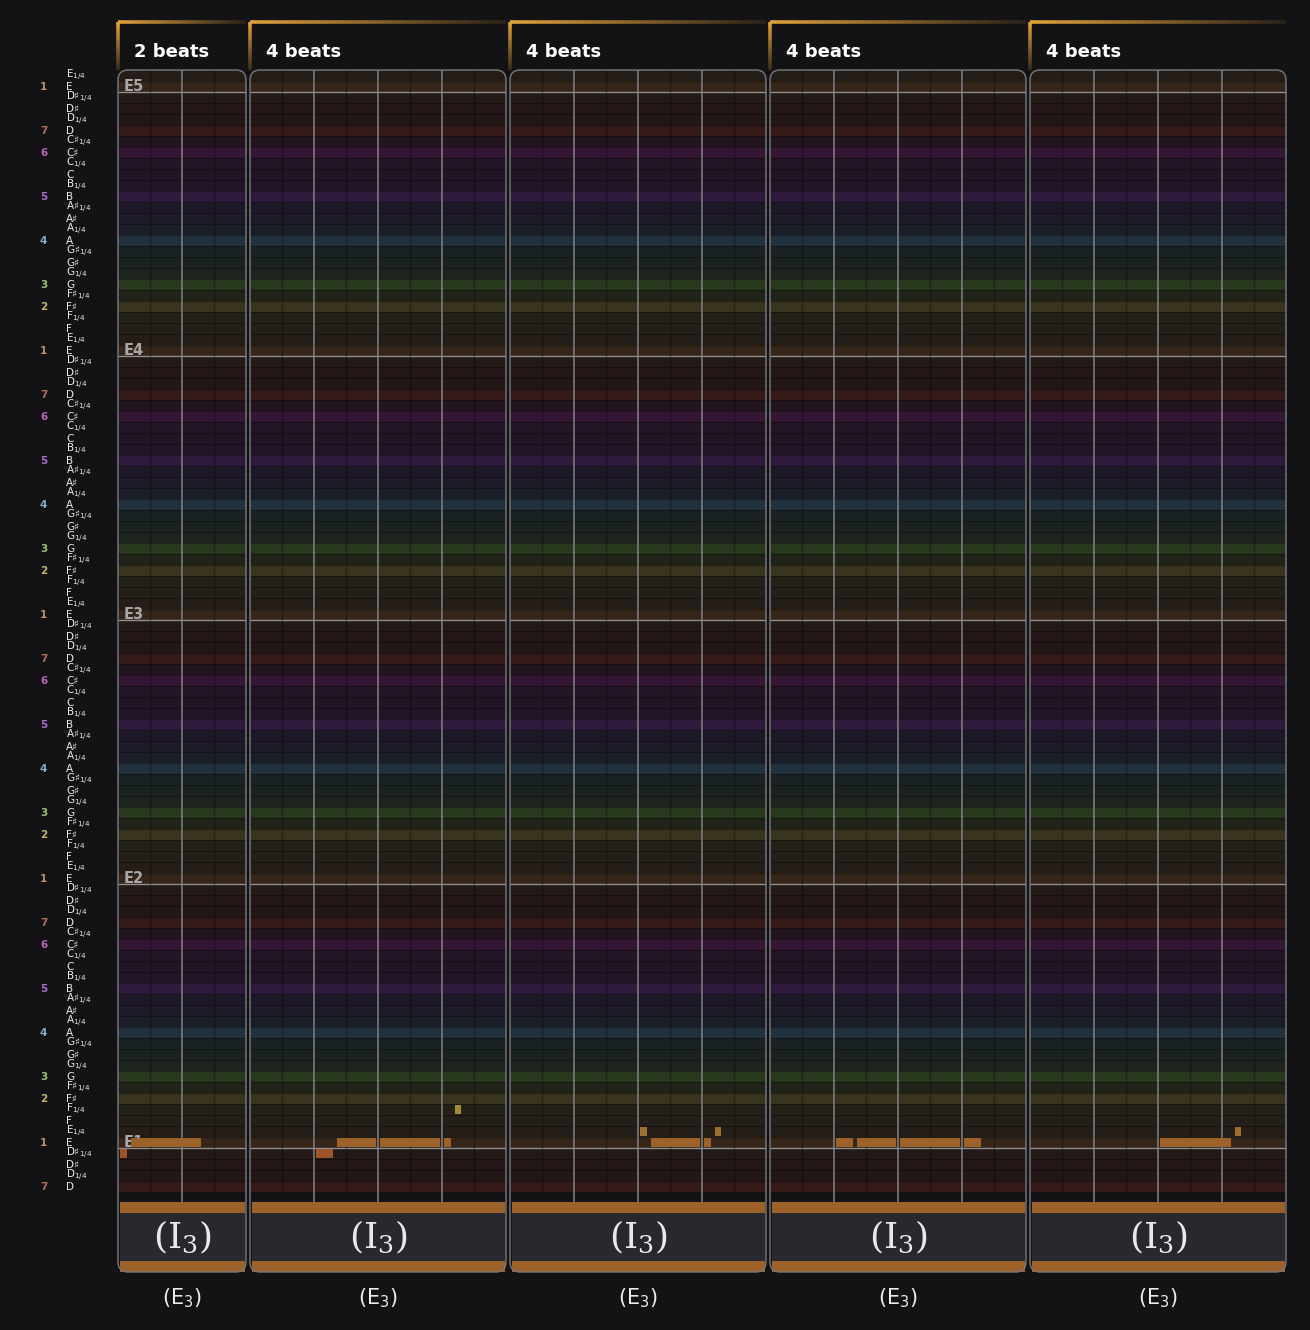

Página 2/30 · compases 6–10 · 0:09 – 0:18 · pulsos por compás: [4, 4, 2, 4, 4]


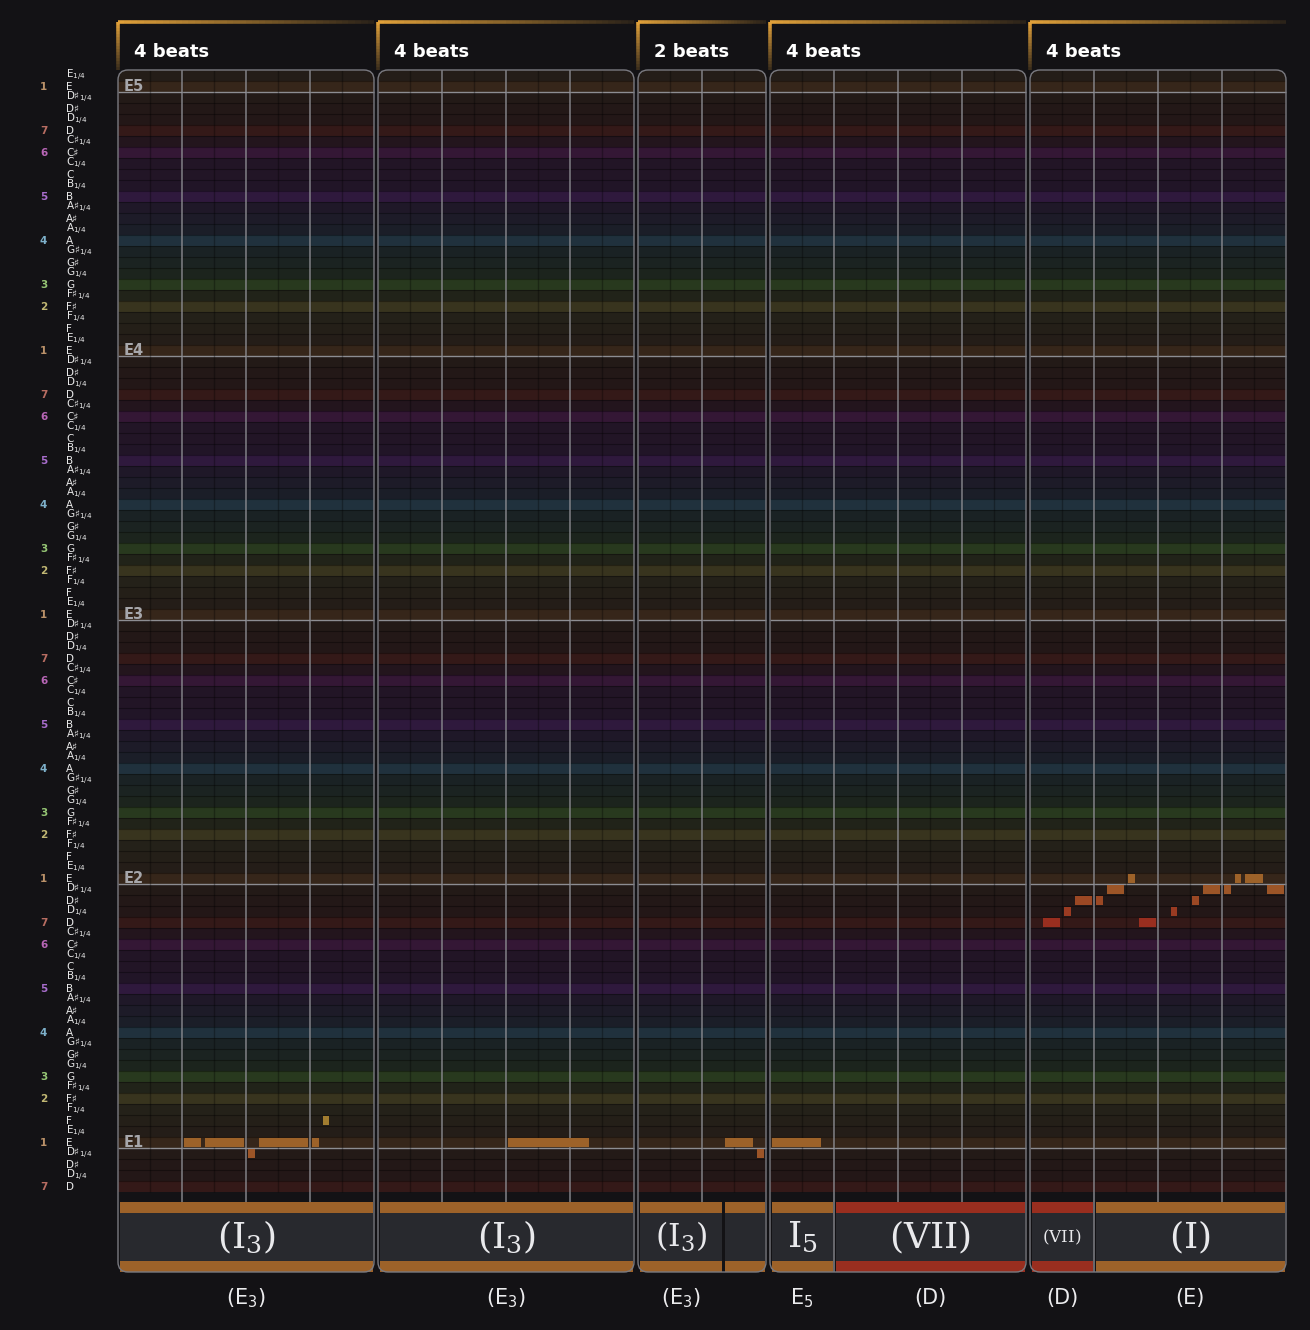

Página 3/30 · compases 11–15 · 0:18 – 0:29 · pulsos por compás: [4, 4, 4, 4, 4]


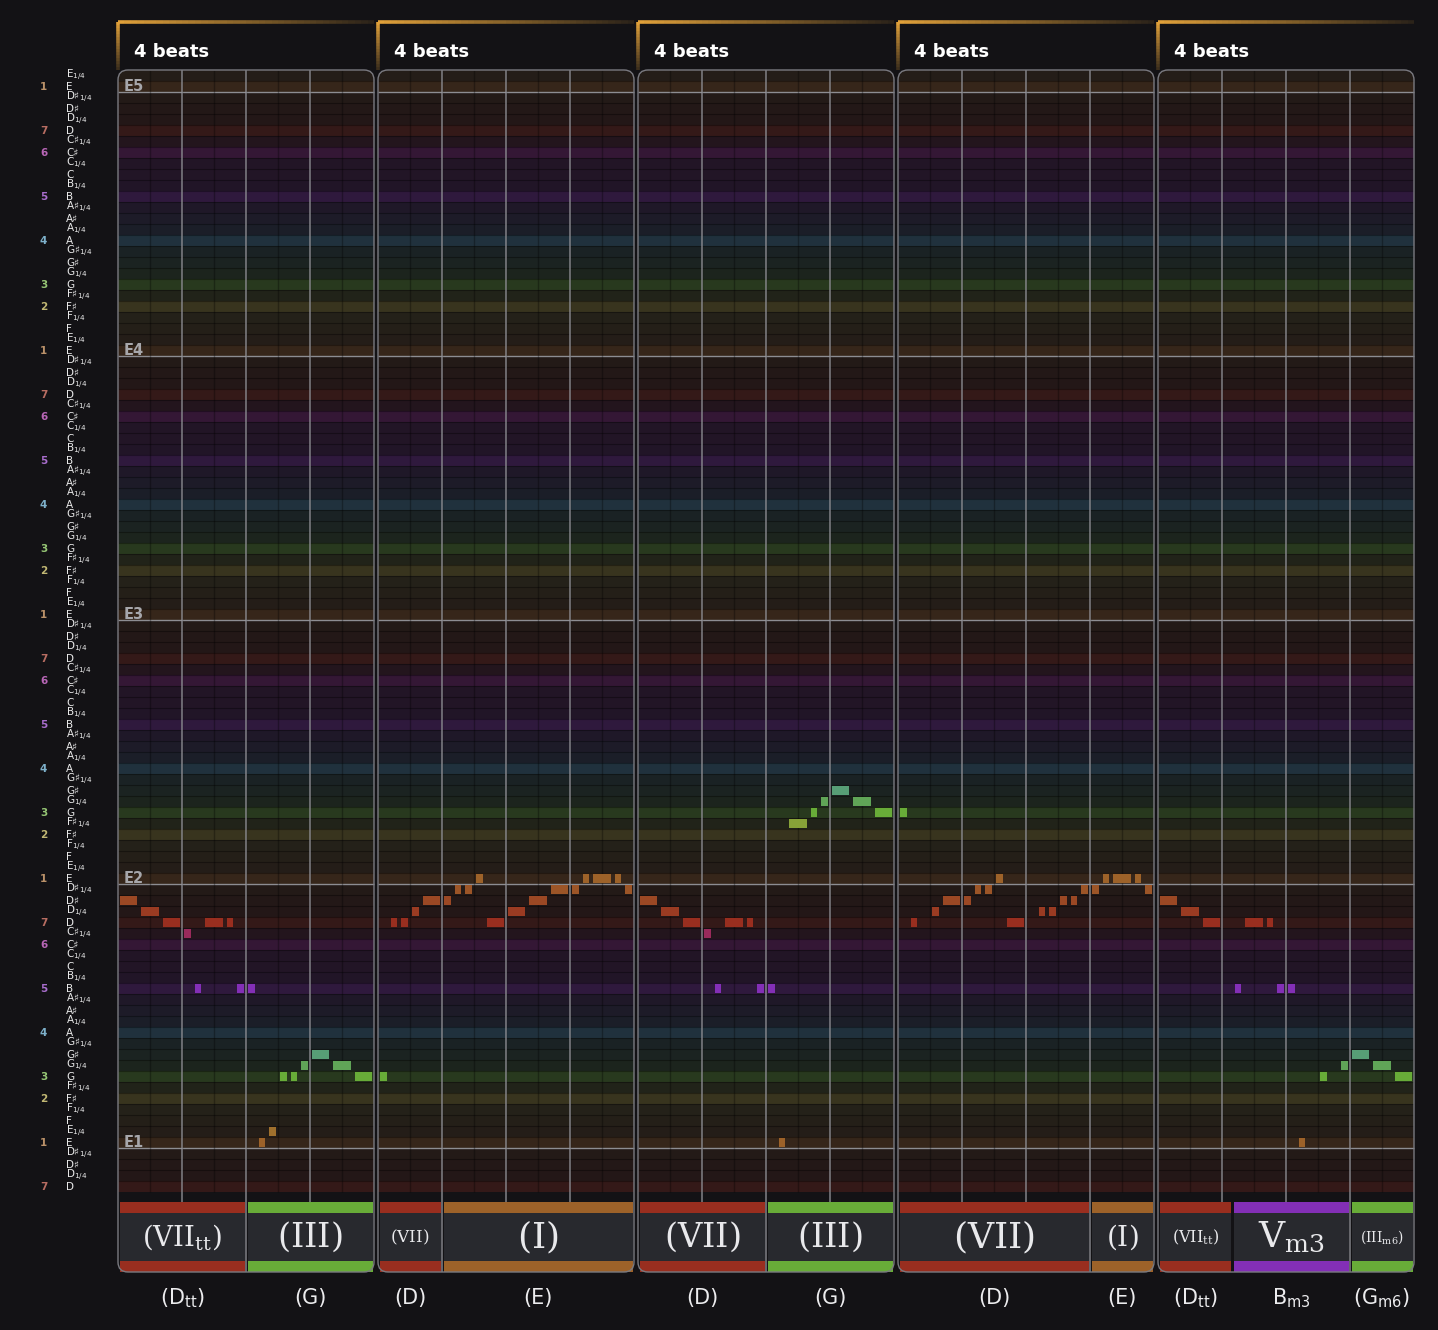

Página 4/30 · compases 16–20 · 0:29 – 0:39 · pulsos por compás: [4, 4, 4, 4, 4]


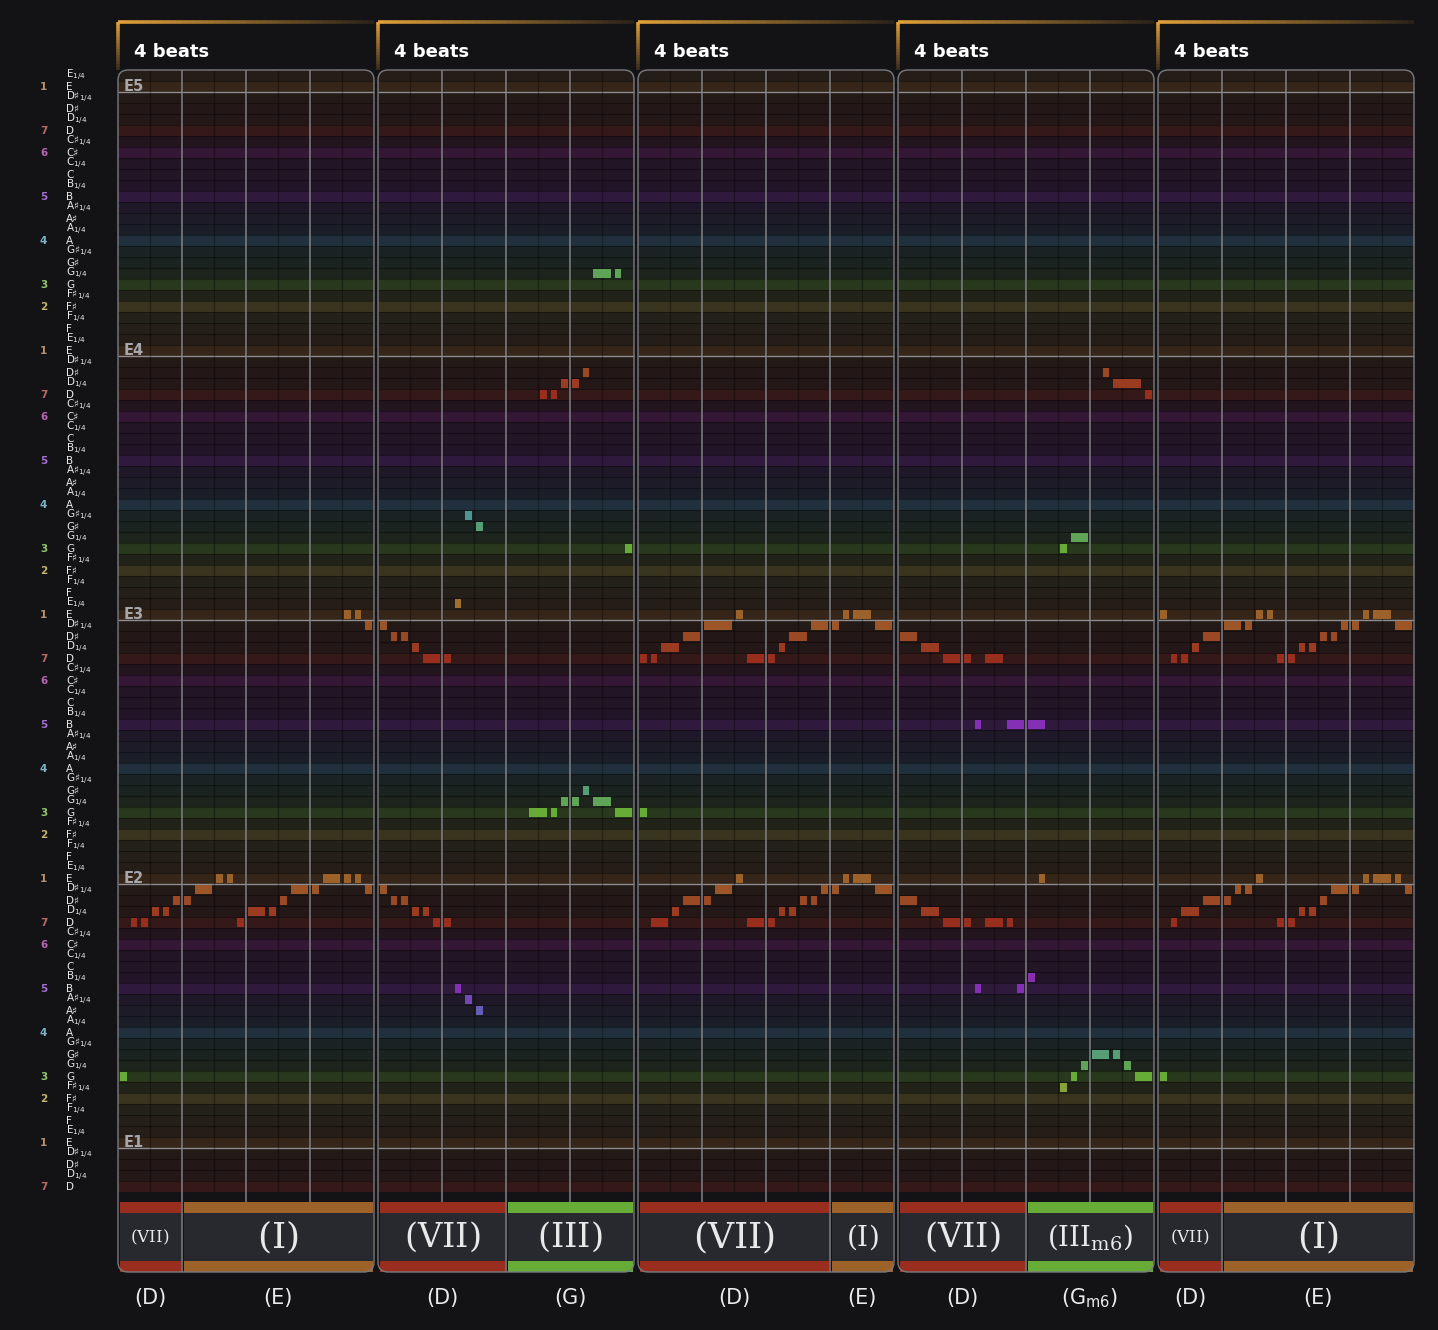

Página 5/30 · compases 21–25 · 0:39 – 0:49 · pulsos por compás: [4, 4, 4, 4, 4]


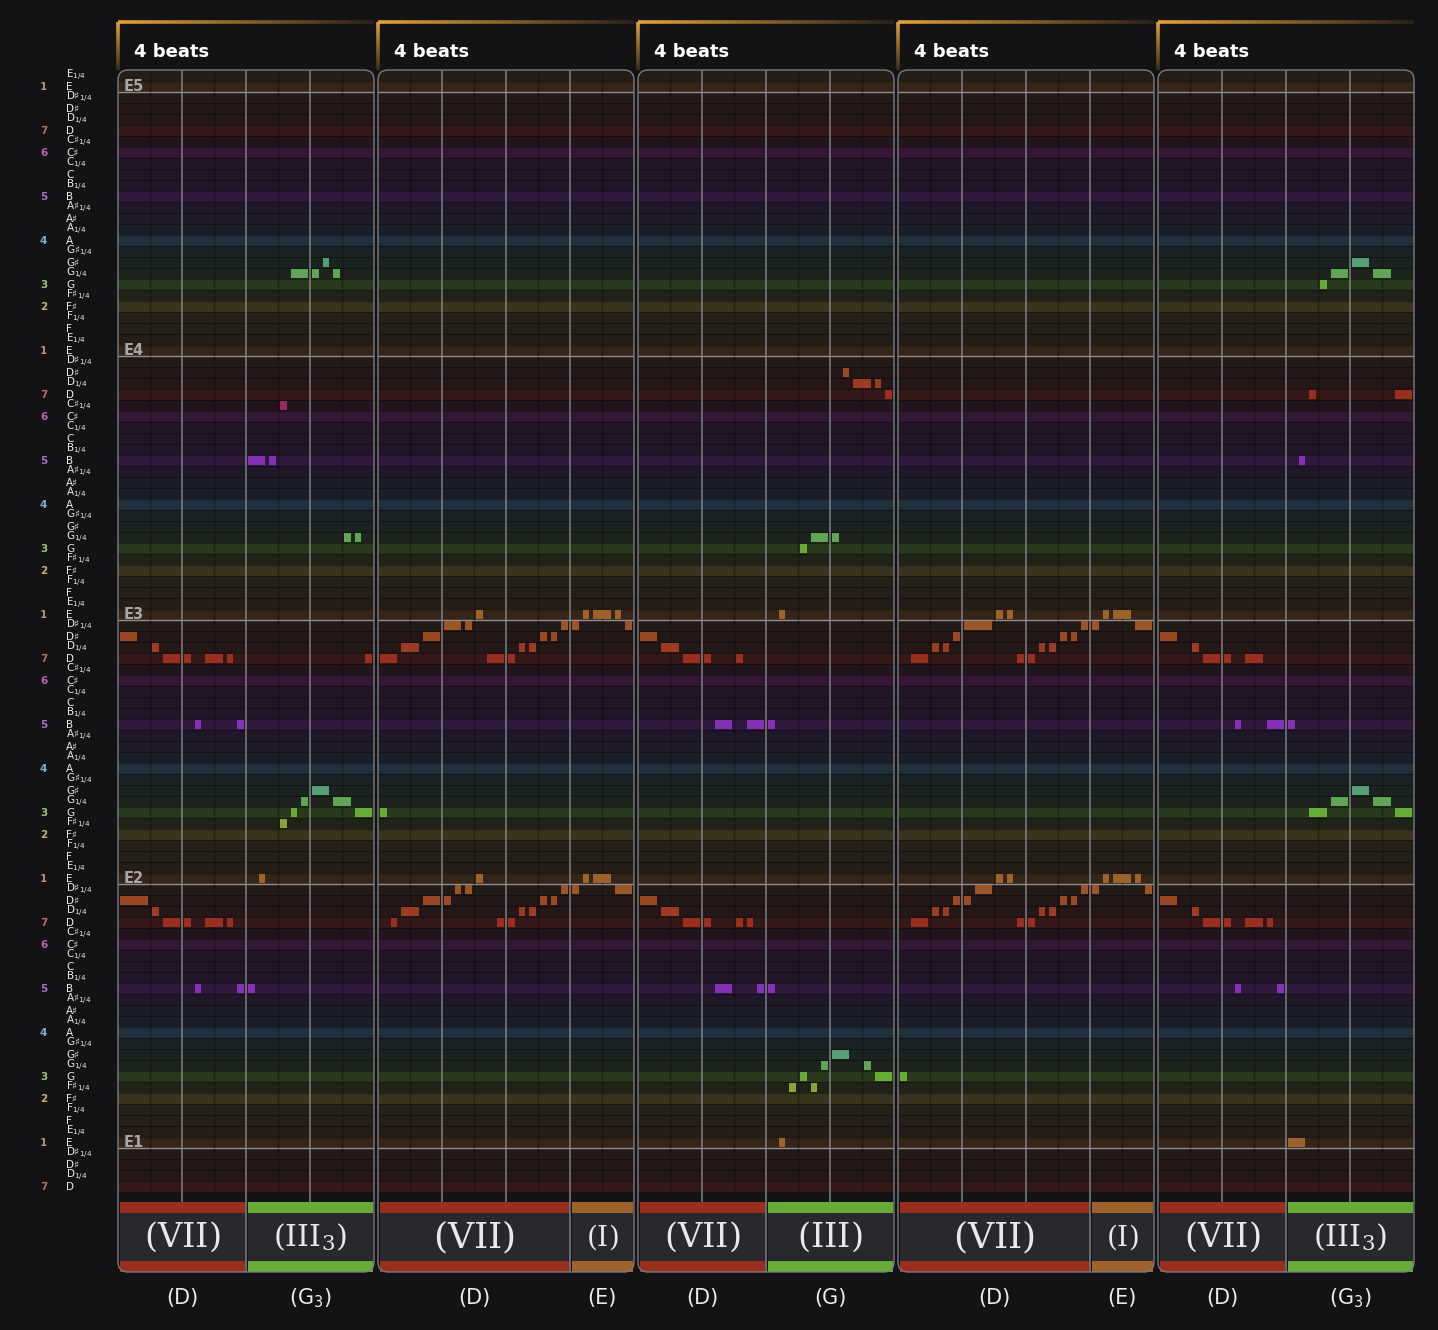

Página 6/30 · compases 26–30 · 0:49 – 1:00 · pulsos por compás: [4, 4, 4, 4, 4]


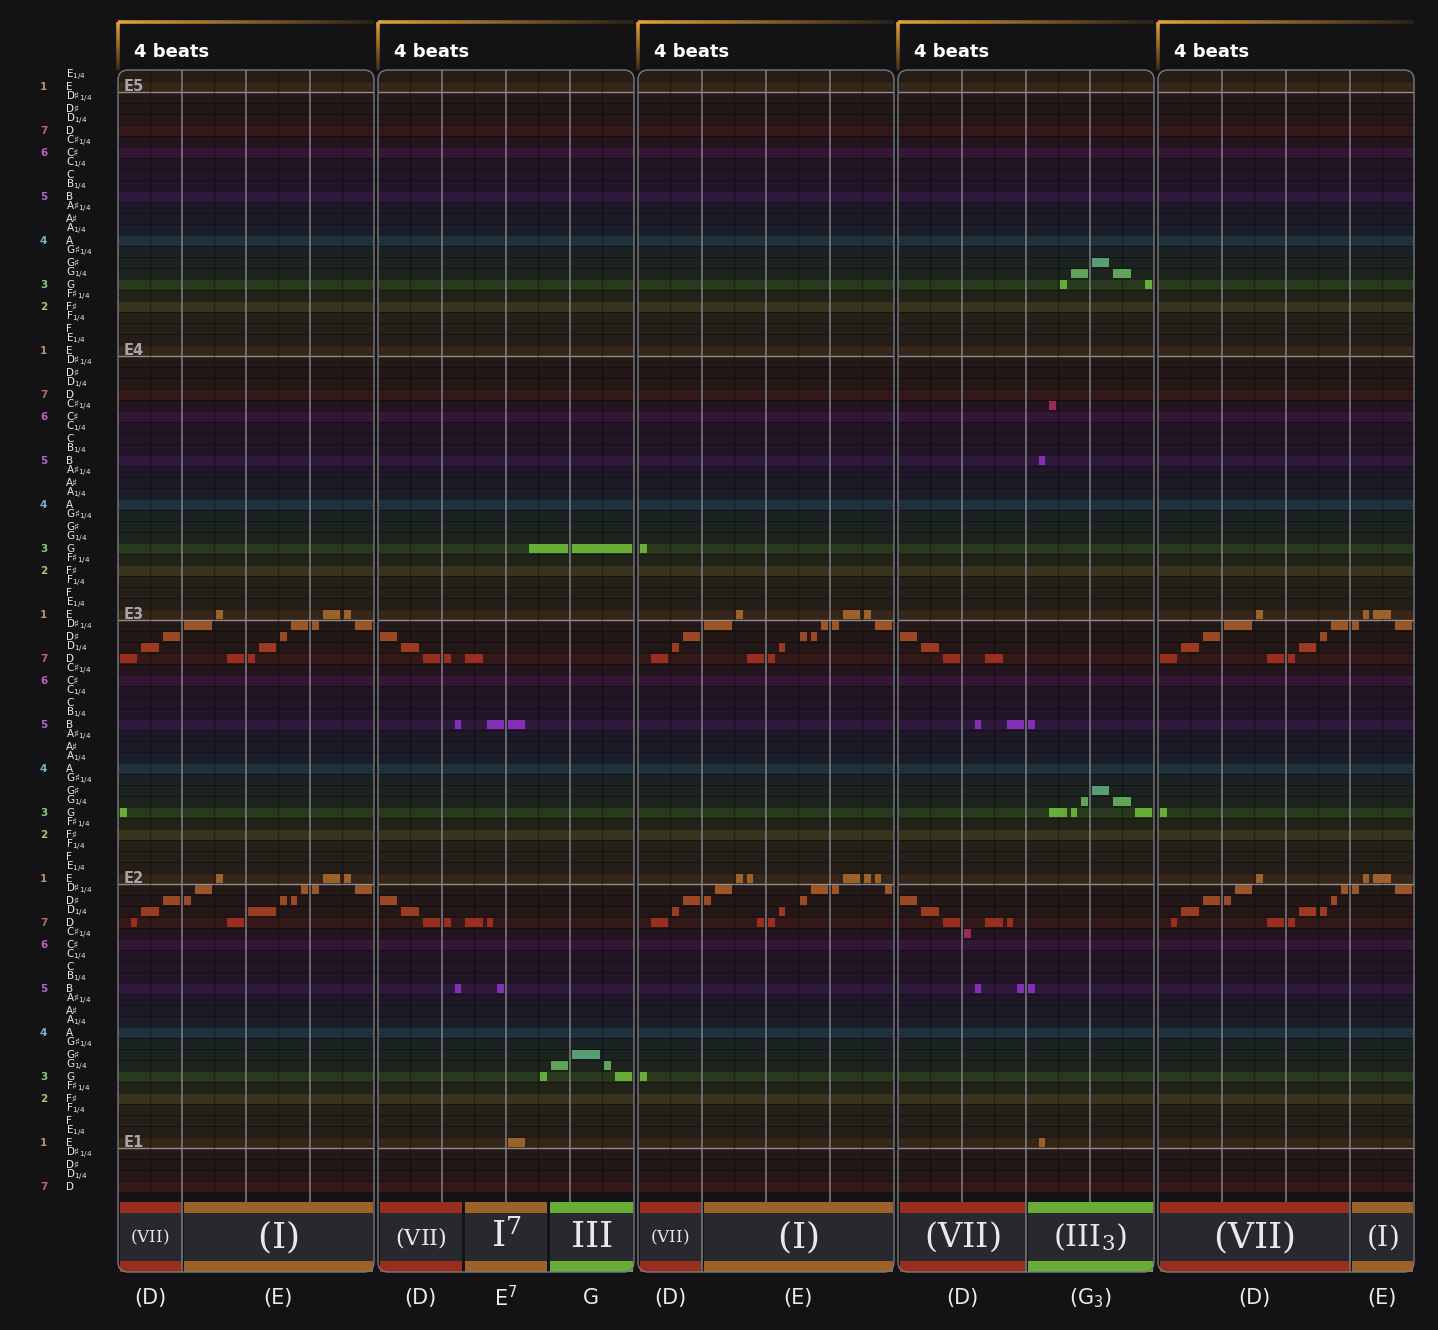

Página 7/30 · compases 31–35 · 1:00 – 1:10 · pulsos por compás: [4, 4, 4, 4, 4]


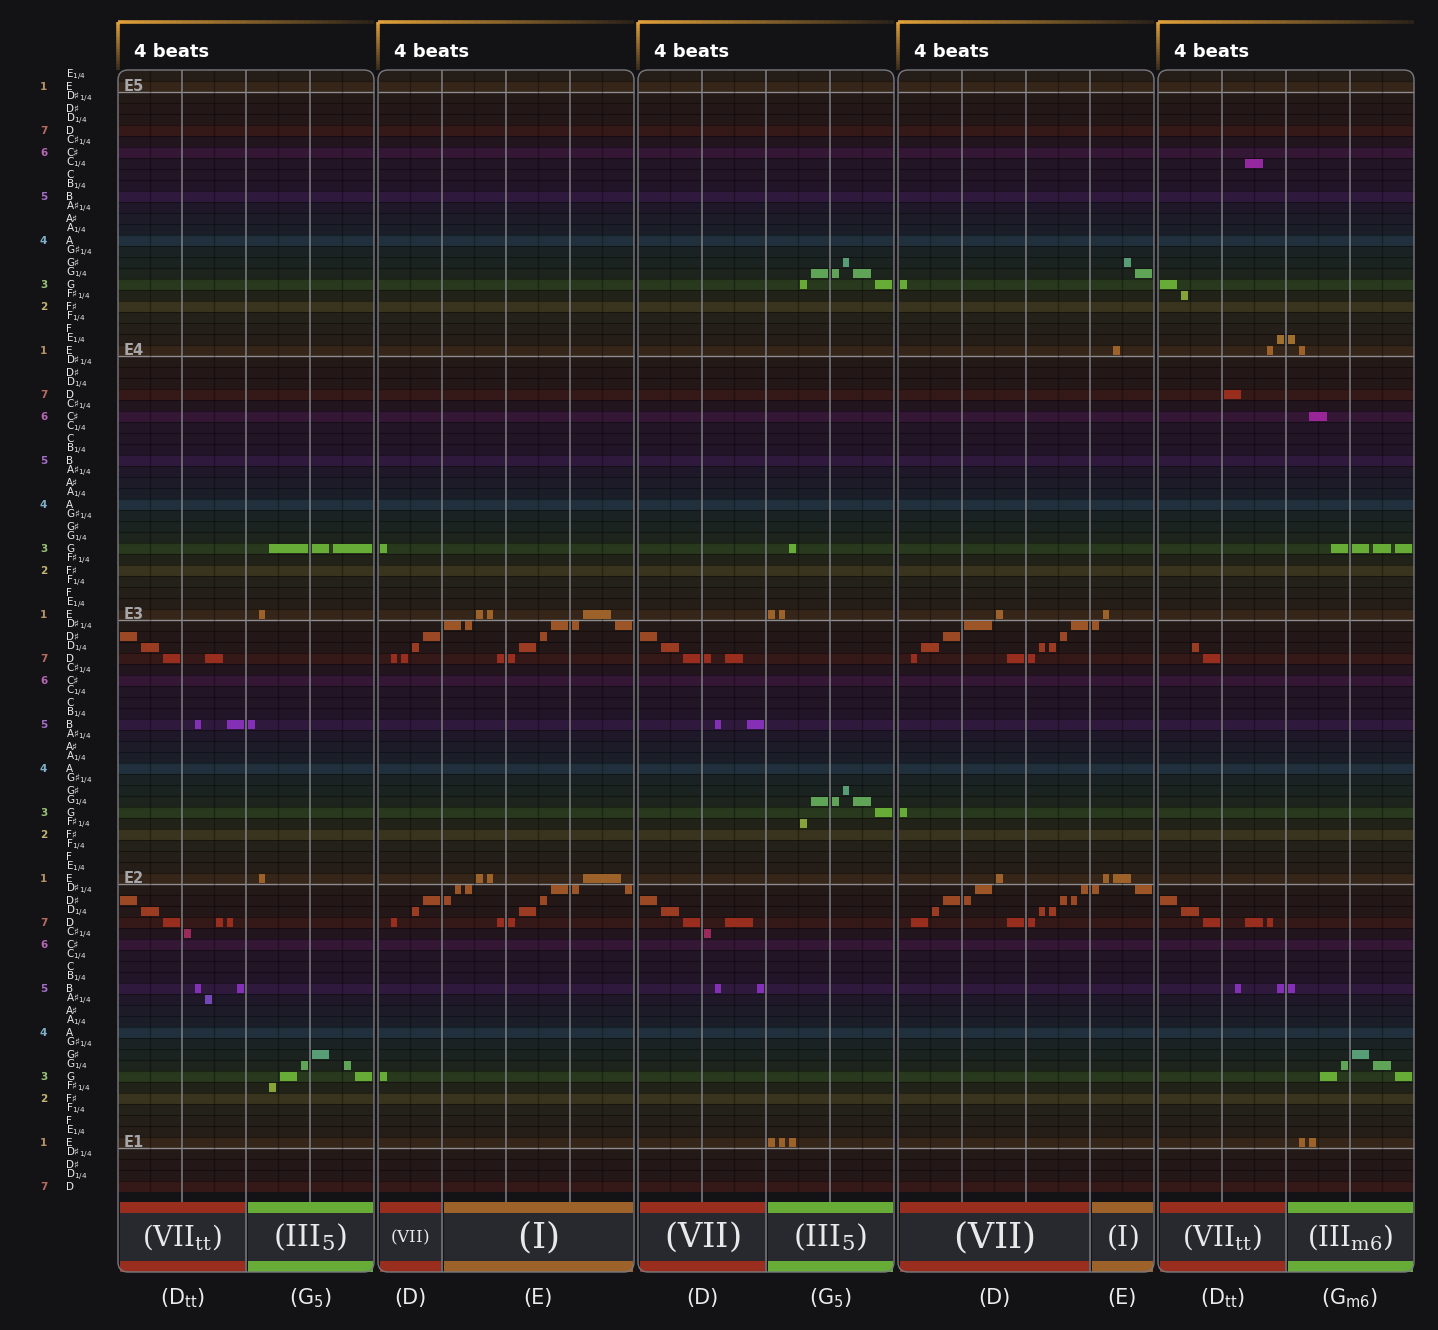

Página 8/30 · compases 36–40 · 1:10 – 1:20 · pulsos por compás: [4, 4, 4, 4, 4]


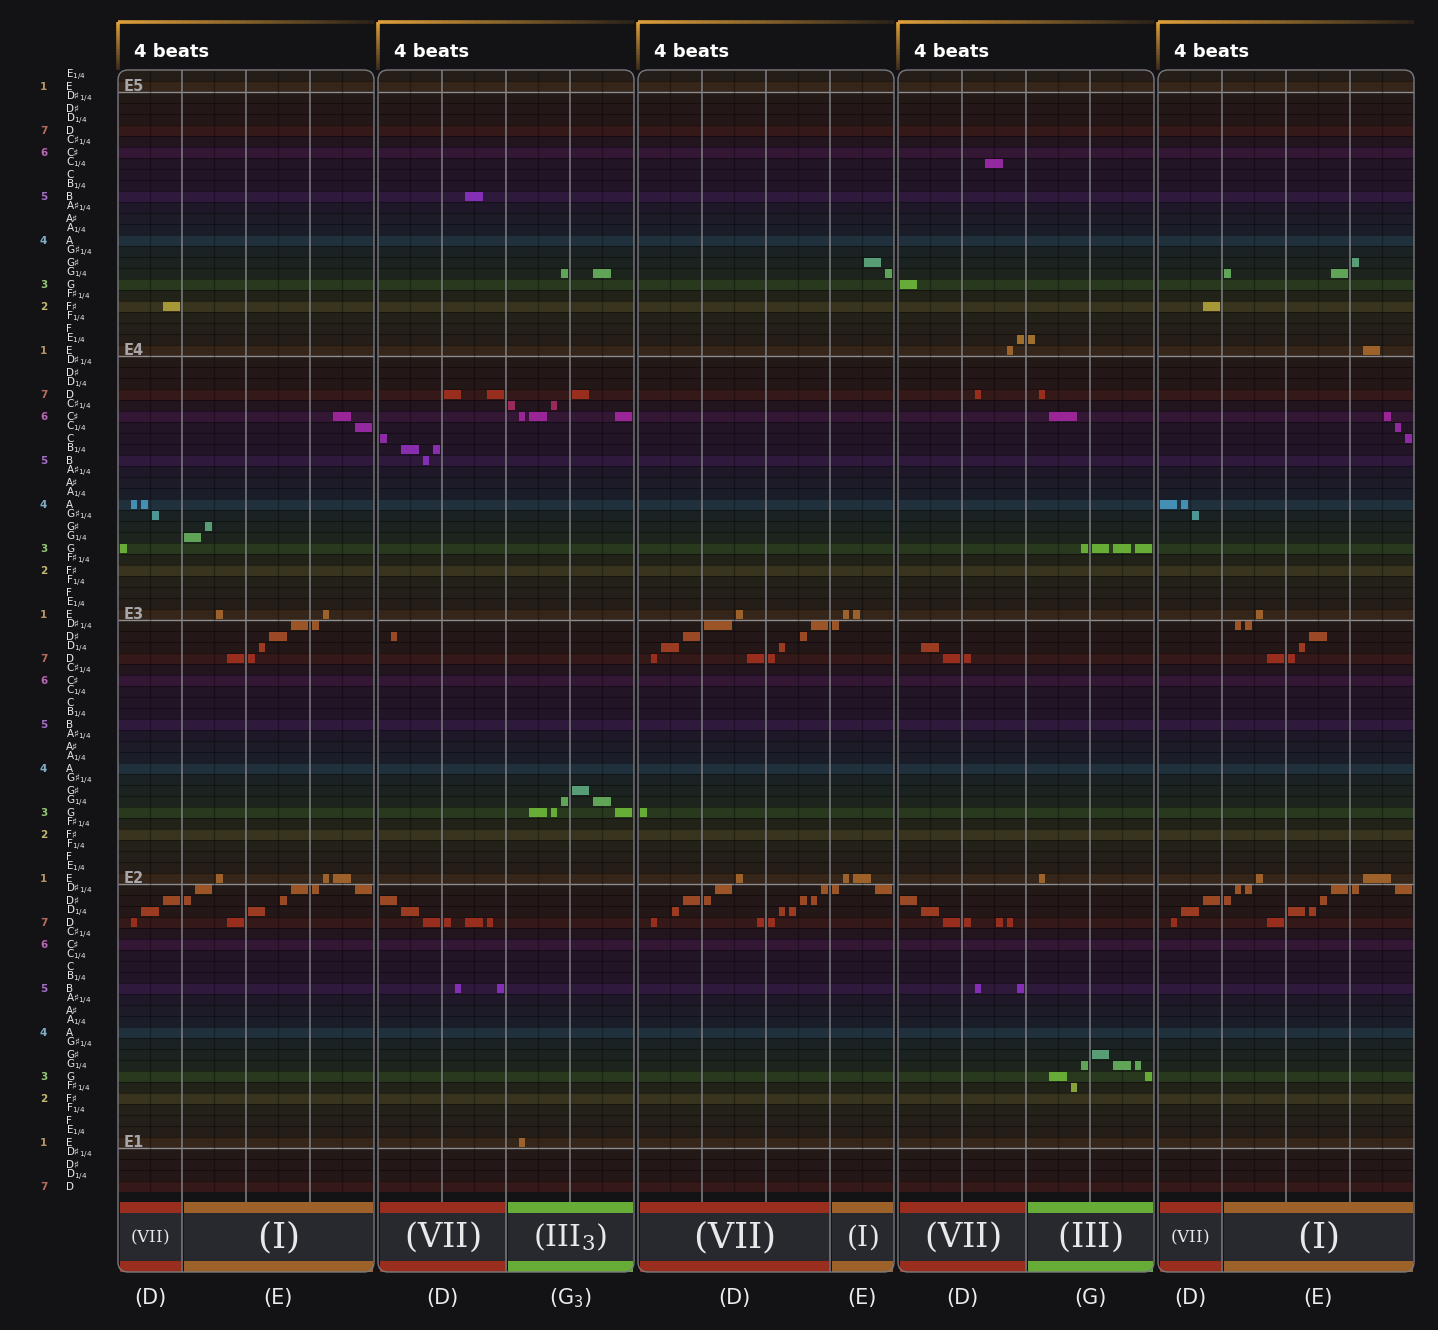

Página 9/30 · compases 41–45 · 1:20 – 1:31 · pulsos por compás: [4, 4, 4, 4, 4]


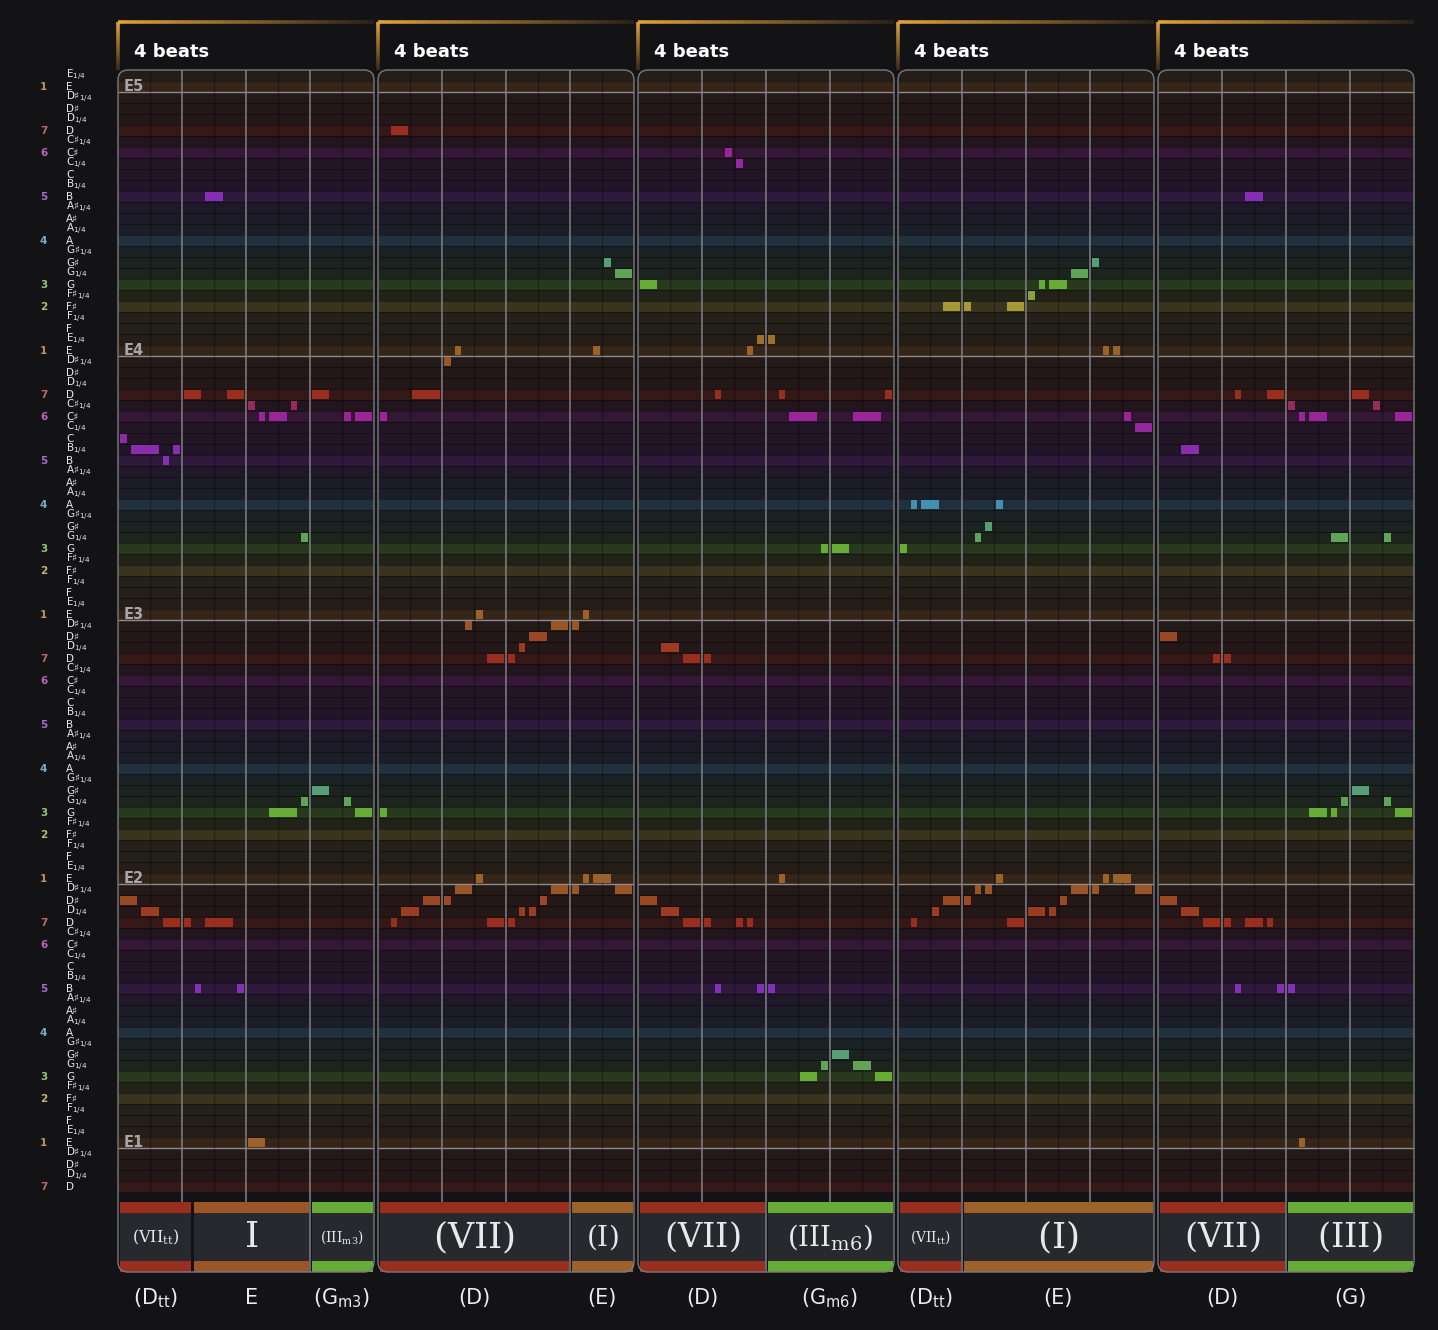

Página 10/30 · compases 46–49 · 1:31 – 1:40 · pulsos por compás: [4, 4, 8, 2]


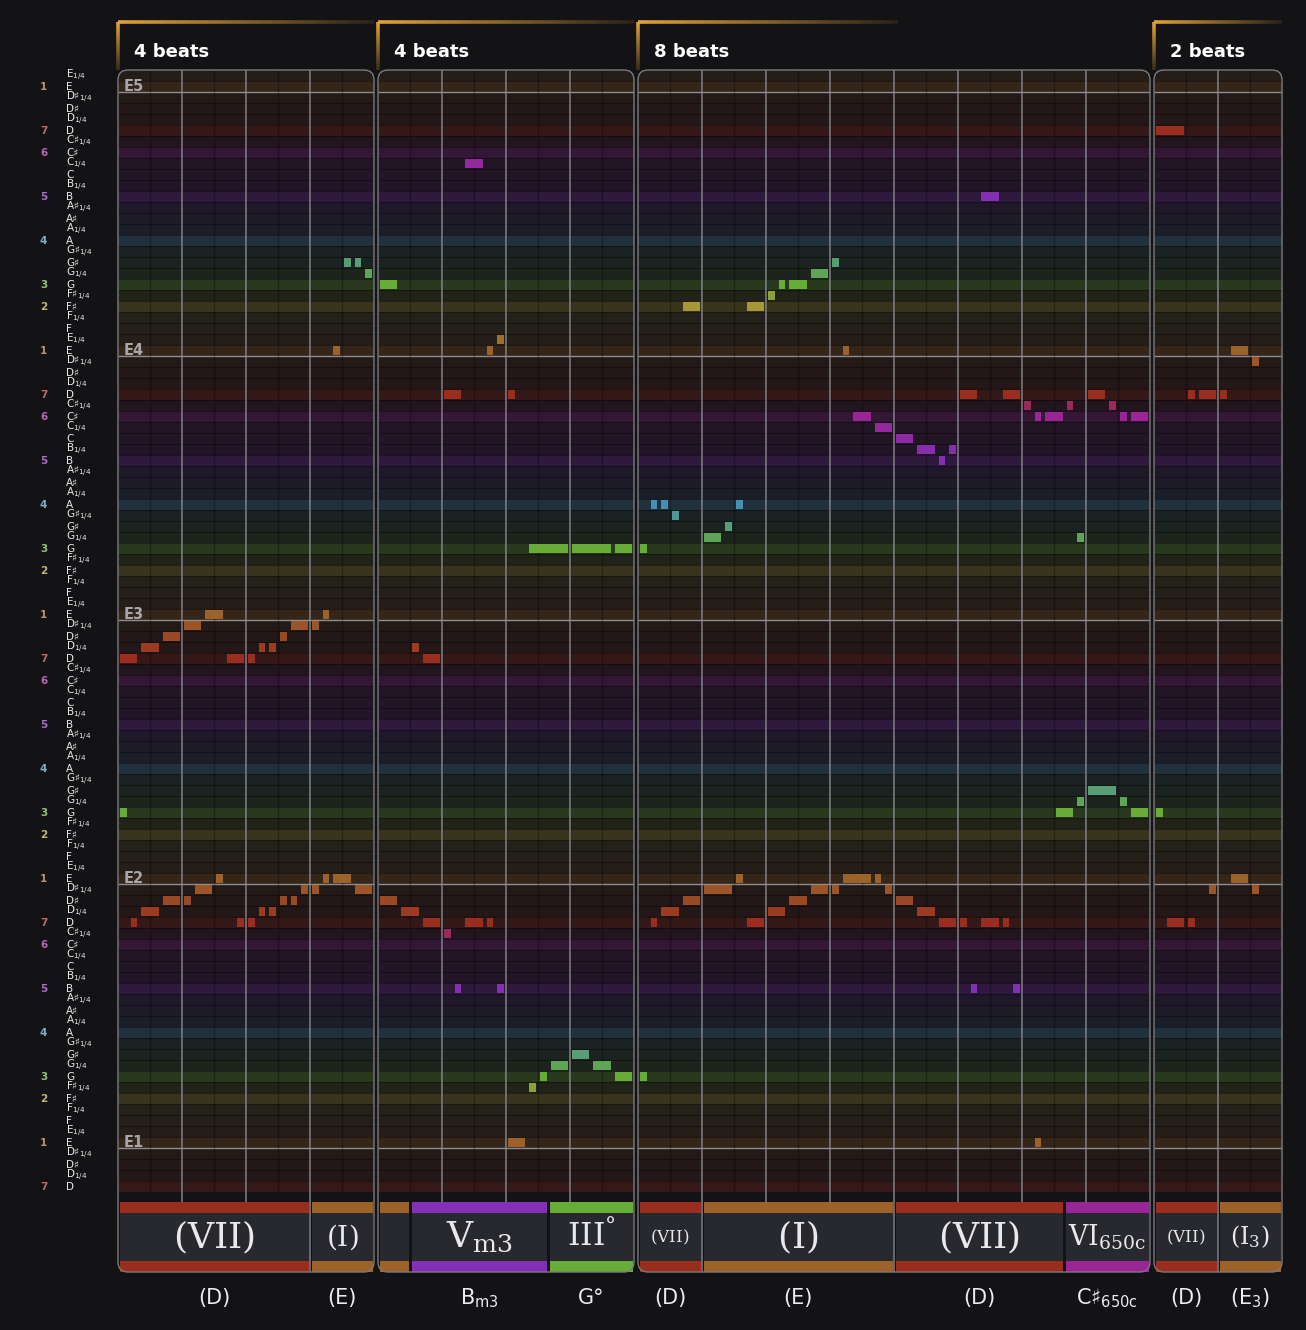

Página 11/30 · compases 50–51 · 1:40 – 1:48 · pulsos por compás: [8, 8]


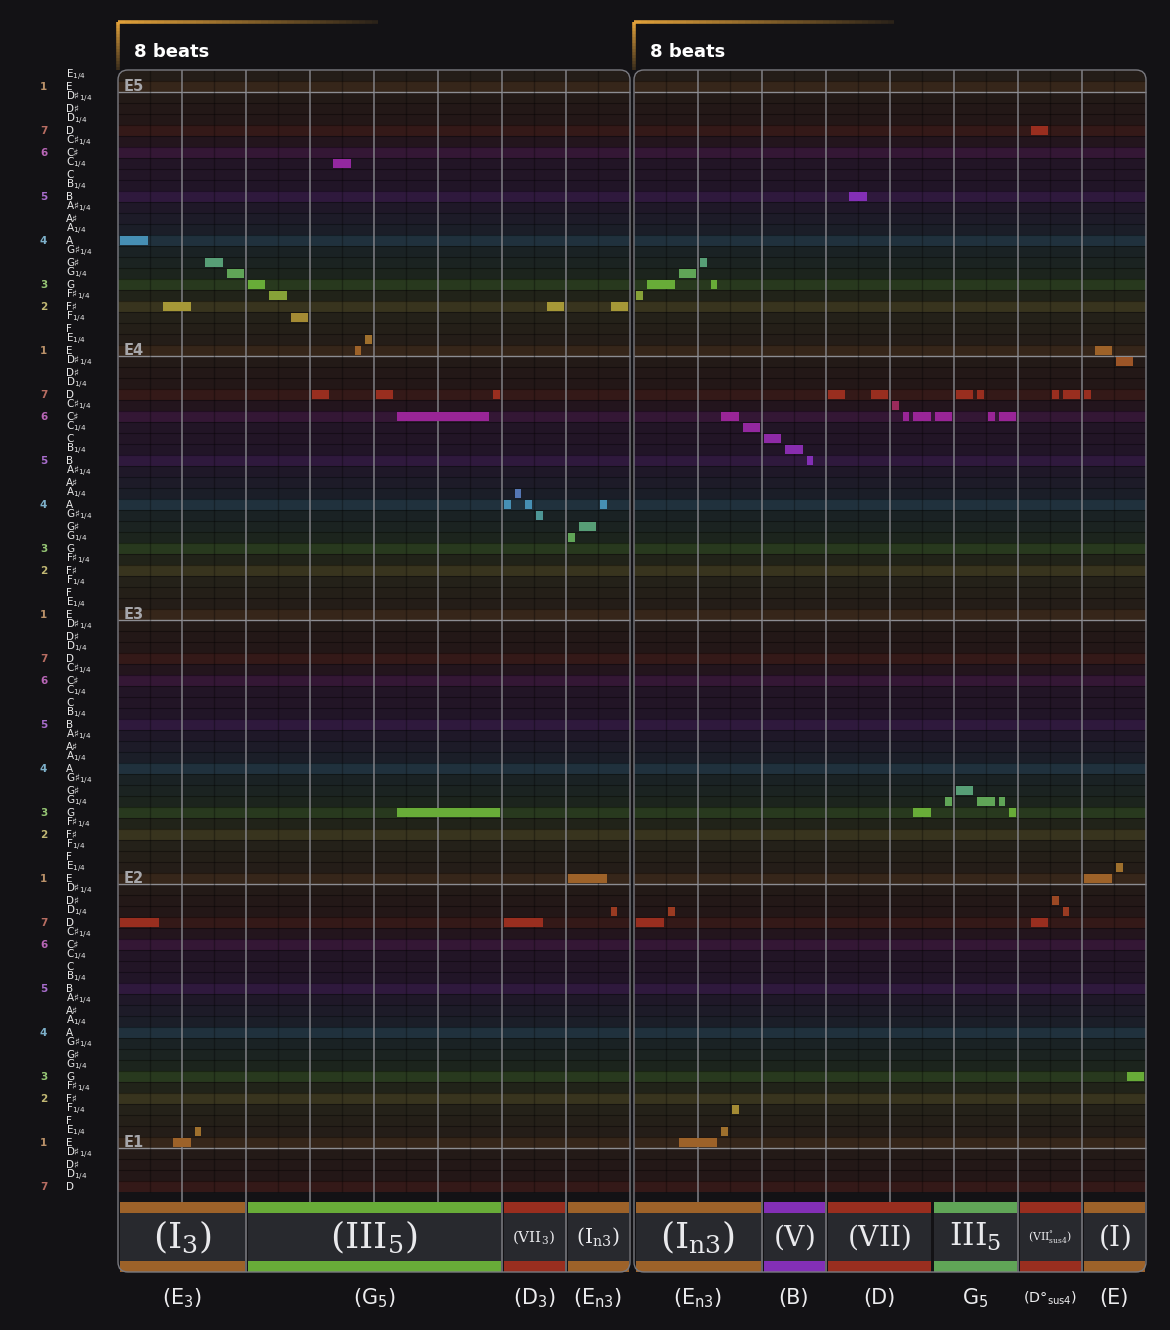

Página 12/30 · compases 52–55 · 1:48 – 1:59 · pulsos por compás: [8, 4, 4, 4]


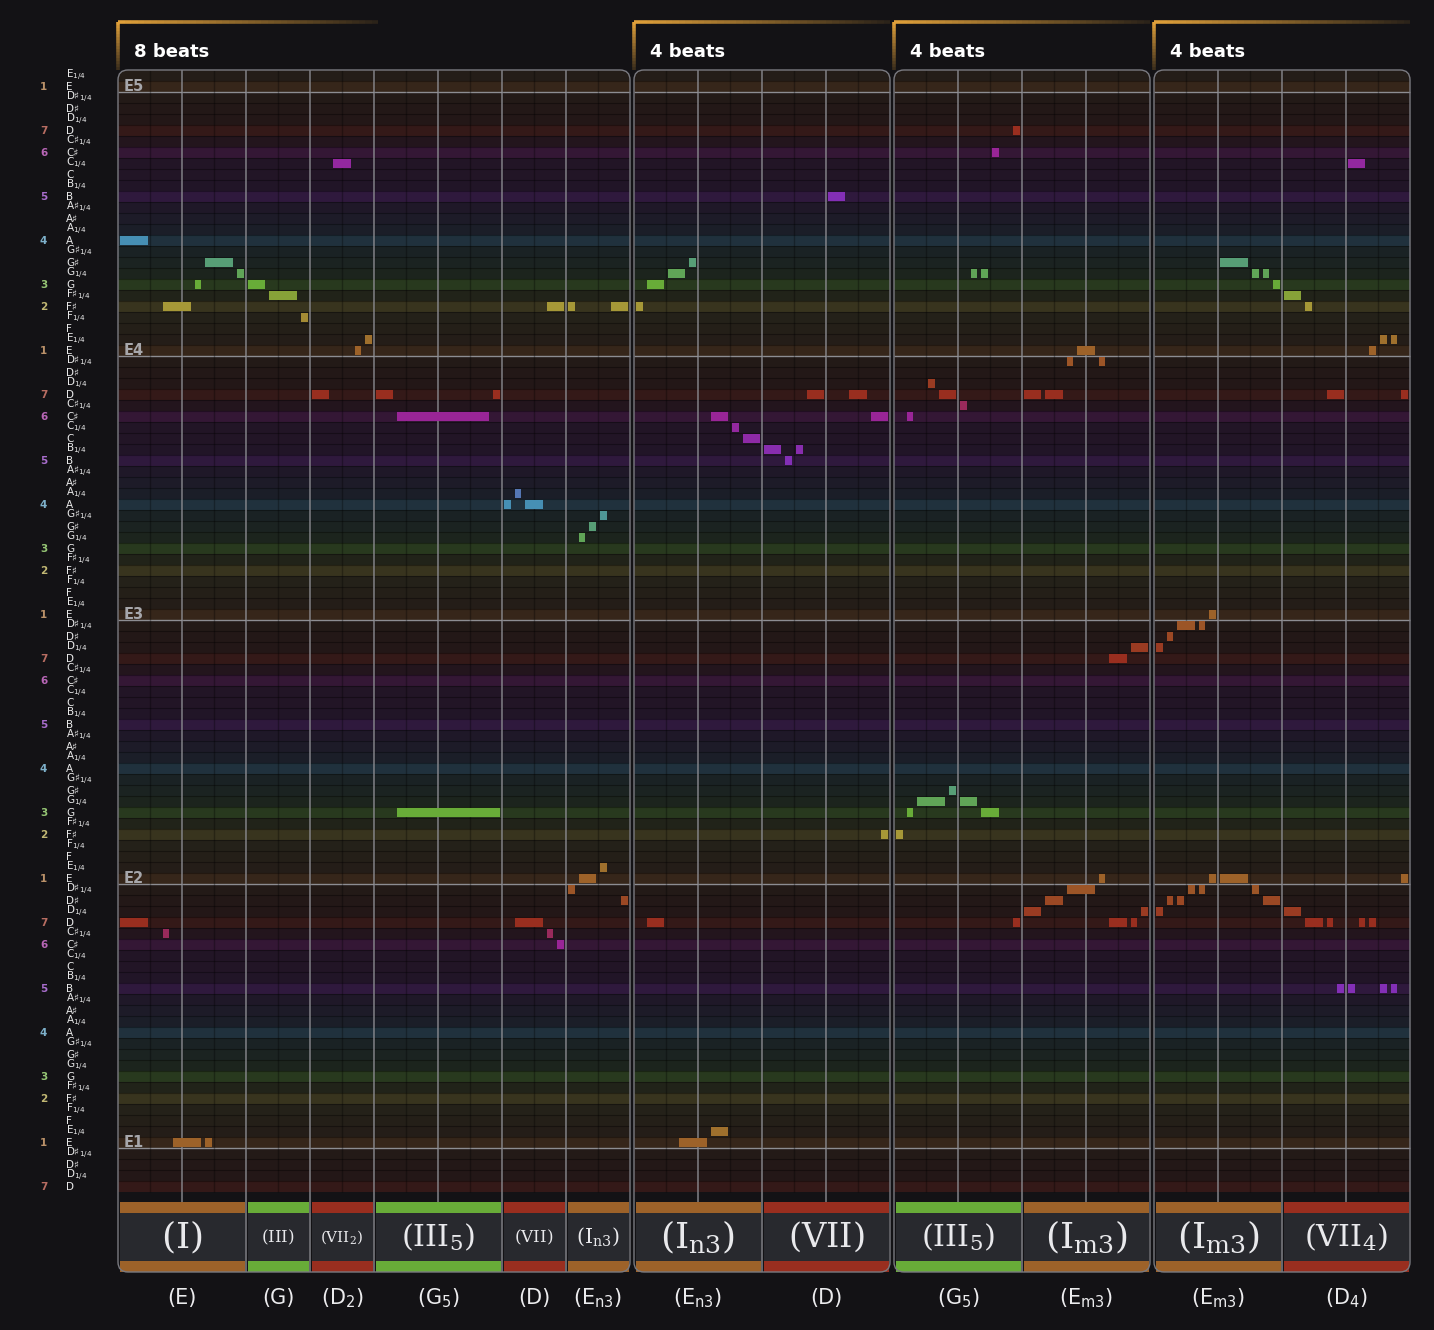

Página 13/30 · compases 56–58 · 1:59 – 2:07 · pulsos por compás: [4, 4, 8]


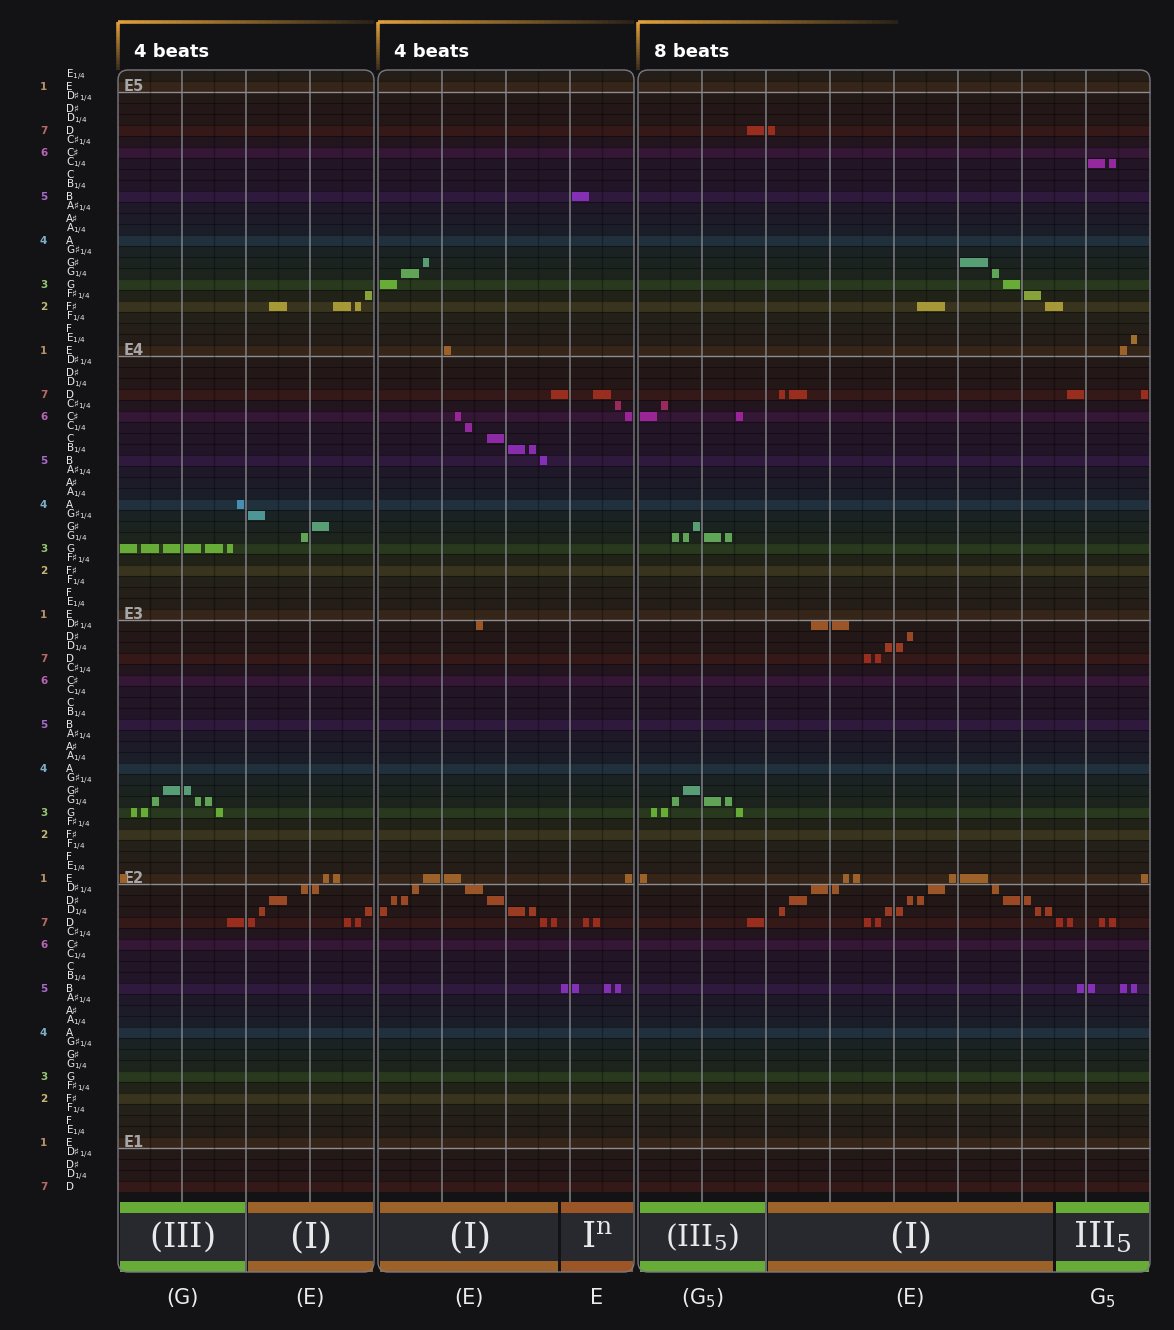

Página 14/30 · compases 59–60 · 2:07 – 2:15 · pulsos por compás: [8, 8]


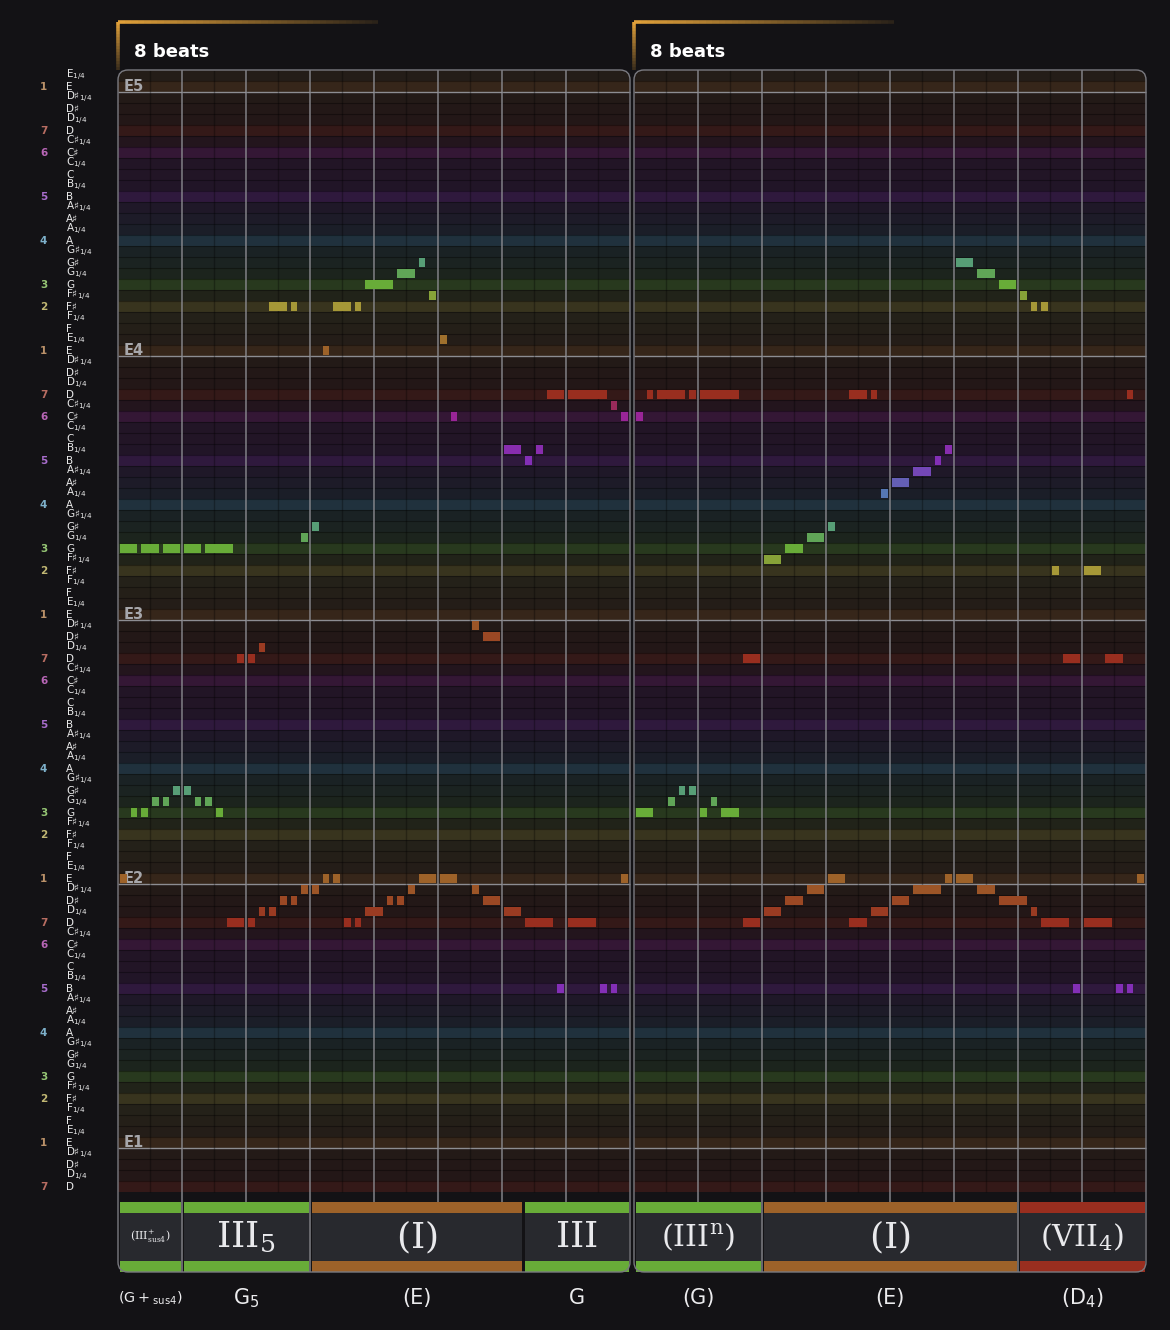

Página 15/30 · compases 61–62 · 2:15 – 2:24 · pulsos por compás: [8, 8]


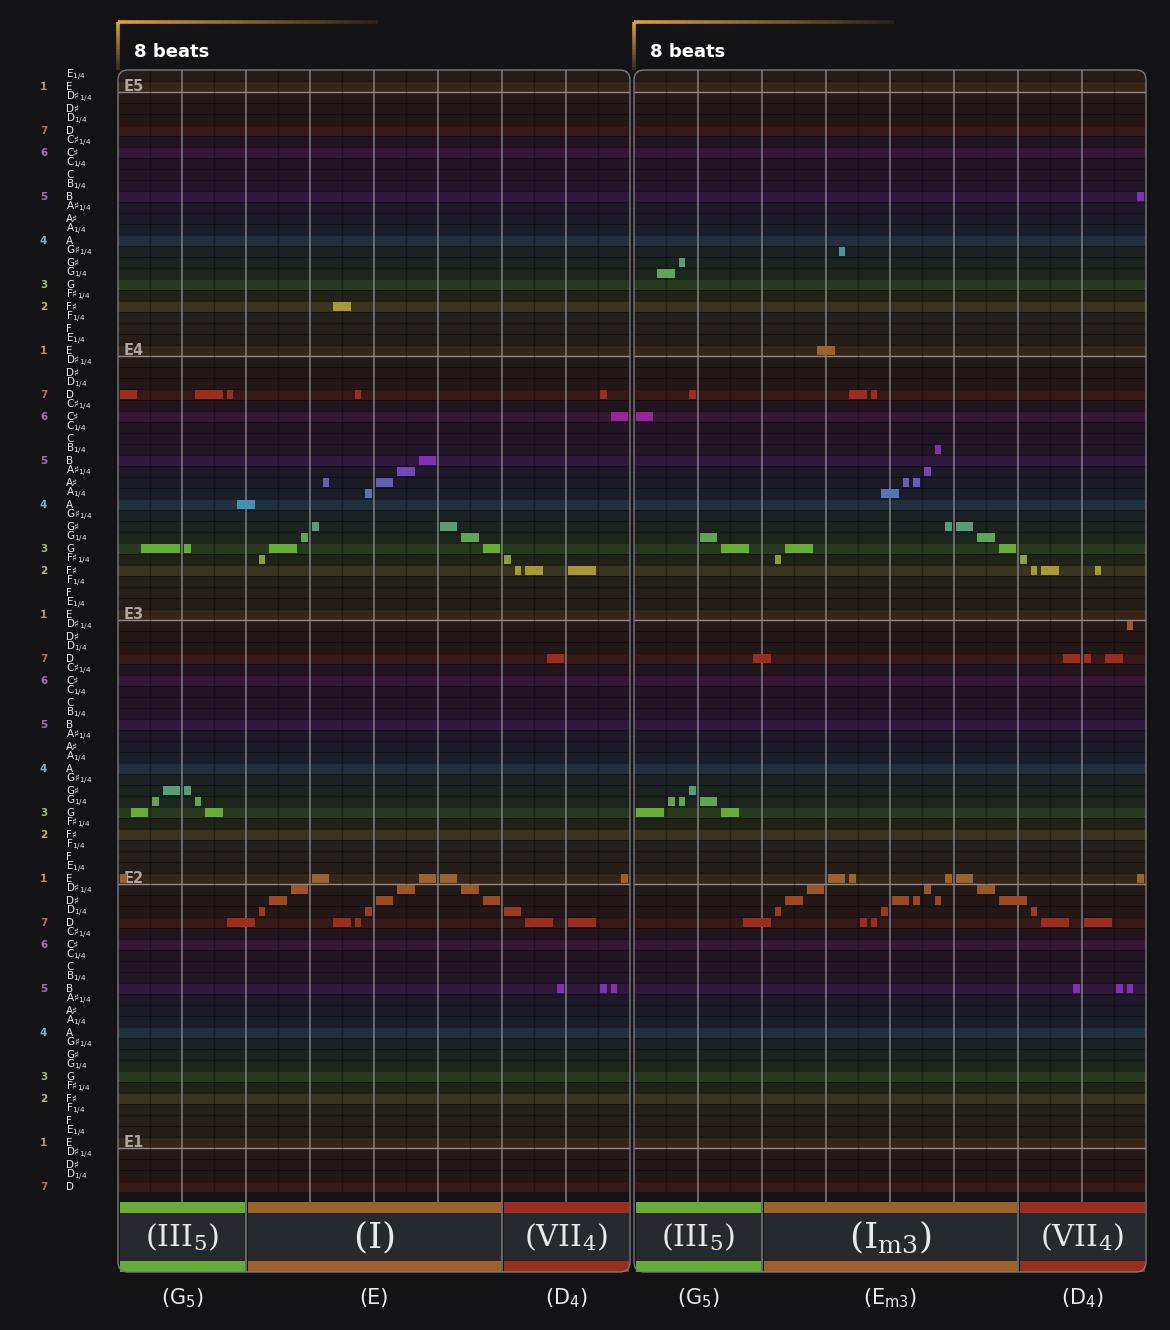

Página 16/30 · compases 63–64 · 2:24 – 2:32 · pulsos por compás: [8, 8]


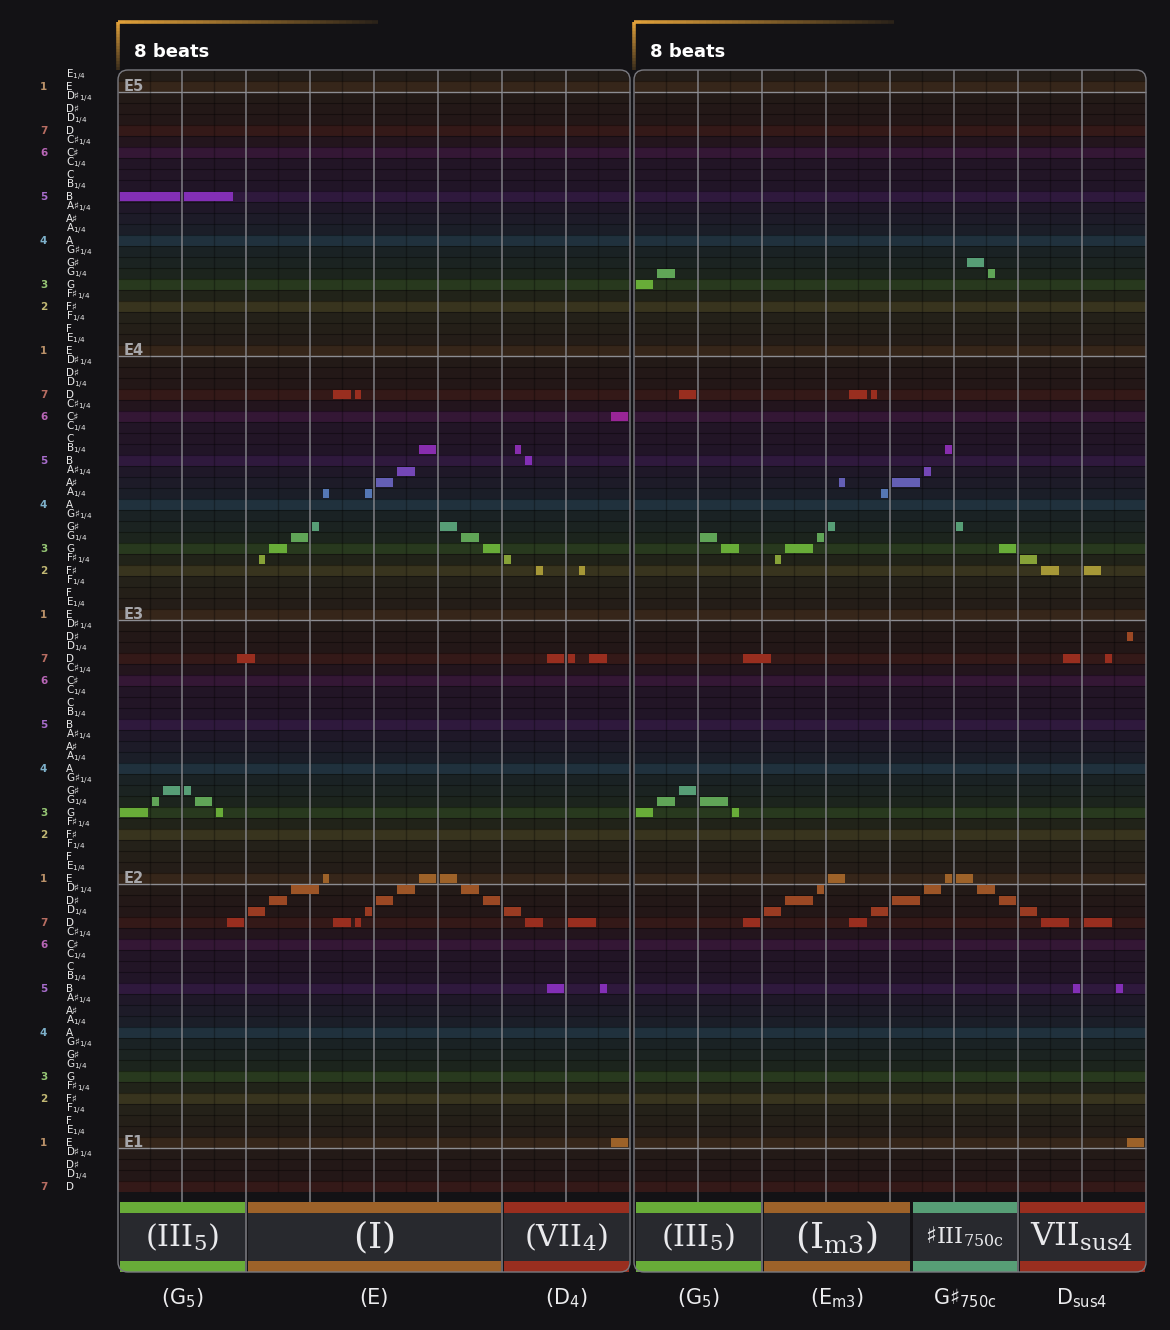

Página 17/30 · compases 65–67 · 2:32 – 2:41 · pulsos por compás: [8, 8, 2]


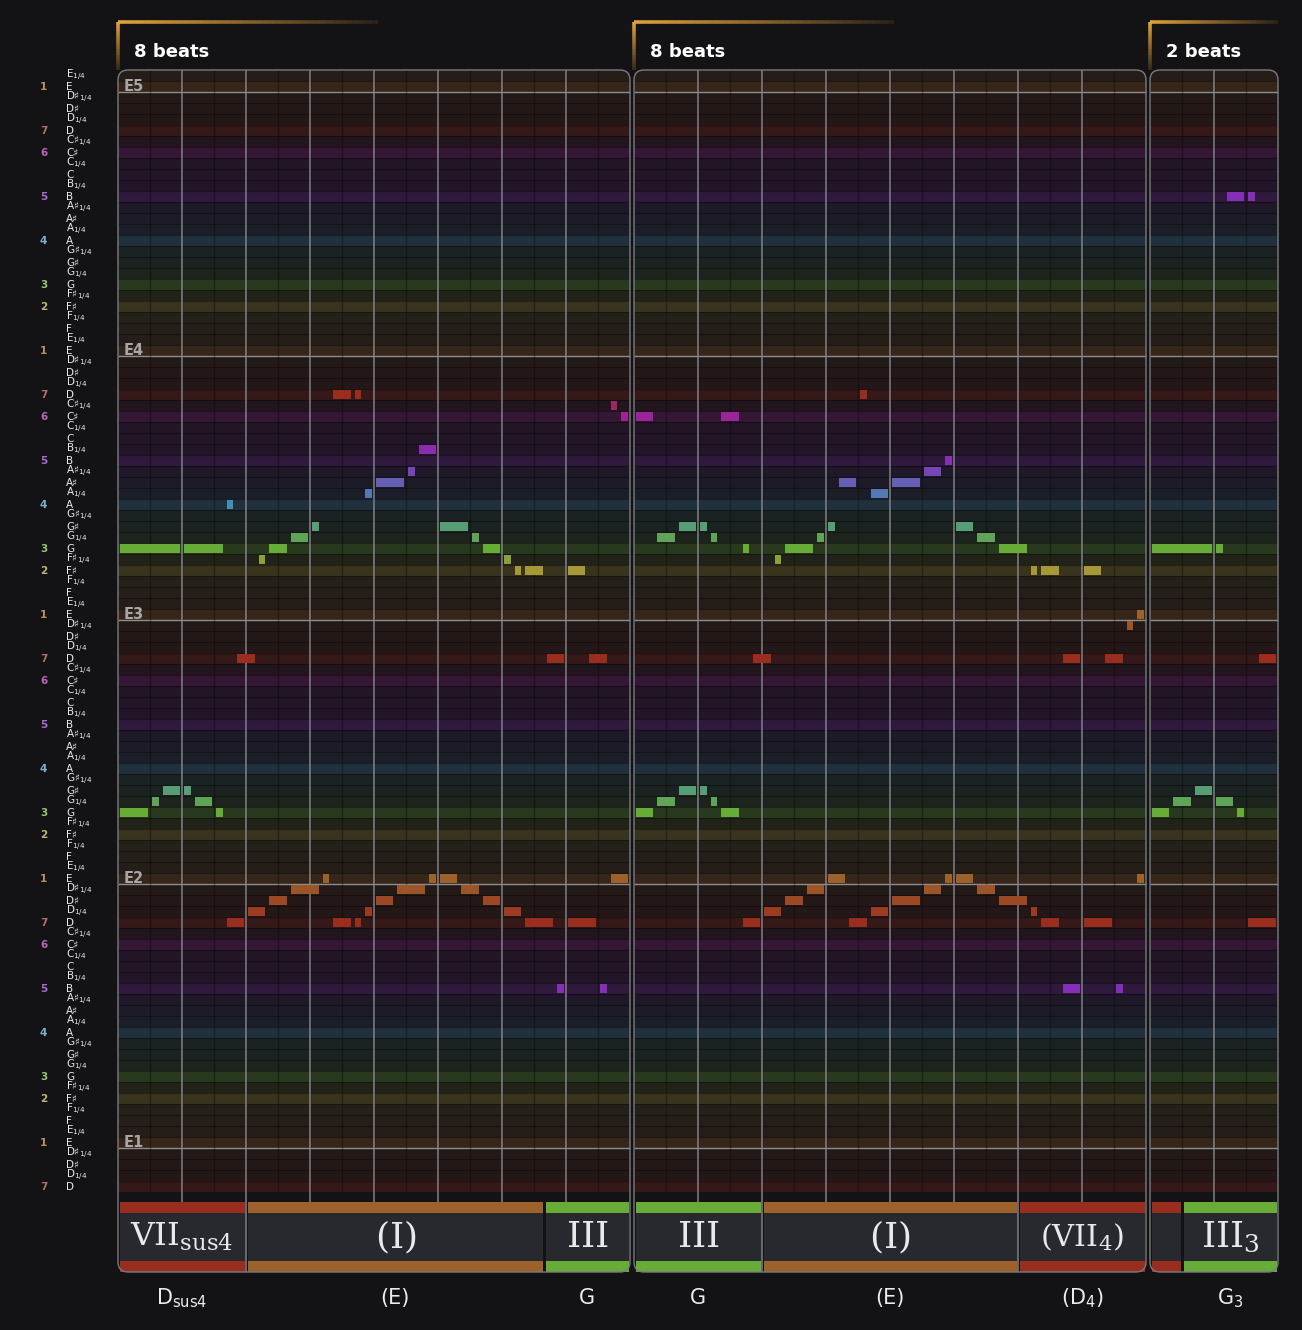

Página 18/30 · compases 68–72 · 2:41 – 2:52 · pulsos por compás: [4, 4, 4, 4, 4]


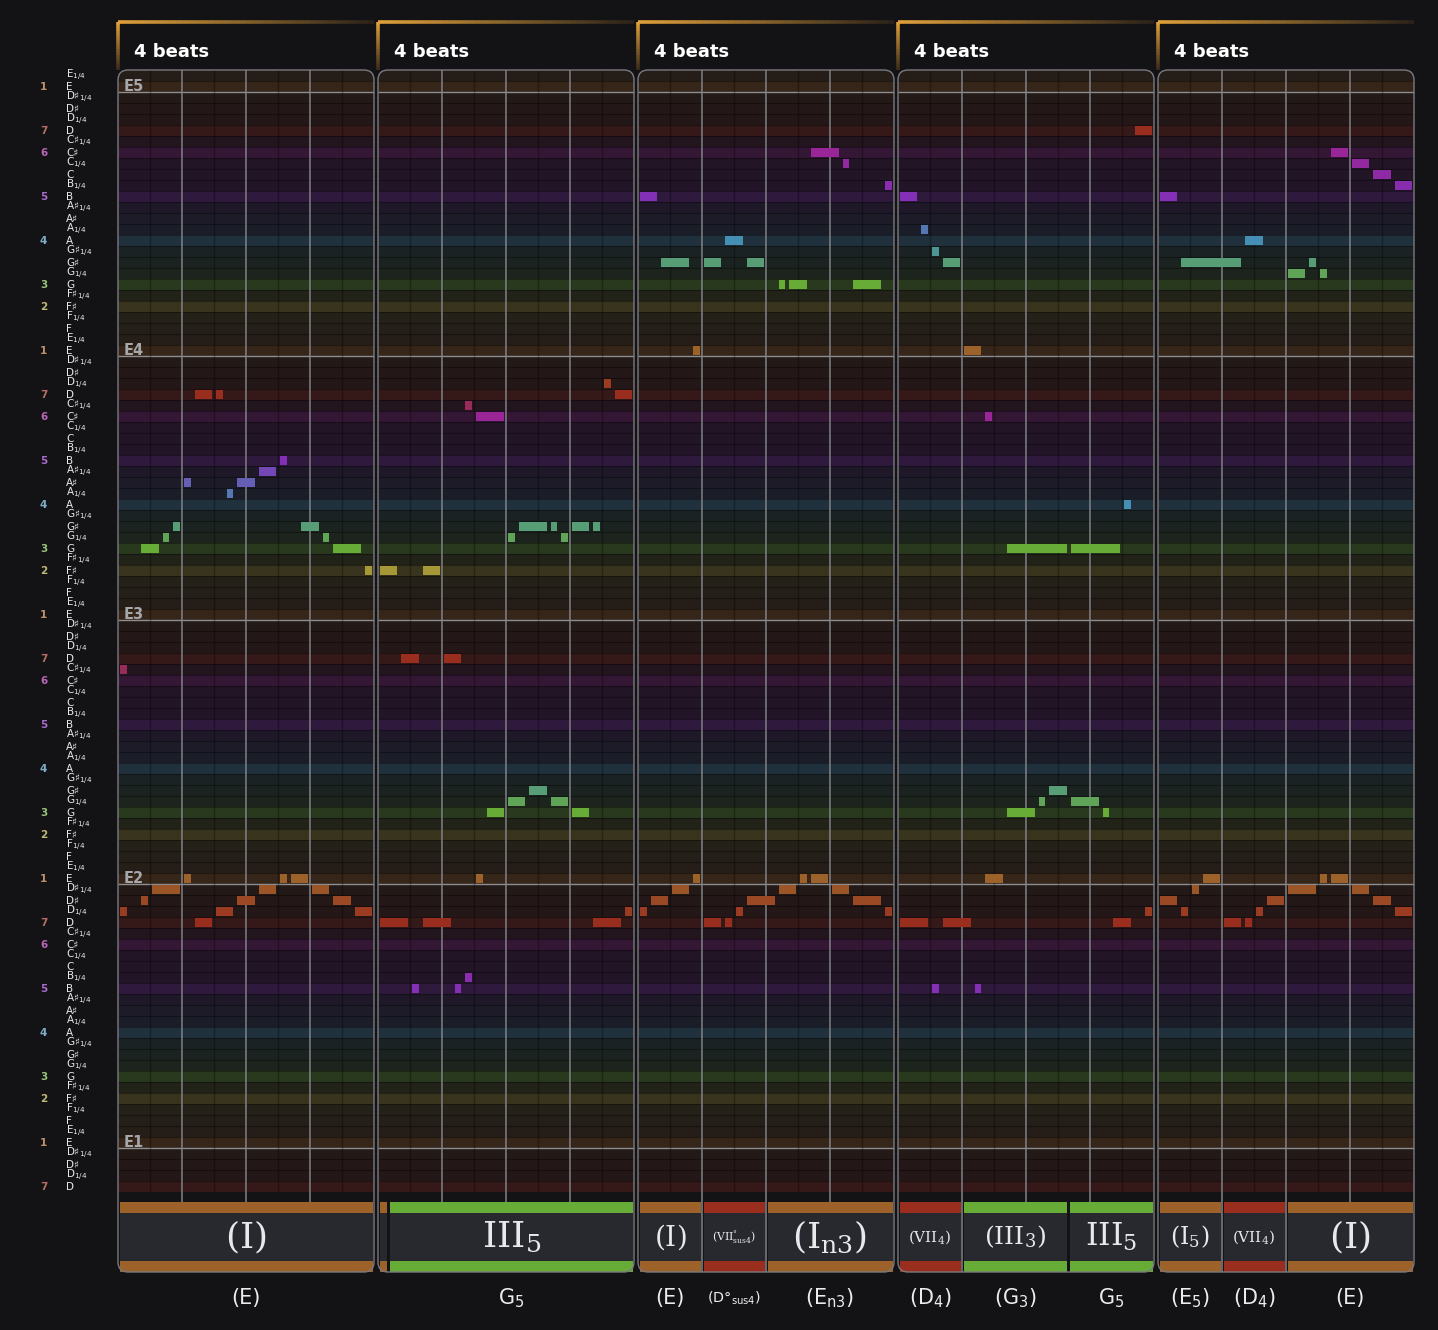

Página 19/30 · compases 73–77 · 2:52 – 3:02 · pulsos por compás: [4, 4, 4, 4, 4]


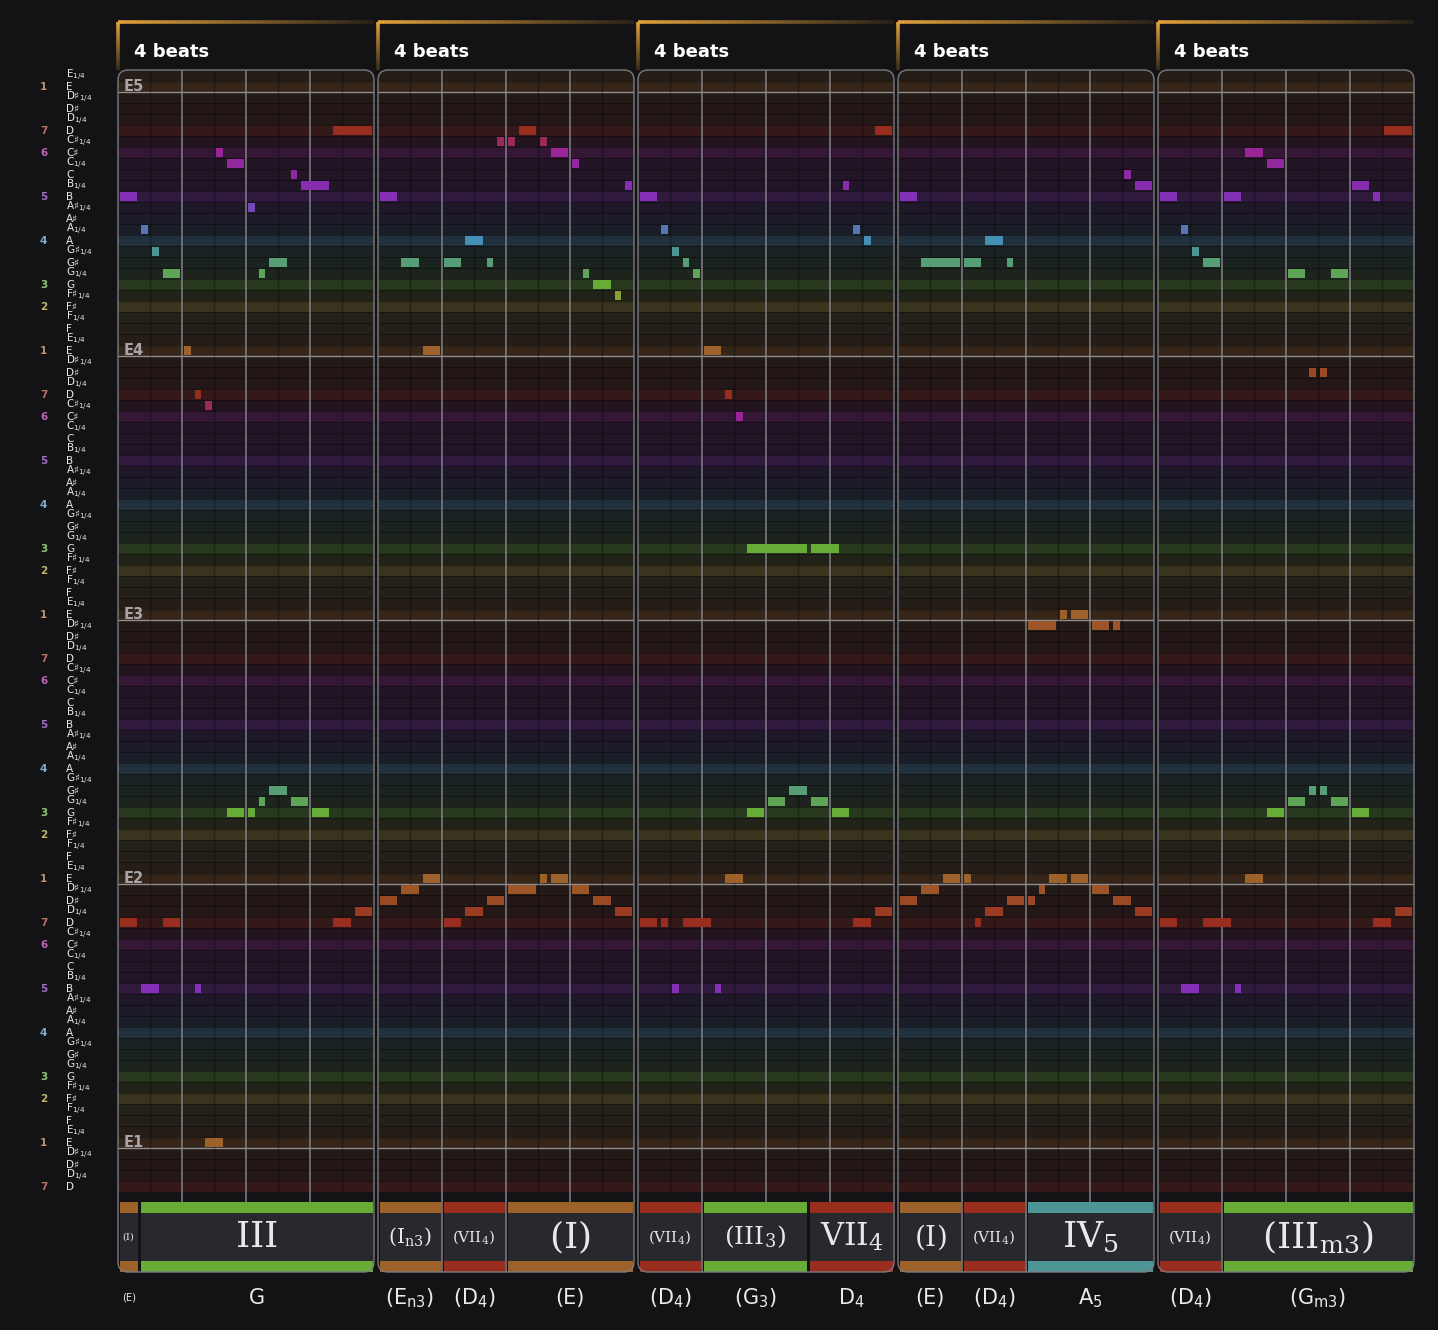

Página 20/30 · compases 78–82 · 3:02 – 3:12 · pulsos por compás: [4, 4, 4, 4, 4]


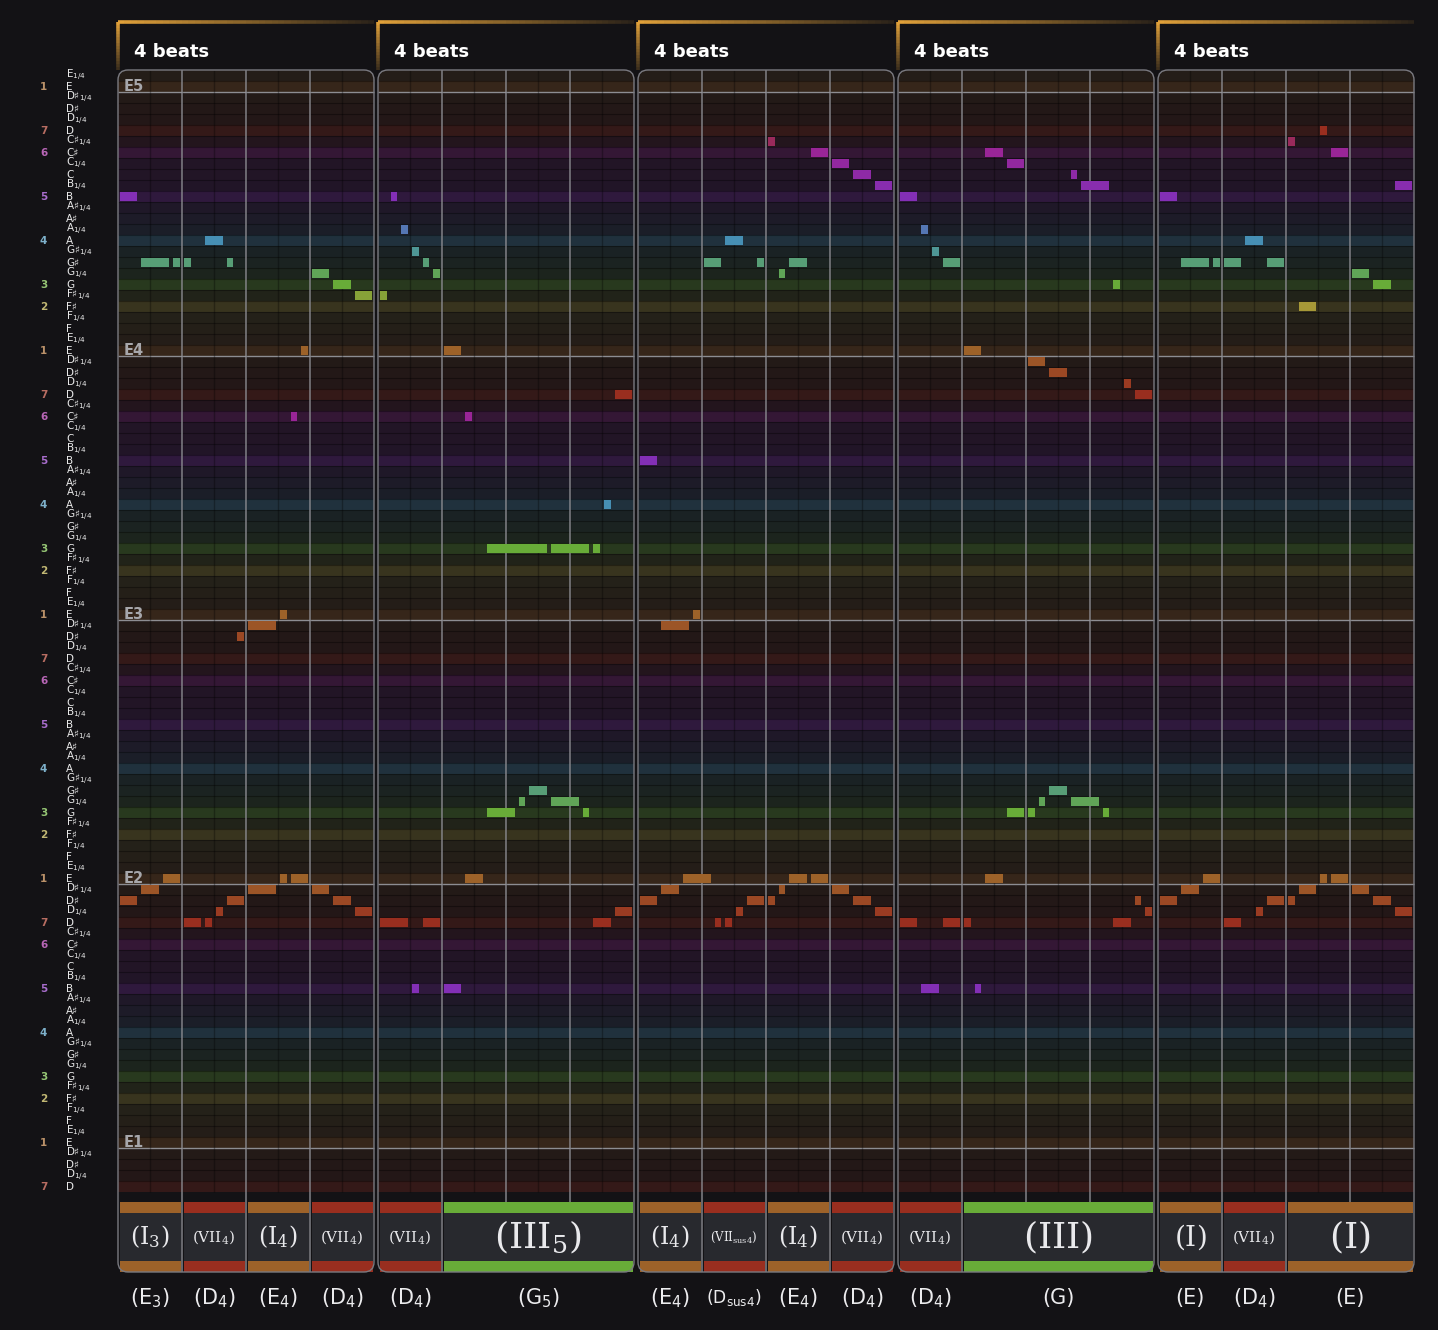

Página 21/30 · compases 83–87 · 3:12 – 3:23 · pulsos por compás: [4, 4, 4, 4, 4]


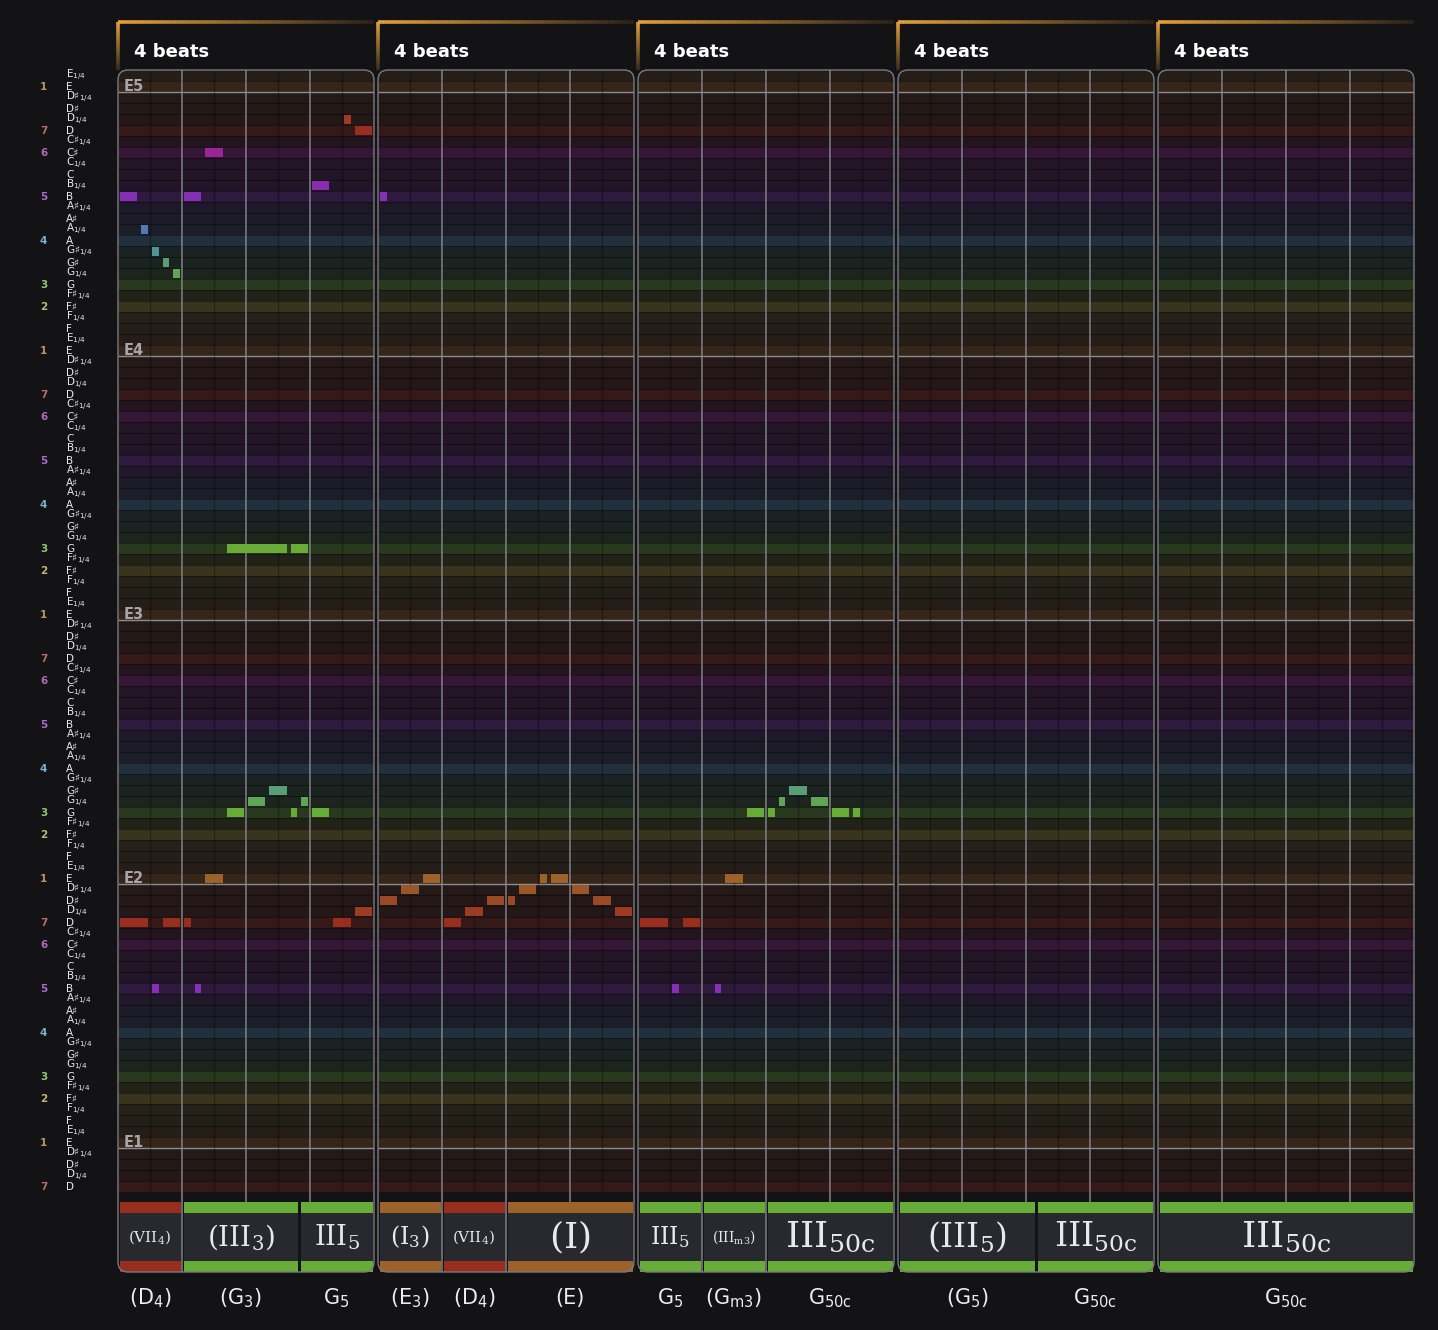

Página 22/30 · compases 88–91 · 3:23 – 3:31 · pulsos por compás: [4, 4, 4, 4]


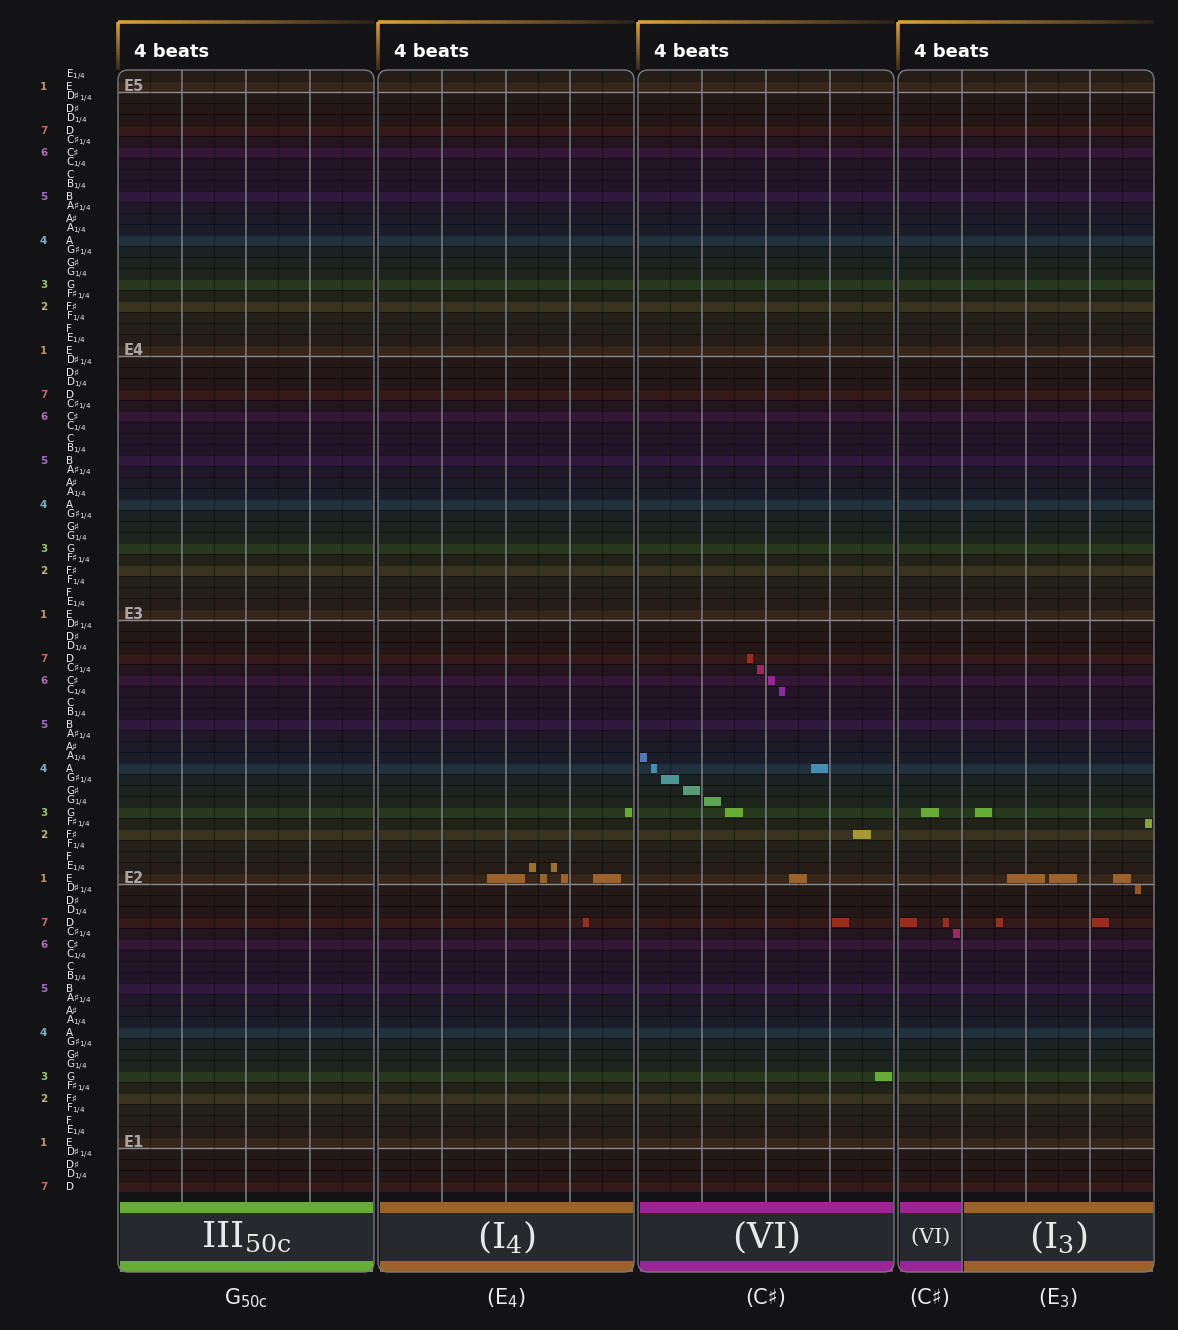

Página 23/30 · compases 92–93 · 3:31 – 3:39 · pulsos por compás: [8, 8]


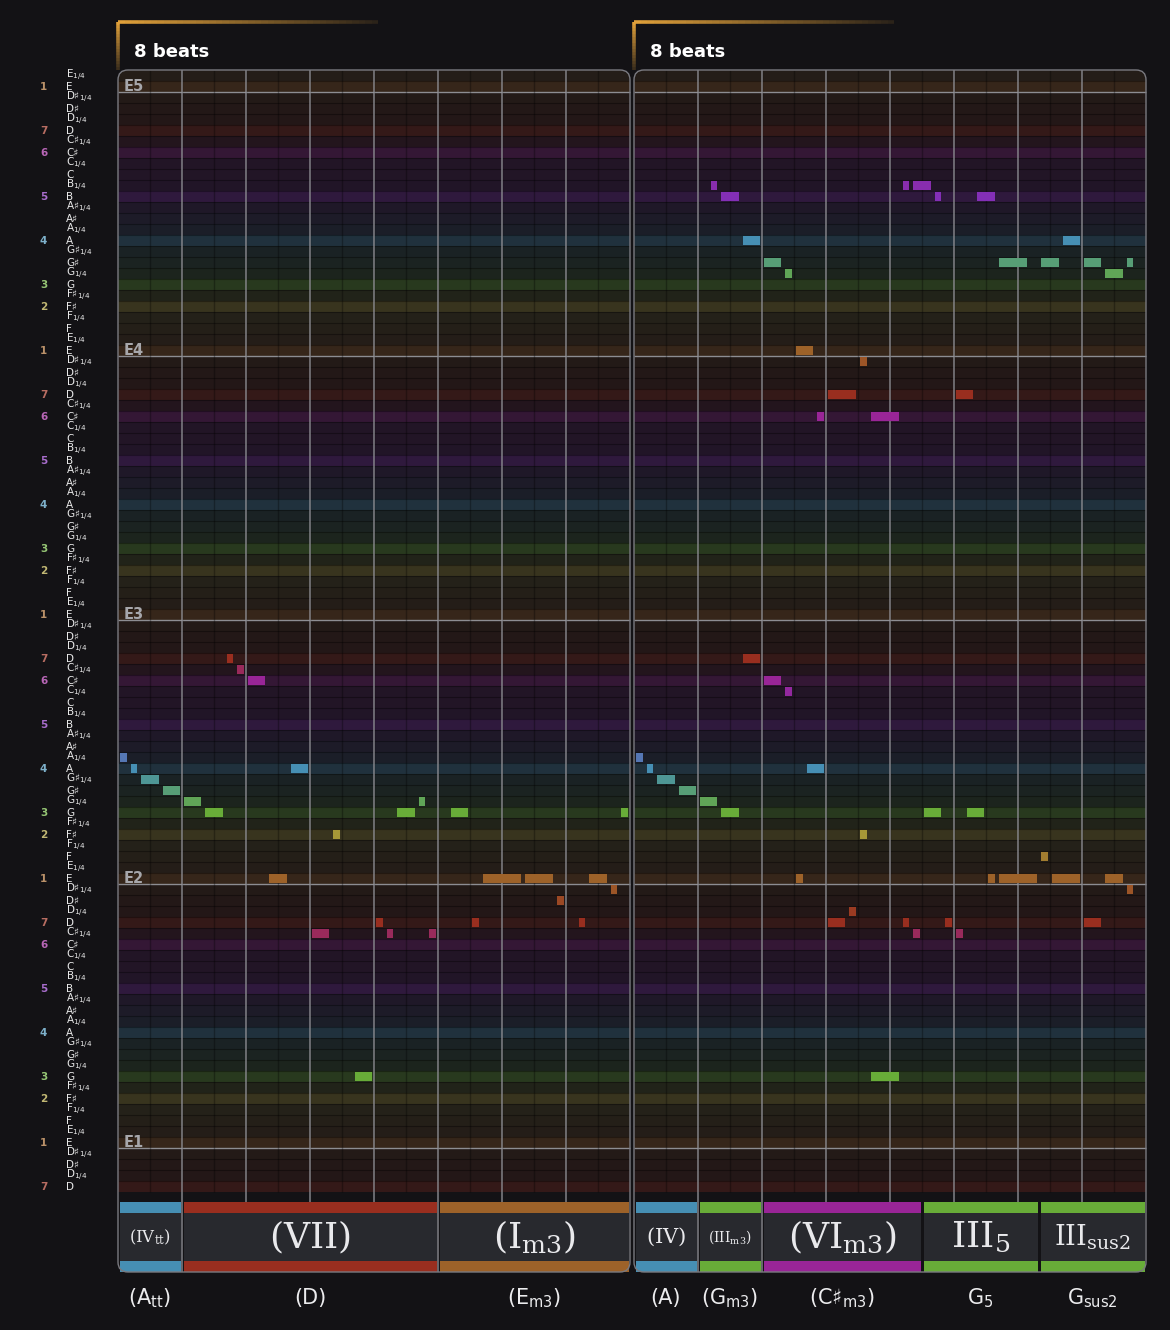

Página 24/30 · compases 94–95 · 3:39 – 3:48 · pulsos por compás: [8, 8]


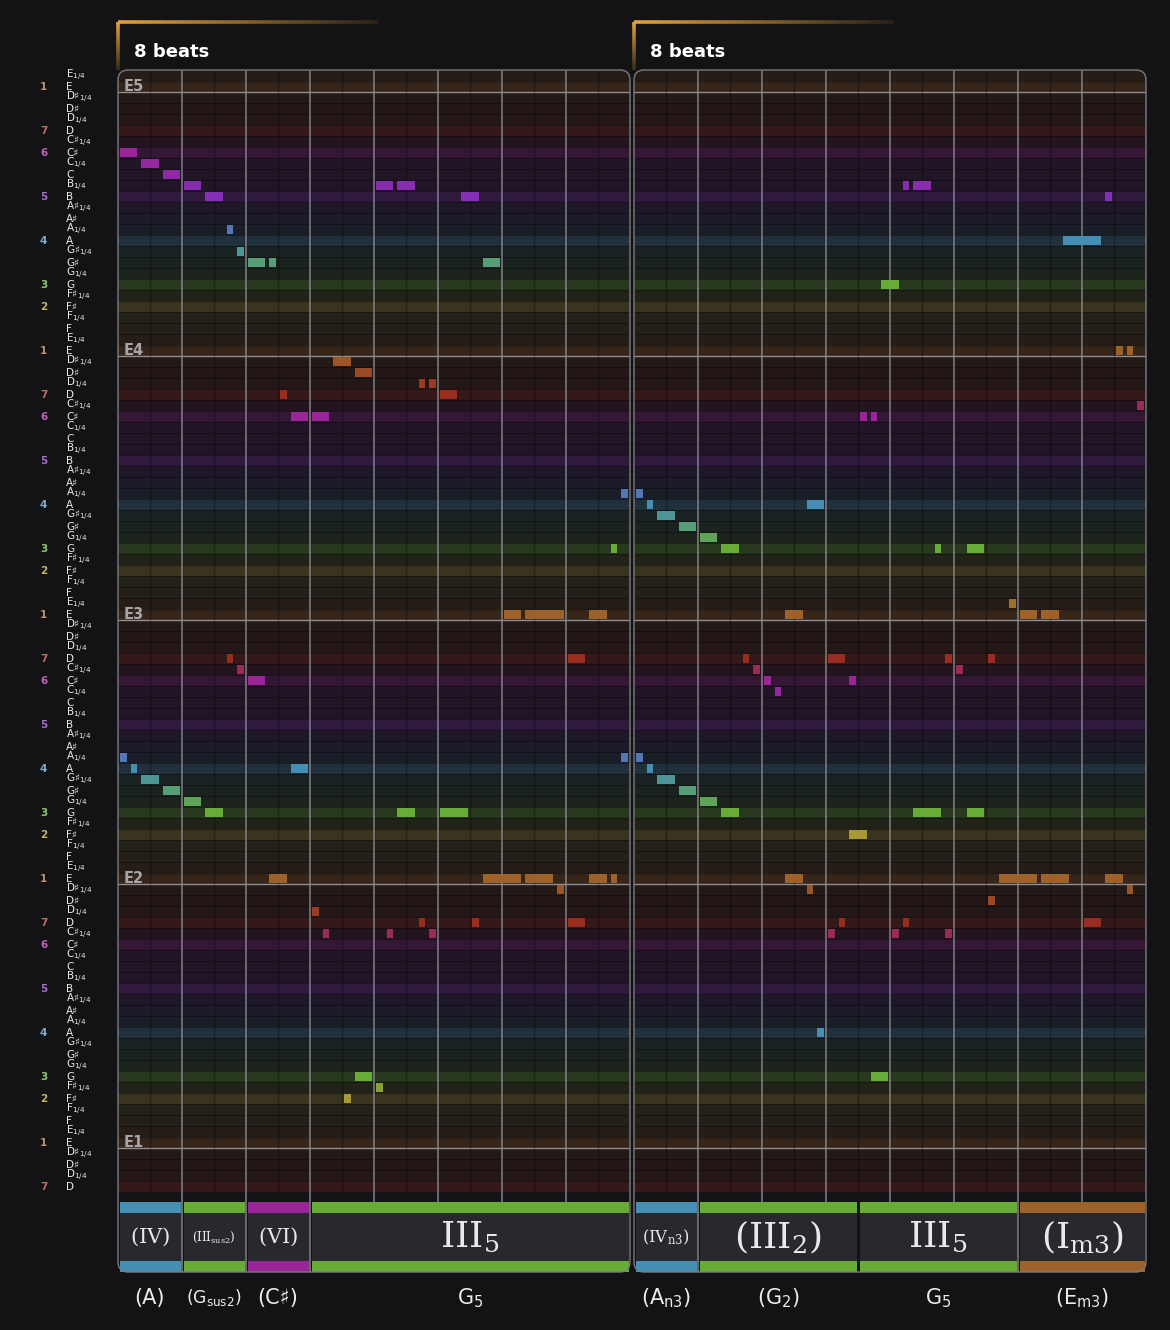

Página 25/30 · compases 96–97 · 3:48 – 3:56 · pulsos por compás: [8, 8]


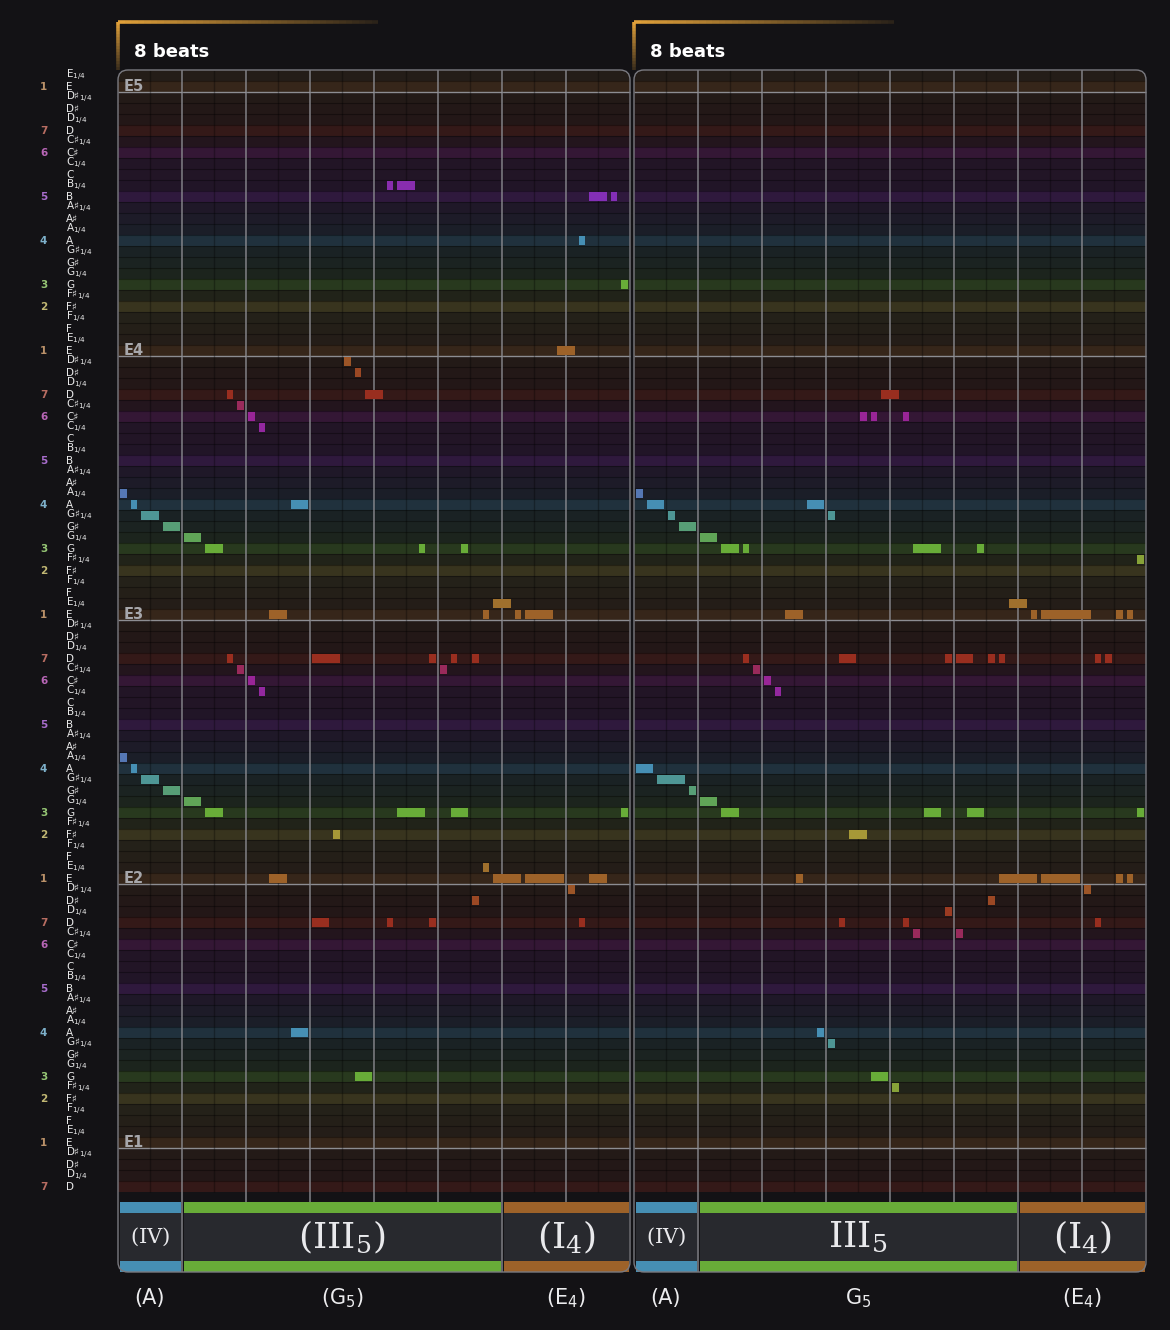

Página 26/30 · compases 98–99 · 3:56 – 4:04 · pulsos por compás: [8, 8]


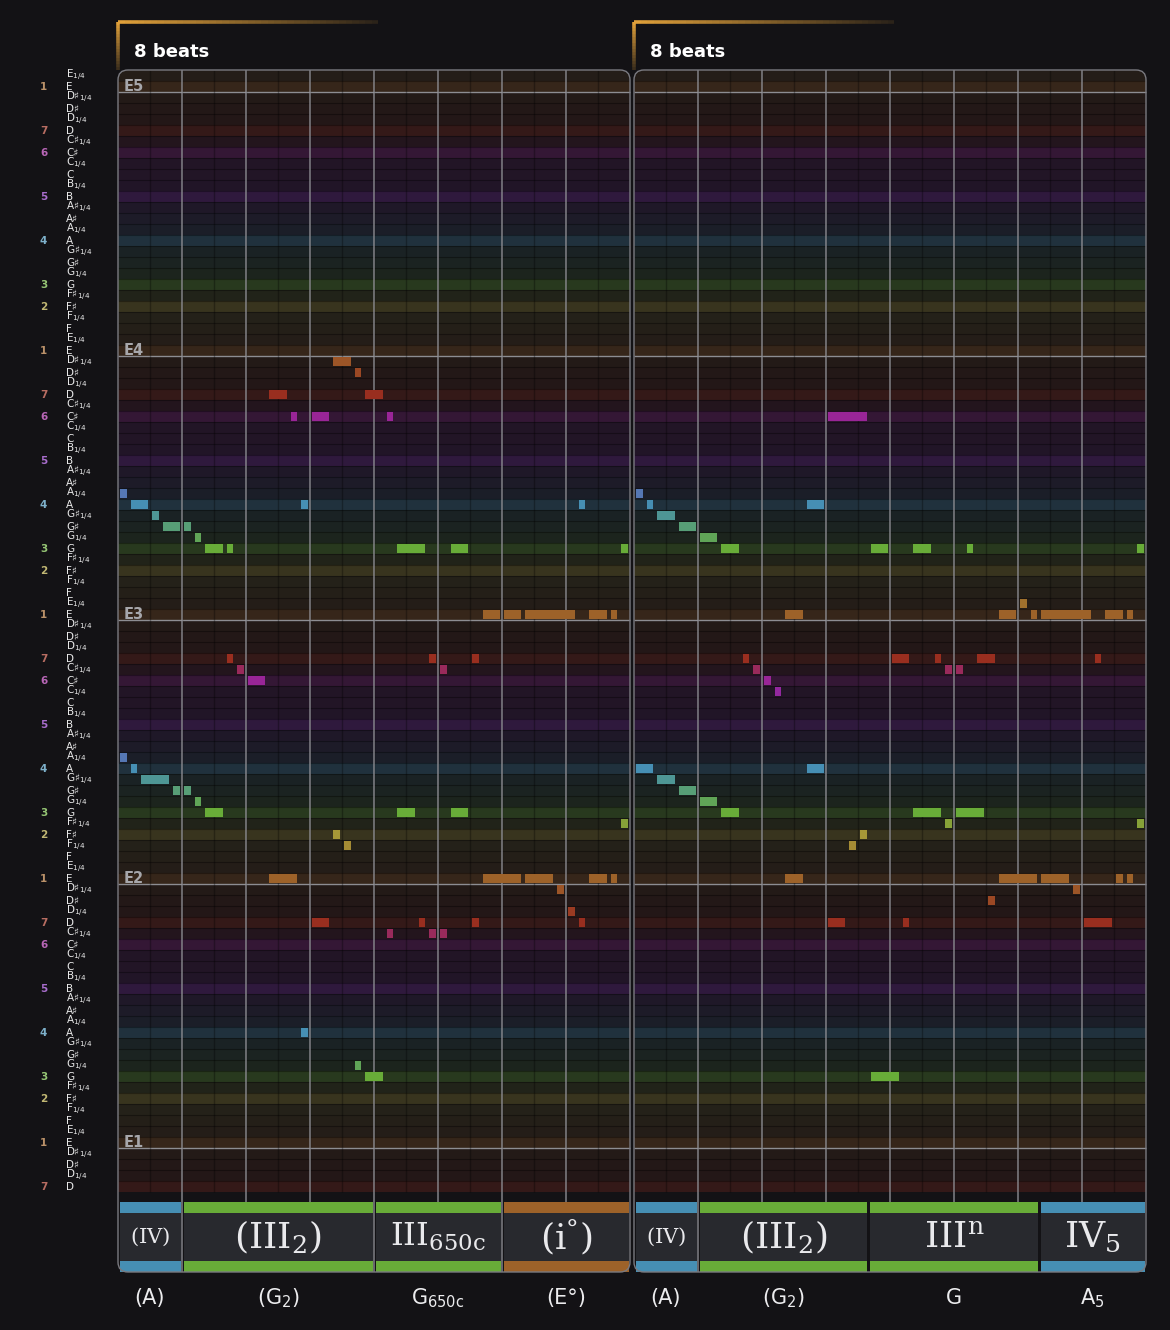

Página 27/30 · compases 100–101 · 4:04 – 4:12 · pulsos por compás: [8, 8]


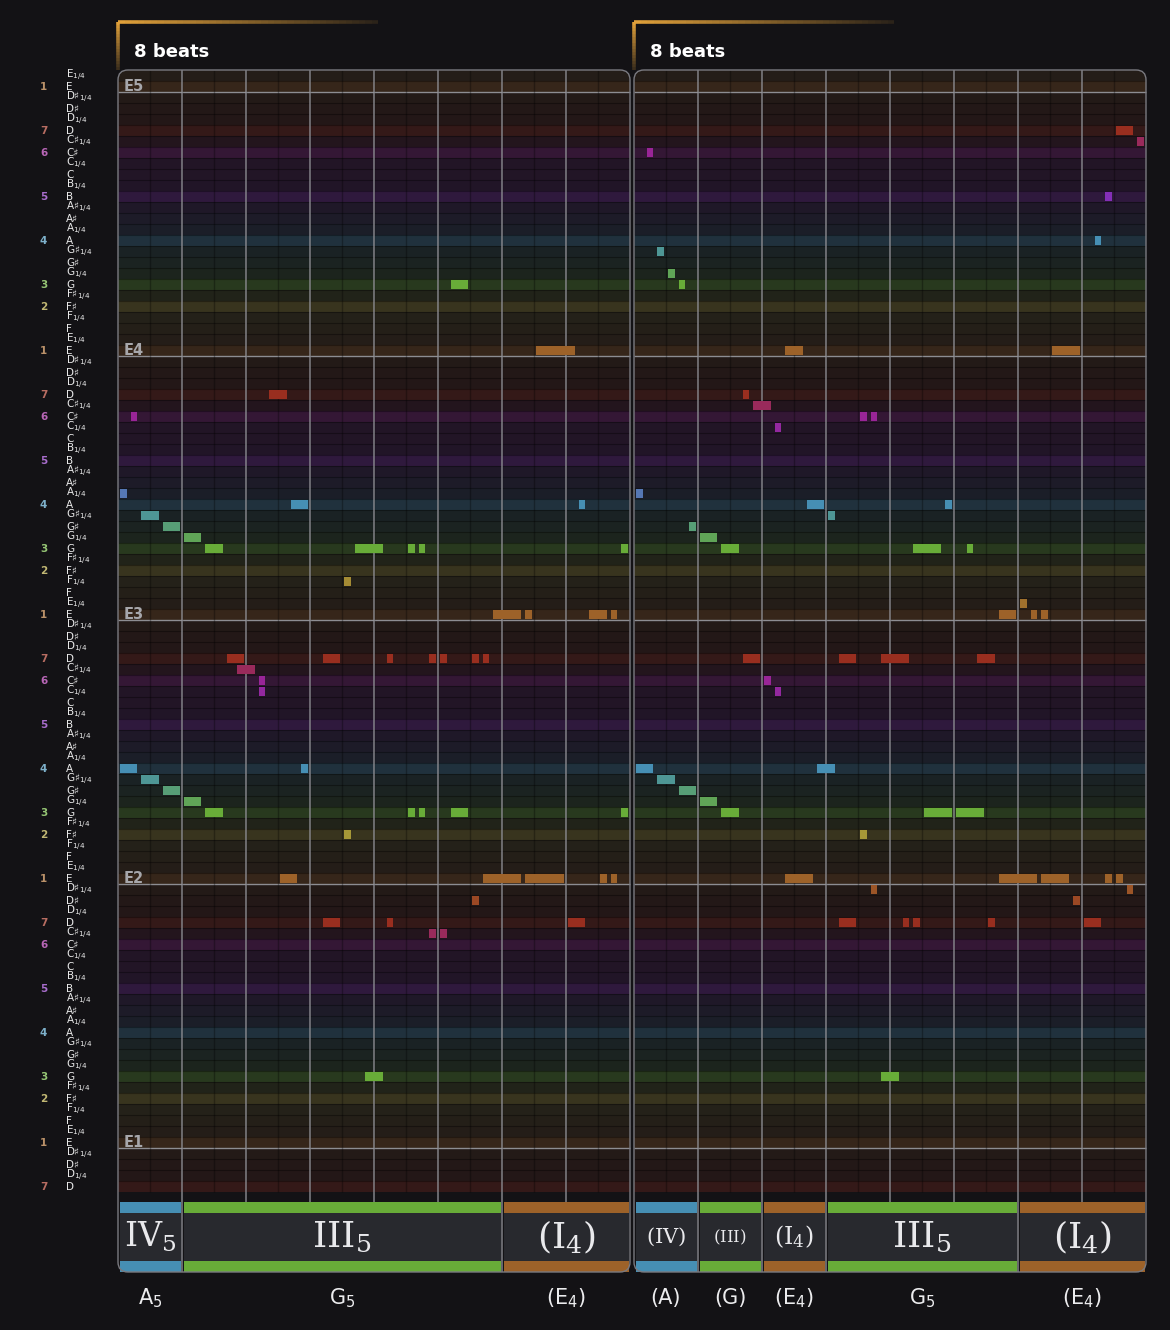

Página 28/30 · compases 102–103 · 4:12 – 4:21 · pulsos por compás: [8, 8]


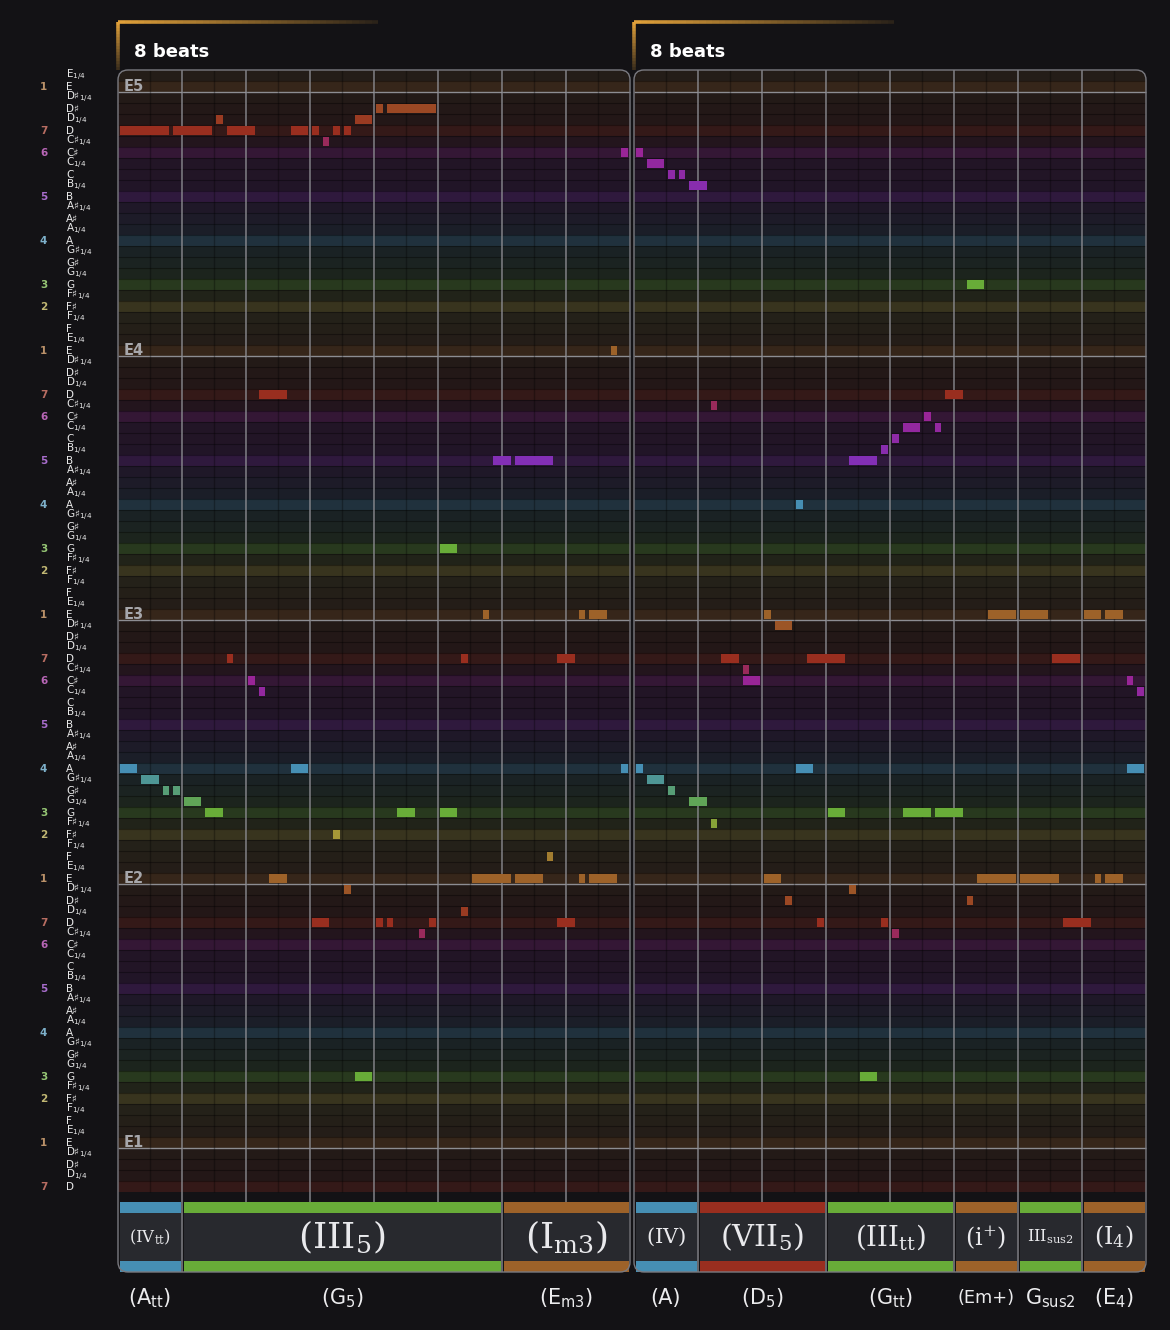

Página 29/30 · compases 104–107 · 4:21 – 4:31 · pulsos por compás: [8, 4, 4, 4]


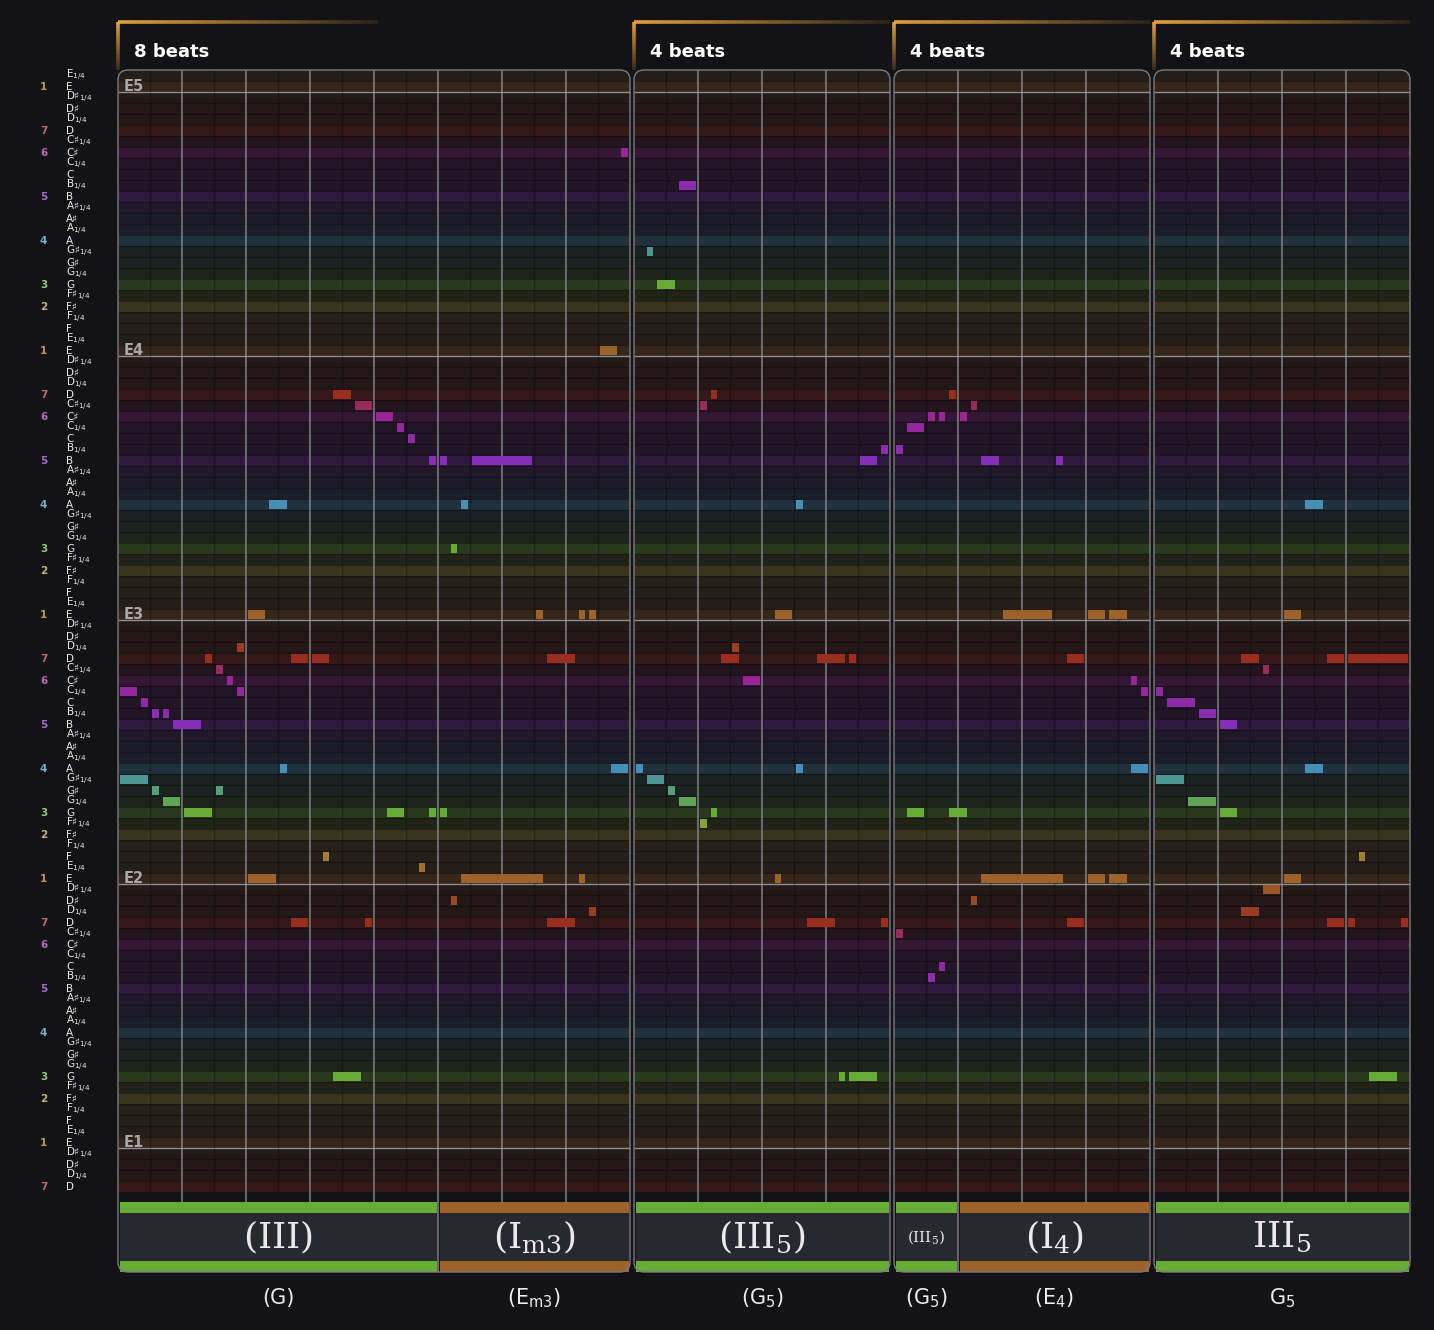

Página 30/30 · compases 108–109 · 4:31 – 4:35 · pulsos por compás: [4, 3]


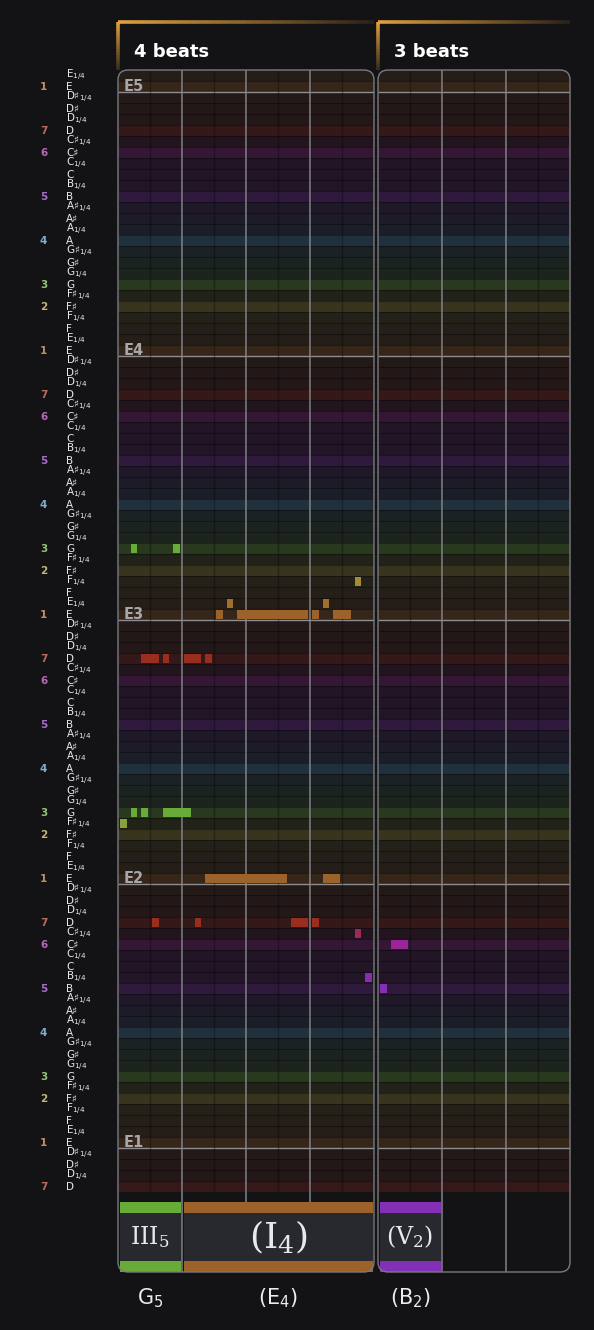

Guardado: 30 páginas en /content/harmony_outputs | imagen completa: angine_harmony_completo_1.png, angine_harmony_completo_2.png


In [179]:
graphic_paths = render_song_graphic()

Ahora, pasemos a visualizar los ciclos melodicos que tiene la cancion:

Voz grave
  A  0:00 – 0:16  |  4.133 s  |  2 compases  |  4 vueltas  |  se repite 92%
  B  0:18 – 1:49  |  8.278 s  |  4 compases  |  11 vueltas  |  se repite 96%
  B  1:55 – 3:18  |  4.139 s  |  2 compases  |  20 vueltas  |  se repite 99%
  C  3:24 – 4:34  |  4.139 s  |  1 compases  |  17 vueltas  |  se repite 92%
Voz aguda
  A  0:26 – 1:07  |  8.278 s  |  4 compases  |  5 vueltas  |  se repite 94%  |  dobla al bajo
  B  1:07 – 2:13  |  8.278 s  |  4 compases  |  8 vueltas  |  se repite 90%
  C  2:13 – 3:03  |  8.278 s  |  4 compases  |  6 vueltas  |  se repite 83%
  D  3:44 – 4:09  |  4.138 s  |  1 compases  |  6 vueltas  |  se repite 82%  |  dobla al bajo
  E  4:10 – 4:35  |  8.290 s  |  4 compases  |  3 vueltas  |  se repite 62%
Capas de guitarra (loop de 8.278 s): entra 0:29  entra 1:06  sale 1:37  entra 1:57  sale 2:07  entra 2:17  sale 2:42  entra 2:58  sale 3:12  entra 3:39  entra 4:03  entra 4:19  sale 4:31


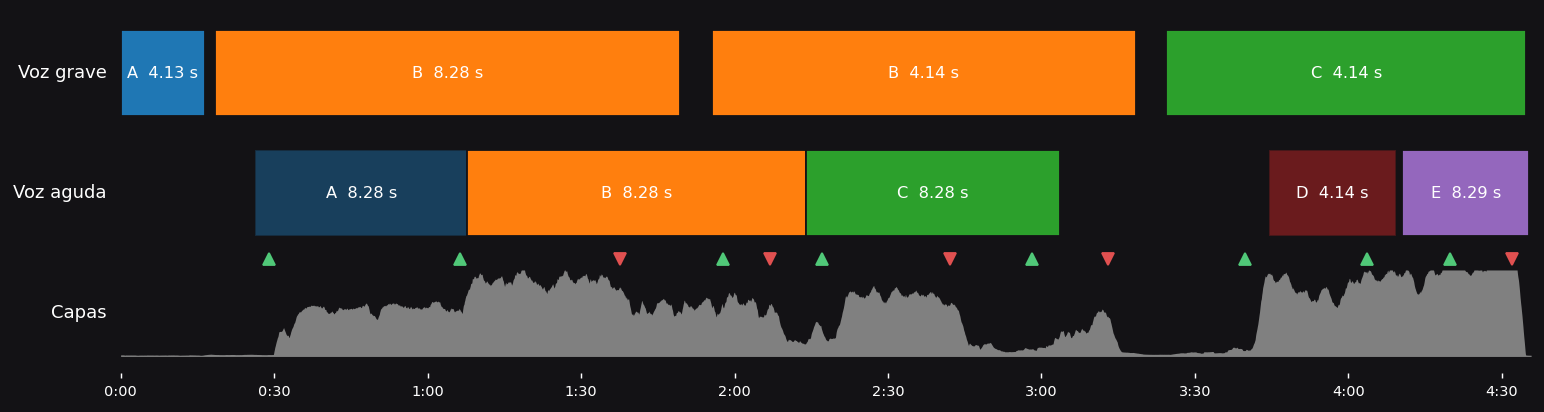

Ciclo A · 4.133 s · 0:00 – 0:16


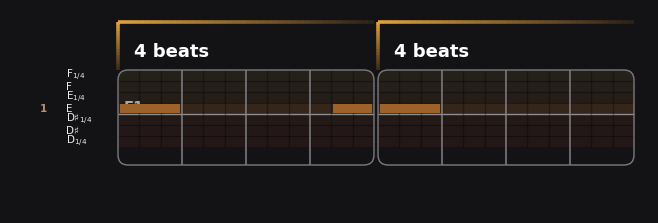

Ciclo B · 8.278 s · 0:18 – 1:49


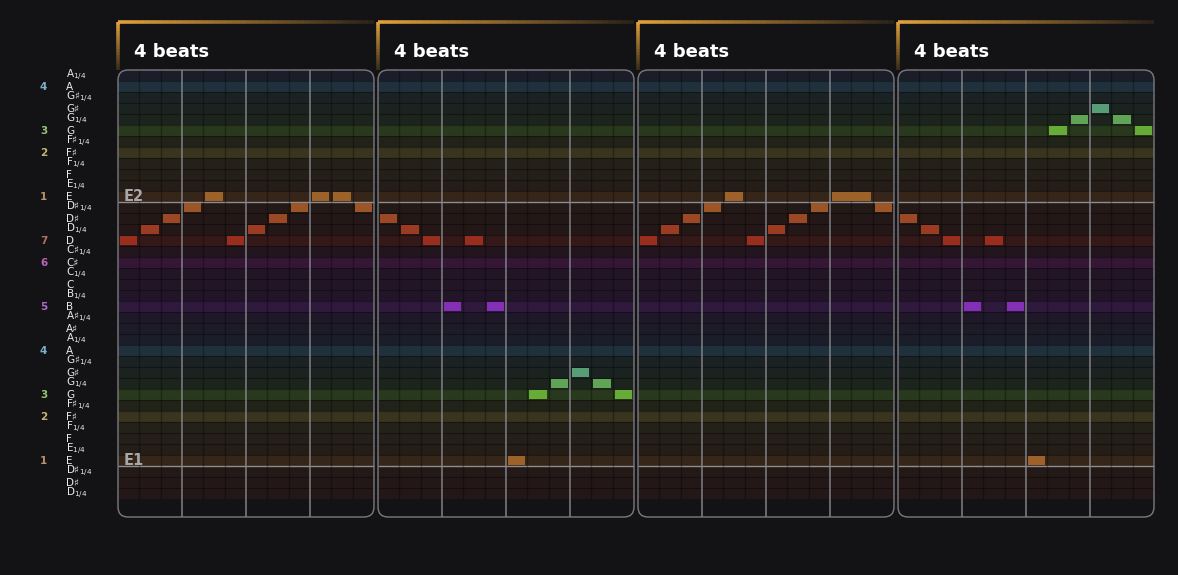

Ciclo C · 4.139 s · 3:24 – 4:34


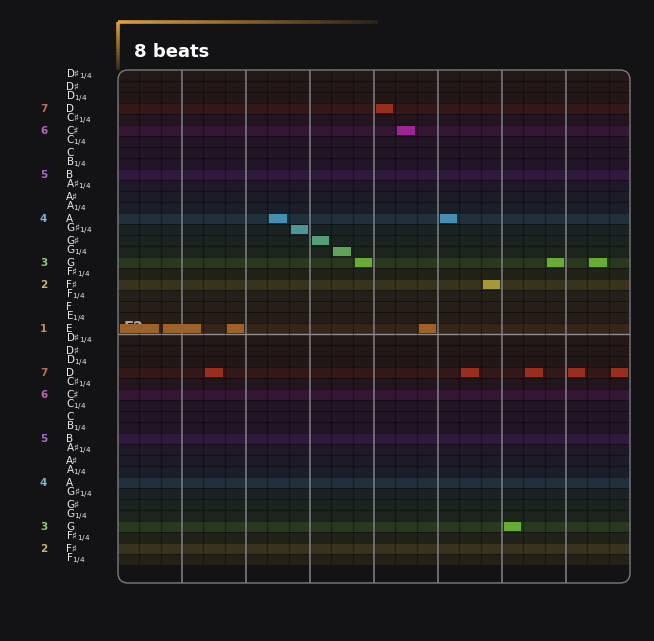

Ciclo A · 8.278 s · 0:26 – 1:07


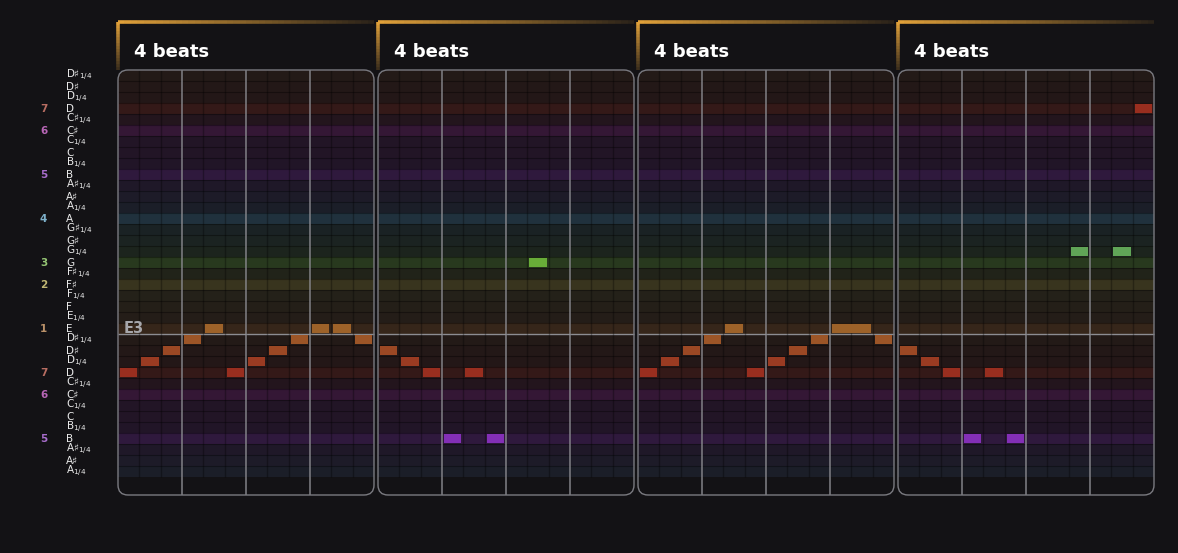

Ciclo B · 8.278 s · 1:07 – 2:13


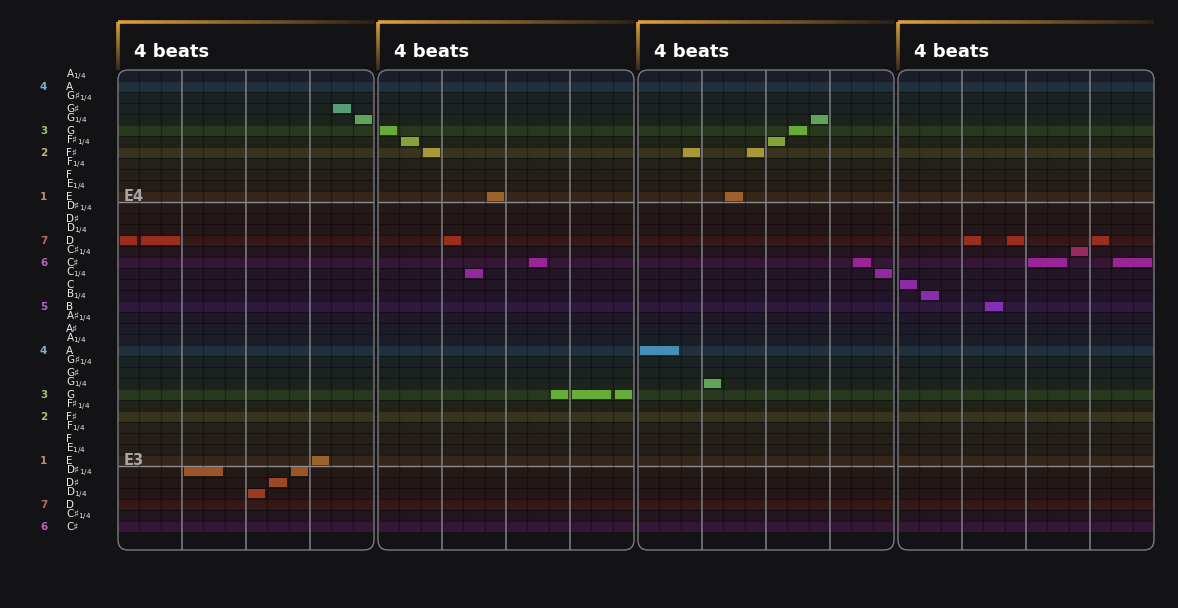

Ciclo C · 8.278 s · 2:13 – 3:03


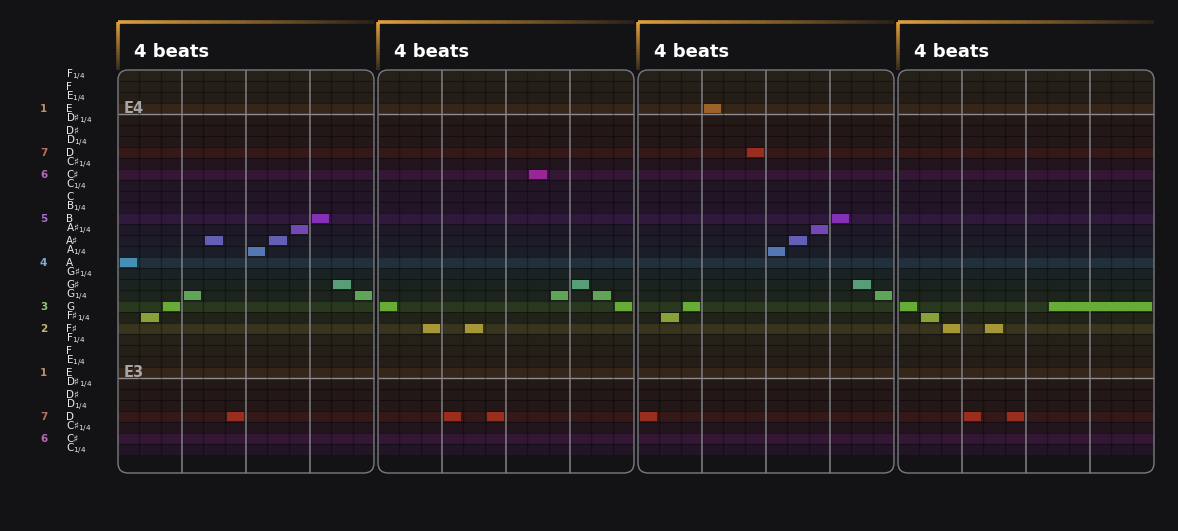

Ciclo D · 4.138 s · 3:44 – 4:09


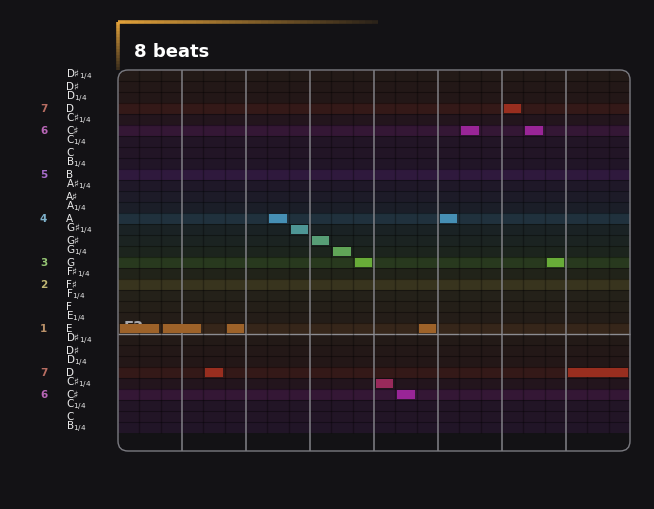

Ciclo E · 8.290 s · 4:10 – 4:35


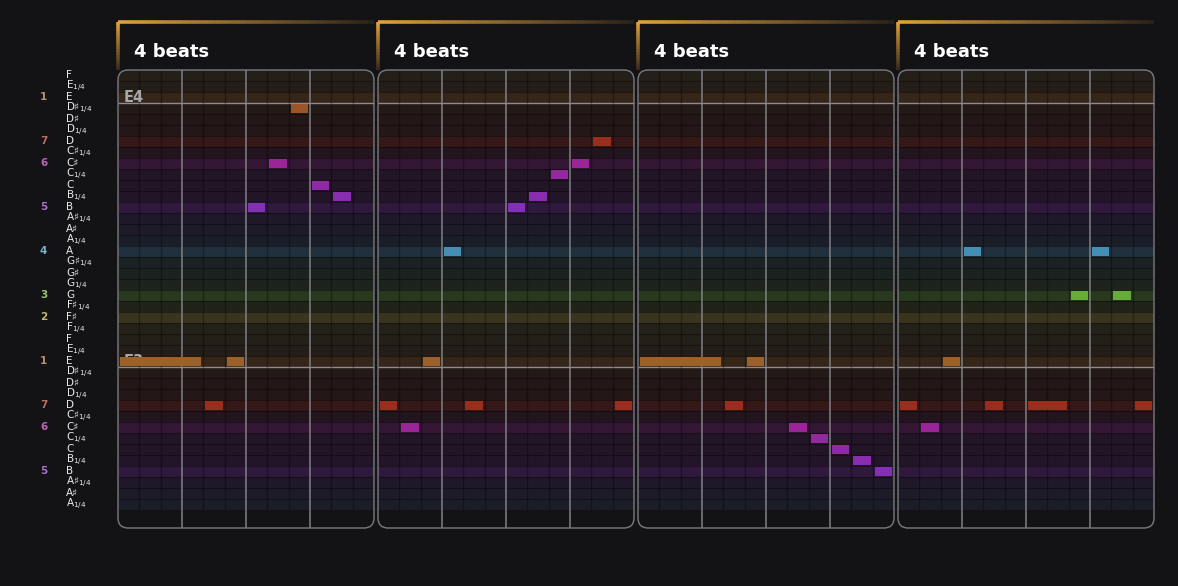

In [180]:
beat = (beat_times[-1] - beat_times[0]) / (len(beat_times) - 1)

lines_v = {'Voz grave': bass, 'Voz aguda': melody}
cycles = {voice: find_cycles(line, off, sr, HOP_P, min_turns=2 if line is bass else 3) for voice, line in lines_v.items()}
main = 'Voz grave' if cycles['Voz grave'] else 'Voz aguda'

sub = BEAT_DIV if BEAT_DIV > 1 else cycle_subdivision(lines_v[main], off, cycles[main], sr, HOP_P, beat)
bar = max(set(lens), key=lens.count)
bar_of = lambda c: cycle_bar(c, lens, beat_times, bar)

for voice, line in lines_v.items():
    prev, others = None, [] if voice == main else cycles[main]

    for c in cycles[voice]:
        fold_cycle(Sb if line is bass else Sh, cand, line, off, c, sr, HOP_P, beat, sub, 'grave' if line is bass else 'aguda', cycle_anchor(c, prev, others), stereo=Sh is not S, weak=0.0 if Sh is not S else 0.8)
        prev = c

    cycles[voice] = [c for c in cycles[voice] if has_motion(c) and (line is bass or stem is None or stem_active(stem, c, sr) >= 0.2)]
    name_cycles(cycles[voice])
    print(voice)

    for c in cycles[voice]:
        print(f'  {c.label}  {_mmss(c.start)} – {_mmss(c.end)}  |  {c.period:.3f} s  |  {c.slots / sub / bar_of(c):g} compases  |  '
              f'{(c.end - c.start) / c.period:.0f} vueltas  |  se repite {c.score:.0%}' + ('  |  dobla al bajo' if c.doubled >= 0.8 else ''))

layers = None

if stem is not None:                                                               # con la pista guitar se ven las capas del looper
    loop = loop_period(cycles)
    layer_events, level = layer_changes(stem, loop, sr, HOP_P, NFFT_P)
    layers = (layer_events, level, HOP_P / sr)

    print(f'Capas de guitarra (loop de {loop:.3f} s): ' + '  '.join(f'{k} {_mmss(t)}' for t, k in layer_events))

plot_cycle_map(cycles, len(y) / sr, layers=layers)

for voice, group in cycles.items():
    render_cycles([c for c in group if c.doubled < 0.8 or Sh is not S], view_scale, tonic_midi, bar_of, filename=f'ciclo_{voice.split()[1]}')

### Para explorar otra parte

```python
render_song_graphic(start_s=90, duration_s=90, filename='angine_harmony_90s')
```

Las imágenes quedan en `harmony_outputs/<canción>/`, en la raíz del proyecto (en Colab, en el panel de archivos): las páginas, `angine_harmony_completo.png` con la canción entera en una sola imagen (si es muy larga se parte en `..._completo_1.png`, `..._completo_2.png`...), el mapa de ciclos y cada ciclo. Cada vez que se corre el cuaderno, las imágenes de esa canción se reemplazan.

### Ajustes útiles (celda de ajustes)

- `KEY_OVERRIDE = ('E', 'dorian')`: fuerza la tonalidad si la detección automática se equivoca.
- `FORCE_BAR_BEATS = 4` (o `[4, 3]`): fija la duración de los compases en lugar de estimarla.
- `MICRO_STEP = 100`: sin cuartos de tono (solo semitonos).


Circulo armonico: Estructura que compone una melodia por medio de un arreglo. Es muy a voluntad del compositor siempre y cuando respete las reglas, los parametros de la armonia que estoy utilizando

- Cadencia (cierre para pasar a una nueva modalidad o para empezar un nuevo ciclo) (final de una frase para repetir o para pasar a otra tonalidad)

- Modulaciones
- Acordes pivotes
-Forma binaria de 8 compases (la tabla del 4) cada 8 compases

- Cadencia rota es que el ultimo acorde del ciclo cambio.

- Armar progresiones y ejemplos.

- Un ejemplo es tomar cada grado de la escala (cada nota de la escala)

- Tonica, menor, disminuida (sensible), subtonica, mediante, dominante, subdominante
